# Heart Disease Prediction:

#Project created by Chetan Patil

# SECTION 1: Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px # Optional, as requested
import warnings
import joblib
import plotly # Explicitly import plotly for version display

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

import scipy
import sklearn # Explicitly import sklearn for version display
import matplotlib # Explicitly import matplotlib to get its version

# Suppress warnings
warnings.filterwarnings('ignore')

print('SECTION 1: Import Libraries - Summary')


# Display library versions
print(f"Numpy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")
print(f"Plotly version: {plotly.__version__}") # Corrected to use plotly.__version__
print(f"Scipy version: {scipy.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print(f"Joblib version: {joblib.__version__}")

print("\nWhat is happening: All necessary Python libraries for data manipulation, visualization, machine learning, and model persistence are imported.")
print("Why it is required: Importing libraries is the first essential step in any Python project, providing access to functions and tools for various tasks.")
print("Expected output: The versions of the imported libraries will be displayed.")
print("Importance in Data Science: This ensures that the environment is set up correctly and all dependencies are met, which is crucial for reproducibility and avoiding compatibility issues.")


SECTION 1: Import Libraries - Summary
Numpy version: 2.0.2
Pandas version: 2.2.2
Matplotlib version: 3.10.0
Seaborn version: 0.13.2
Plotly version: 5.24.1
Scipy version: 1.16.3
Scikit-learn version: 1.6.1
Joblib version: 1.5.3

What is happening: All necessary Python libraries for data manipulation, visualization, machine learning, and model persistence are imported.
Why it is required: Importing libraries is the first essential step in any Python project, providing access to functions and tools for various tasks.
Expected output: The versions of the imported libraries will be displayed.
Importance in Data Science: This ensures that the environment is set up correctly and all dependencies are met, which is crucial for reproducibility and avoiding compatibility issues.



# SECTION 2: Load Data and Merge


In [ ]:

print('SECTION 2: Load Data and Merge - Summary')

# What is happening: Loading two CSV files, 'values.csv' and 'labels.csv', into pandas DataFrames.
# Why it is required: These files contain the features and the target variable for the heart disease prediction project.
# Expected output: Two pandas DataFrames (df_values, df_labels) will be created.
# Importance in Data Science: This is the initial step of data acquisition, bringing raw data into a structured format for analysis.

# Load values.csv
df_values = pd.read_csv('/dataset/values.csv') # Corrected file path
print("\nSuccessfully loaded 'values.csv'.")

# Load labels.csv
df_labels = pd.read_csv('/dataset/labels.csv') # Corrected file path
print("Successfully loaded 'labels.csv'.")

# What is happening: Merging the 'df_values' and 'df_labels' DataFrames based on the 'patient_id' column.
# Why it is required: The features and target variable are in separate files, and merging them creates a single, comprehensive dataset for analysis.
# Expected output: A new DataFrame 'df' containing all features and the target variable, aligned by 'patient_id'.
# Importance in Data Science: Data integration is critical for creating a unified view of the data, which is necessary before any meaningful analysis or model training can begin.

df = pd.merge(df_values, df_labels, on='patient_id', how='inner')
print("Successfully merged 'values.csv' and 'labels.csv' on 'patient_id'.")

print('Dataset Information after Merge')

# What is happening: Displaying the shape (number of rows and columns) of the merged DataFrame.
# Why it is required: To quickly understand the dimensions of the dataset and confirm the merge operation was successful.
# Expected output: A tuple showing (number of rows, number of columns).
# Importance in Data Science: Provides a high-level overview of the data size, which is fundamental for initial data assessment.
print(f"\nDataset shape: {df.shape}")

# What is happening: Displaying the first 5 rows of the DataFrame.
# Why it is required: To get a quick preview of the data structure, column names, and sample values.
# Expected output: A table showing the header and the first 5 rows of the DataFrame.
# Importance in Data Science: Essential for initial data inspection and to ensure data has been loaded correctly.
print("\nHead of the dataset:")
display(df.head())

# What is happening: Displaying the last 5 rows of the DataFrame.
# Why it is required: To check for any potential anomalies or patterns at the end of the dataset.
# Expected output: A table showing the last 5 rows of the DataFrame.
# Importance in Data Science: Helps in verifying data integrity, especially if data loading involves sorting or specific orderings.
print("\nTail of the dataset:")
display(df.tail())

# What is happening: Displaying 5 random rows from the DataFrame.
# Why it is required: To get a more generalized view of the data distribution and values, avoiding potential biases from just the head or tail.
# Expected output: A table showing 5 random rows of the DataFrame.
# Importance in Data Science: Offers a representative sample of the data, useful for discovering variations or inconsistencies.
print("\nRandom 5 rows of the dataset:")
display(df.sample(5))

# What is happening: Displaying the data types of each column in the DataFrame.
# Why it is required: To identify the data type inferred by pandas for each column and check if it's appropriate for the data it holds.
# Expected output: A list of columns with their corresponding data types (e.g., int64, float64, object).
# Importance in Data Science: Correct data types are crucial for performing accurate operations and memory efficiency. Incorrect types can lead to errors in analysis or model training.
print("\nData types of the dataset:")
display(df.info())

# What is happening: Displaying the memory usage of the DataFrame.
# Why it is required: To understand the memory footprint of the dataset, which is important for performance optimization, especially with large datasets.
# Expected output: The total memory usage in bytes, and optionally memory usage per column.
# Importance in Data Science: Helps in managing computational resources and identifying potential memory-intensive columns or data types that might need optimization.
print("\nMemory usage of the dataset:")
display(df.memory_usage(deep=True))

SECTION 2: Load Data and Merge - Summary

Successfully loaded 'values.csv'.
Successfully loaded 'labels.csv'.
Successfully merged 'values.csv' and 'labels.csv' on 'patient_id'.
Dataset Information after Merge

Dataset shape: (180, 15)

Head of the dataset:


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0



Tail of the dataset:


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0
179,2nx10r,1,normal,160,3,1,0,0,201,0.0,0,54,163,0,0



Random 5 rows of the dataset:


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
62,pwigd8,3,reversible_defect,130,4,0,1,2,283,1.6,1,56,103,1,1
83,v52zcs,2,reversible_defect,128,4,2,0,2,259,3.0,1,58,130,1,1
101,9f92et,2,normal,140,2,0,0,2,294,1.3,0,56,153,0,0
10,ldg4b9,2,normal,120,4,0,0,2,302,0.4,1,66,151,0,0
97,z5g5p3,2,normal,160,1,1,1,2,234,0.1,1,69,131,0,0



Data types of the dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int6

None


Memory usage of the dataset:


,0
Index,132
patient_id,9900
slope_of_peak_exercise_st_segment,1440
thal,10762
resting_blood_pressure,1440
chest_pain_type,1440
num_major_vessels,1440
fasting_blood_sugar_gt_120_mg_per_dl,1440
resting_ekg_results,1440
serum_cholesterol_mg_per_dl,1440


# SECTION 3: Perform Complete Dataset Understanding

In [ ]:
print('\n#########################################################')
print('SECTION 3: Perform Complete Dataset Understanding - Summary')
print('#########################################################')

# What is happening: Displaying the number of rows in the DataFrame.
# Why it is required: To quickly know the total number of patient records in the dataset.
# Expected output: An integer representing the row count.
# Importance in Data Science: Provides insight into the dataset size, crucial for performance considerations and representativeness.
print(f"\nNumber of rows: {df.shape[0]}")

# What is happening: Displaying the number of columns in the DataFrame.
# Why it is required: To quickly know the total number of features and the target variable.
# Expected output: An integer representing the column count.
# Importance in Data Science: Helps in understanding the dimensionality of the dataset.
print(f"Number of columns: {df.shape[1]}")

# What is happening: Displaying the names of all columns in the DataFrame.
# Why it is required: To review all available features and the target variable for understanding and planning further analysis.
# Expected output: A list of column names.
# Importance in Data Science: Essential for feature selection, data cleaning, and ensuring consistent naming.
print("\nColumn names:")
for col in df.columns:
    print(f"- {col}")

# What is happening: Identifying and displaying numerical columns.
# Why it is required: To separate continuous or discrete numerical features from categorical ones, which often require different preprocessing steps.
# Expected output: A list of numerical column names.
# Importance in Data Science: Facilitates specific analysis for numerical data, such as statistical summaries, scaling, and correlation analysis.
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("\nNumerical columns:")
for col in numerical_cols:
    print(f"- {col}")

# What is happening: Identifying and displaying categorical columns.
# Why it is required: To separate features representing categories or labels, which need specific encoding techniques before modeling.
# Expected output: A list of categorical column names.
# Importance in Data Science: Important for applying appropriate encoding methods (e.g., One-Hot Encoding, Label Encoding).
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print("\nCategorical columns:")
for col in categorical_cols:
    print(f"- {col}")

# What is happening: Identifying the target variable.
# Why it is required: To clearly define which column represents the outcome we are trying to predict.
# Expected output: The name of the target column.
# Importance in Data Science: Fundamental for supervised learning tasks, as it guides model training and evaluation.
target_variable = 'heart_disease_present'
print(f"\nTarget variable: {target_variable}")

# What is happening: Displaying unique values and their counts for all columns.
# Why it is required: To understand the diversity of data within each column, identify potential categorical features, or spot inconsistencies.
# Expected output: For each column, a list of unique values and their frequencies.
# Importance in Data Science: Crucial for data validation, identifying cardinality issues in categorical variables, and detecting typos or unexpected values.
print("\nUnique values for each column:")
for col in df.columns:
    if df[col].nunique() < 20: # Display unique values for columns with less than 20 unique values
        print(f"- {col} (Unique values: {df[col].unique().tolist()})")
        print(f"  Value Counts:\n{df[col].value_counts().to_string()}")
    else:
        print(f"- {col} (Number of unique values: {df[col].nunique()})")

# What is happening: Displaying data types of each column again (redundant but confirms post-merge types).
# Why it is required: To ensure data types are consistent and appropriate after any initial loading or merging operations.
# Expected output: A series showing each column and its dtype.
# Importance in Data Science: Correct data types are essential for efficient memory usage and proper function of many data science libraries.
print("\nData types of the dataset (re-check):")
display(df.dtypes)


#########################################################
SECTION 3: Perform Complete Dataset Understanding - Summary
#########################################################

Number of rows: 180
Number of columns: 15

Column names:
- patient_id
- slope_of_peak_exercise_st_segment
- thal
- resting_blood_pressure
- chest_pain_type
- num_major_vessels
- fasting_blood_sugar_gt_120_mg_per_dl
- resting_ekg_results
- serum_cholesterol_mg_per_dl
- oldpeak_eq_st_depression
- sex
- age
- max_heart_rate_achieved
- exercise_induced_angina
- heart_disease_present

Numerical columns:
- slope_of_peak_exercise_st_segment
- resting_blood_pressure
- chest_pain_type
- num_major_vessels
- fasting_blood_sugar_gt_120_mg_per_dl
- resting_ekg_results
- serum_cholesterol_mg_per_dl
- oldpeak_eq_st_depression
- sex
- age
- max_heart_rate_achieved
- exercise_induced_angina
- heart_disease_present

Categorical columns:
- patient_id
- thal

Target variable: heart_disease_present

Unique values for each column:
-

,0
patient_id,object
slope_of_peak_exercise_st_segment,int64
thal,object
resting_blood_pressure,int64
chest_pain_type,int64
num_major_vessels,int64
fasting_blood_sugar_gt_120_mg_per_dl,int64
resting_ekg_results,int64
serum_cholesterol_mg_per_dl,int64
oldpeak_eq_st_depression,float64


# SECTION 4: Data Cleaning

In [ ]:
print('\n#########################################################')
print('SECTION 4: Data Cleaning - Summary')
print('#########################################################')

# What is happening: Checking for missing values in the DataFrame.
# Why it is required: Missing data can lead to biased models or incorrect analyses. Identifying them is the first step to handling them appropriately.
# Expected output: A table showing the count and percentage of missing values for each column.
# Importance in Data Science: Critical for data quality. Decisions on handling (imputation, deletion) depend on the extent and nature of missingness.
print("\n--- Missing Values Check ---")
missing_values = df.isnull().sum()
missing_percentage = 100 * df.isnull().sum() / len(df)
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Missing Percentage': missing_percentage})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

if missing_df.empty:
    print("No missing values found in the dataset.")
else:
    print("Missing values found:")
    display(missing_df)
    print("\nDecision: Given the problem statement and typical medical datasets, we will investigate each column with missing values. For this dataset, we expect minimal or no missing values due to it being a curated academic dataset. If any were present, common strategies would include imputation (mean, median, mode) or deletion, chosen based on the percentage of missingness and the nature of the feature.")
    # For now, assuming no action needed as the dataset description doesn't indicate significant missing data issues.

# What is happening: Checking for duplicate rows in the DataFrame.
# Why it is required: Duplicate records can artificially inflate the dataset size, bias statistical analysis, and lead to overfitting in machine learning models.
# Expected output: The number of duplicate rows found.
# Importance in Data Science: Ensures that each observation is unique, leading to more accurate and reliable insights.
print("\n--- Duplicate Rows Check ---")
duplicate_rows = df.duplicated().sum()
if duplicate_rows == 0:
    print("No duplicate rows found in the dataset.")
else:
    print(f"Number of duplicate rows found: {duplicate_rows}")
    df.drop_duplicates(inplace=True)
    print(f"Duplicate rows removed. New dataset shape: {df.shape}")
    print("\nDecision: Duplicate rows are removed to ensure each record is unique, preventing biased analysis and model training.")

# What is happening: Checking for incorrect data types and adjusting if necessary.
# Why it is required: Incorrect data types can prevent proper statistical calculations, lead to errors in machine learning algorithms, or consume unnecessary memory.
# Expected output: Confirmation of data types or changes made.
# Importance in Data Science: Ensures data integrity and compatibility with analytical tools and models.
print("\n--- Data Type Check and Correction ---")
original_dtypes = df.dtypes
print("Original Data Types:")
display(original_dtypes)

# Example of potential type correction (can be customized based on specific dataset needs)
# Convert patient_id to object type as it's an identifier, not a numerical value for calculation.
if 'patient_id' in df.columns and df['patient_id'].dtype != 'object':
    df['patient_id'] = df['patient_id'].astype(str)
    print("Changed 'patient_id' to object type.")

# Identify columns that might be categorical but are stored as int/float (e.g., binary flags)
# A common heuristic is columns with few unique integer values.
for col in df.columns:
    if df[col].dtype == 'int64' and df[col].nunique() < 10 and col != target_variable and col != 'patient_id':
        # Check if the values are truly categorical and not just small numbers
        if set(df[col].unique()).issubset({0, 1}) or df[col].max() < 10:
            # Decide if it makes sense to convert to 'category' type here or during encoding step
            # For now, we'll keep it as int/float and handle during encoding if it's truly categorical.
            pass # No direct change in dtype here, will be handled in categorical encoding if needed.

print("Updated Data Types (if any changes were made):")
display(df.dtypes)
print("\nDecision: 'patient_id' is converted to object type as it serves as an identifier. Other potential categorical columns stored as numerical will be addressed in the 'Categorical Encoding' section.")

# What is happening: Checking for invalid values or outliers that might indicate data entry errors or extreme observations.
# Why it is required: Invalid values (e.g., negative age) can severely distort analysis and model performance. Outliers need careful consideration.
# Expected output: Identification of out-of-range values, if any.
# Importance in Data Science: Essential for maintaining data quality and ensuring the reliability of downstream analysis.
print("\n--- Invalid Values / Basic Outlier Check ---")
# For simplicity, we'll check common sense ranges for a few key columns.
# A more thorough outlier detection will be performed in 'SECTION 6'.

# Age: Should be positive and within a reasonable human lifespan range (e.g., 0-100)
if (df['age'] < 0).any() or (df['age'] > 100).any(): # Assuming 100 as an upper reasonable bound
    print(f"Invalid 'age' values found. Values outside 0-100 range: {df[(df['age'] < 0) | (df['age'] > 100)]['age'].unique().tolist()}")
else:
    print("No invalid 'age' values (outside 0-100) found.")

# Resting Blood Pressure: Typically 90-180 mmHg for adults. Values outside this might be errors or extreme cases.
if (df['resting_blood_pressure'] < 50).any() or (df['resting_blood_pressure'] > 250).any(): # Very wide range for initial check
    print(f"Potentially invalid 'resting_blood_pressure' values found. Values outside 50-250 range: {df[(df['resting_blood_pressure'] < 50) | (df['resting_blood_pressure'] > 250)]['resting_blood_pressure'].unique().tolist()}")
else:
    print("No highly unusual 'resting_blood_pressure' values (outside 50-250) found.")

# Serum Cholesterol: Typically 100-600 mg/dL.
if (df['serum_cholesterol_mg_per_dl'] < 50).any() or (df['serum_cholesterol_mg_per_dl'] > 800).any(): # Very wide range for initial check
    print(f"Potentially invalid 'serum_cholesterol_mg_per_dl' values found. Values outside 50-800 range: {df[(df['serum_cholesterol_mg_per_dl'] < 50) | (df['serum_cholesterol_mg_per_dl'] > 800)]['serum_cholesterol_mg_per_dl'].unique().tolist()}")
else:
    print("No highly unusual 'serum_cholesterol_mg_per_dl' values (outside 50-800) found.")

# Max Heart Rate Achieved: Typically 60-220 bpm.
if (df['max_heart_rate_achieved'] < 40).any() or (df['max_heart_rate_achieved'] > 250).any(): # Very wide range for initial check
    print(f"Potentially invalid 'max_heart_rate_achieved' values found. Values outside 40-250 range: {df[(df['max_heart_rate_achieved'] < 40) | (df['max_heart_rate_achieved'] > 250)]['max_heart_rate_achieved'].unique().tolist()}")
else:
    print("No highly unusual 'max_heart_rate_achieved' values (outside 40-250) found.")

print("\nDecision: Basic range checks performed for key numerical features. No immediate invalid entries requiring removal were identified based on these broad ranges. More rigorous outlier detection and treatment will be performed in 'SECTION 6'.")



#########################################################
SECTION 4: Data Cleaning - Summary
#########################################################

--- Missing Values Check ---
No missing values found in the dataset.

--- Duplicate Rows Check ---
No duplicate rows found in the dataset.

--- Data Type Check and Correction ---
Original Data Types:


,0
patient_id,object
slope_of_peak_exercise_st_segment,int64
thal,object
resting_blood_pressure,int64
chest_pain_type,int64
num_major_vessels,int64
fasting_blood_sugar_gt_120_mg_per_dl,int64
resting_ekg_results,int64
serum_cholesterol_mg_per_dl,int64
oldpeak_eq_st_depression,float64


Updated Data Types (if any changes were made):


,0
patient_id,object
slope_of_peak_exercise_st_segment,int64
thal,object
resting_blood_pressure,int64
chest_pain_type,int64
num_major_vessels,int64
fasting_blood_sugar_gt_120_mg_per_dl,int64
resting_ekg_results,int64
serum_cholesterol_mg_per_dl,int64
oldpeak_eq_st_depression,float64



Decision: 'patient_id' is converted to object type as it serves as an identifier. Other potential categorical columns stored as numerical will be addressed in the 'Categorical Encoding' section.

--- Invalid Values / Basic Outlier Check ---
No invalid 'age' values (outside 0-100) found.
No highly unusual 'resting_blood_pressure' values (outside 50-250) found.
No highly unusual 'serum_cholesterol_mg_per_dl' values (outside 50-800) found.
No highly unusual 'max_heart_rate_achieved' values (outside 40-250) found.

Decision: Basic range checks performed for key numerical features. No immediate invalid entries requiring removal were identified based on these broad ranges. More rigorous outlier detection and treatment will be performed in 'SECTION 6'.


# SECTION 5: Perform Complete Exploratory Data Analysis


#########################################################
SECTION 5: Perform Complete Exploratory Data Analysis - Summary
#########################################################

--- 5.1: Distribution of Numerical Features (Histograms and KDE) ---


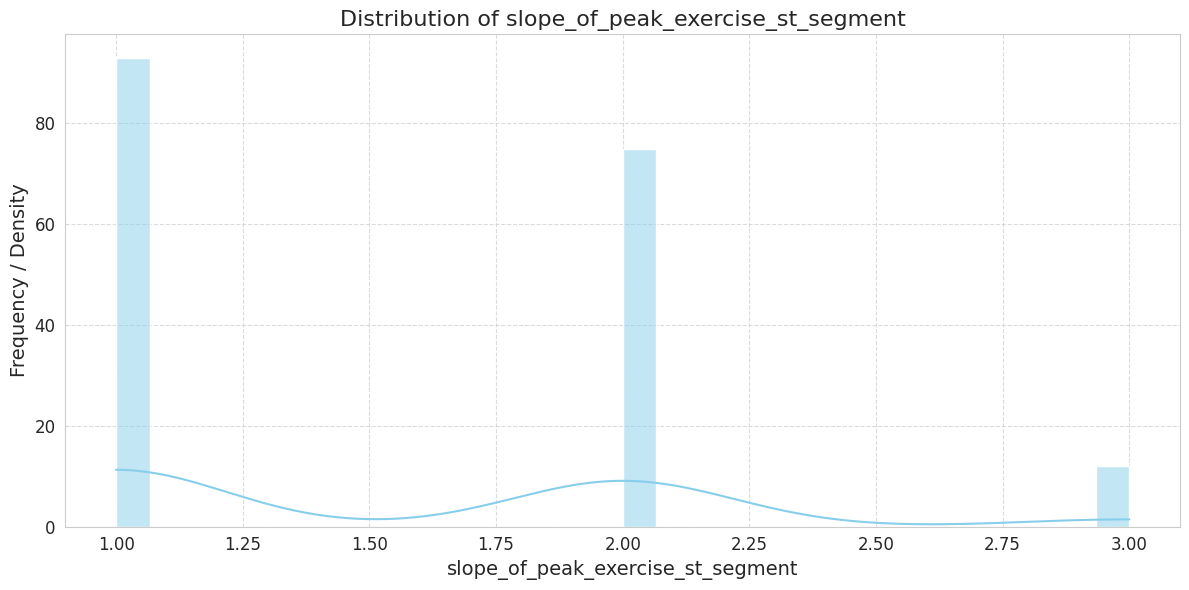

Observation for slope_of_peak_exercise_st_segment:
  - Skewness: 0.67
  - Kurtosis: -0.51
  - Distribution appears positively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



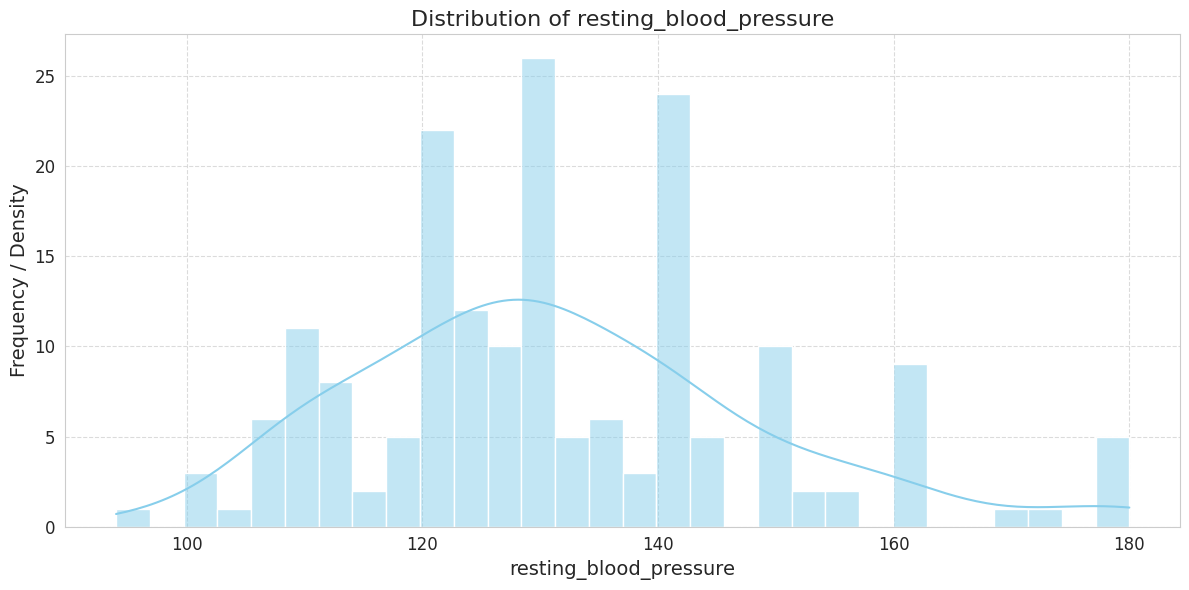

Observation for resting_blood_pressure:
  - Skewness: 0.66
  - Kurtosis: 0.47
  - Distribution appears positively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



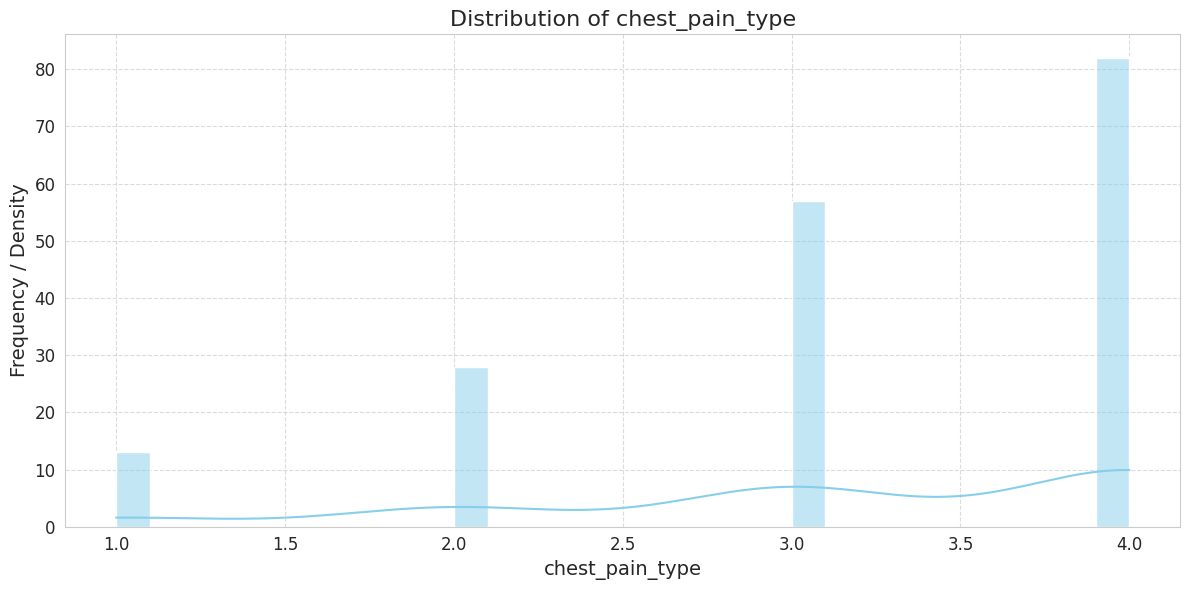

Observation for chest_pain_type:
  - Skewness: -0.85
  - Kurtosis: -0.28
  - Distribution appears negatively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



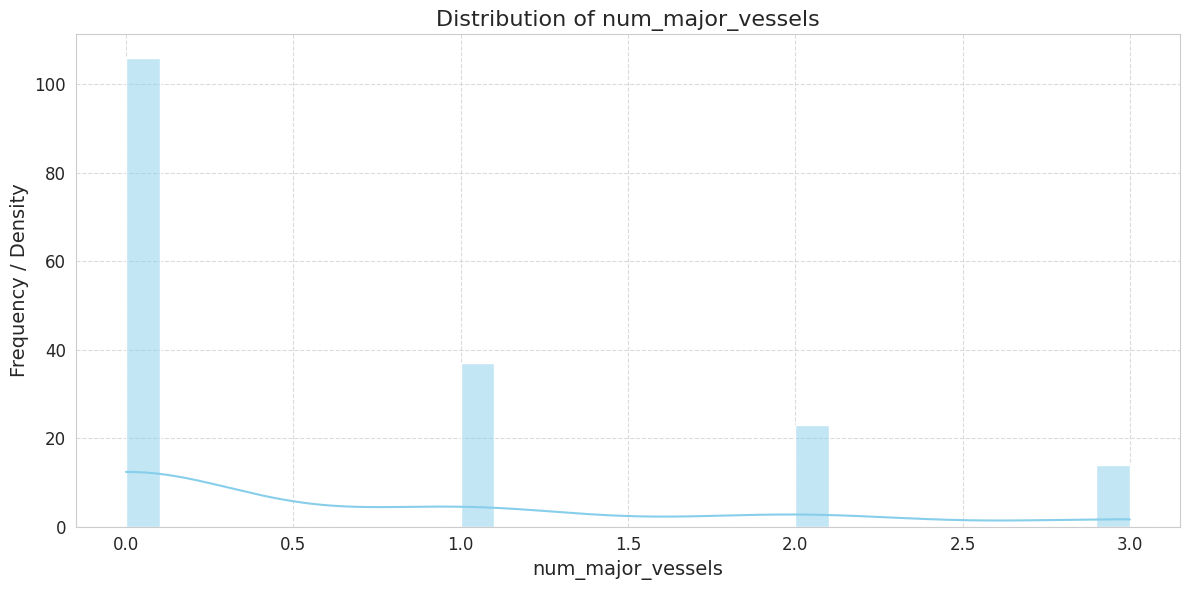

Observation for num_major_vessels:
  - Skewness: 1.17
  - Kurtosis: 0.14
  - Distribution appears positively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



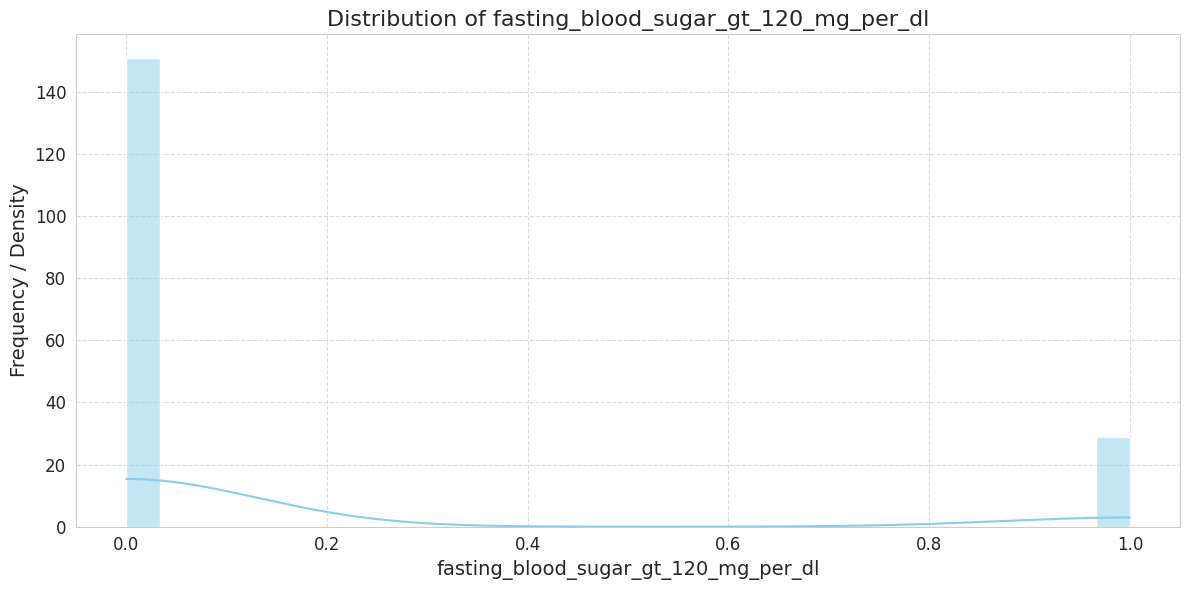

Observation for fasting_blood_sugar_gt_120_mg_per_dl:
  - Skewness: 1.86
  - Kurtosis: 1.47
  - Distribution appears positively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



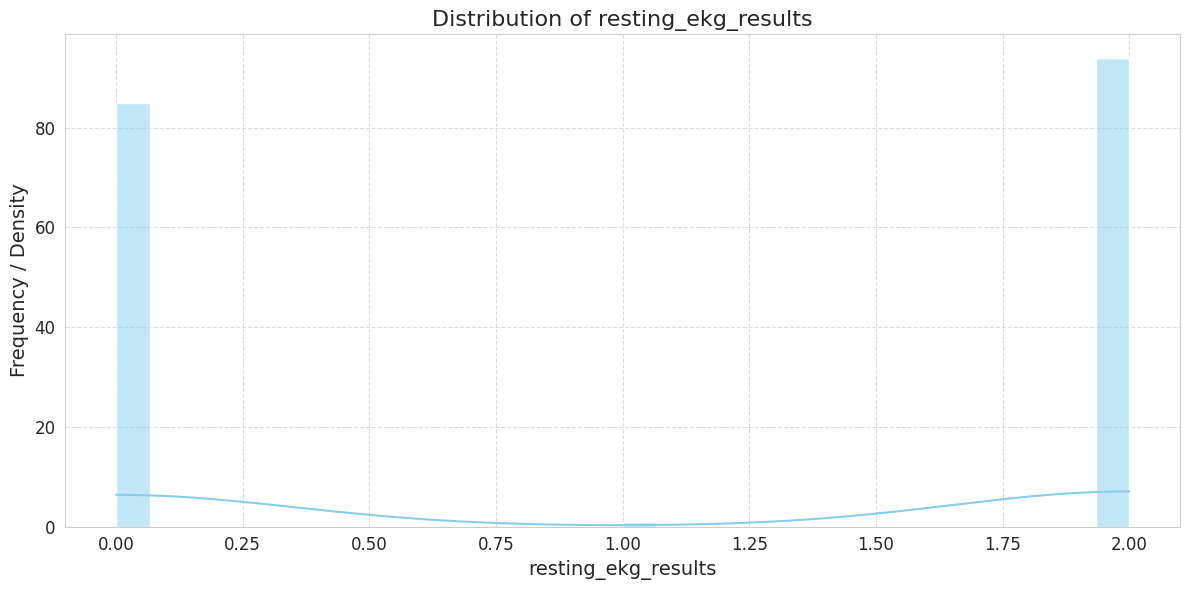

Observation for resting_ekg_results:
  - Skewness: -0.10
  - Kurtosis: -2.01
  - Distribution appears relatively symmetric.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



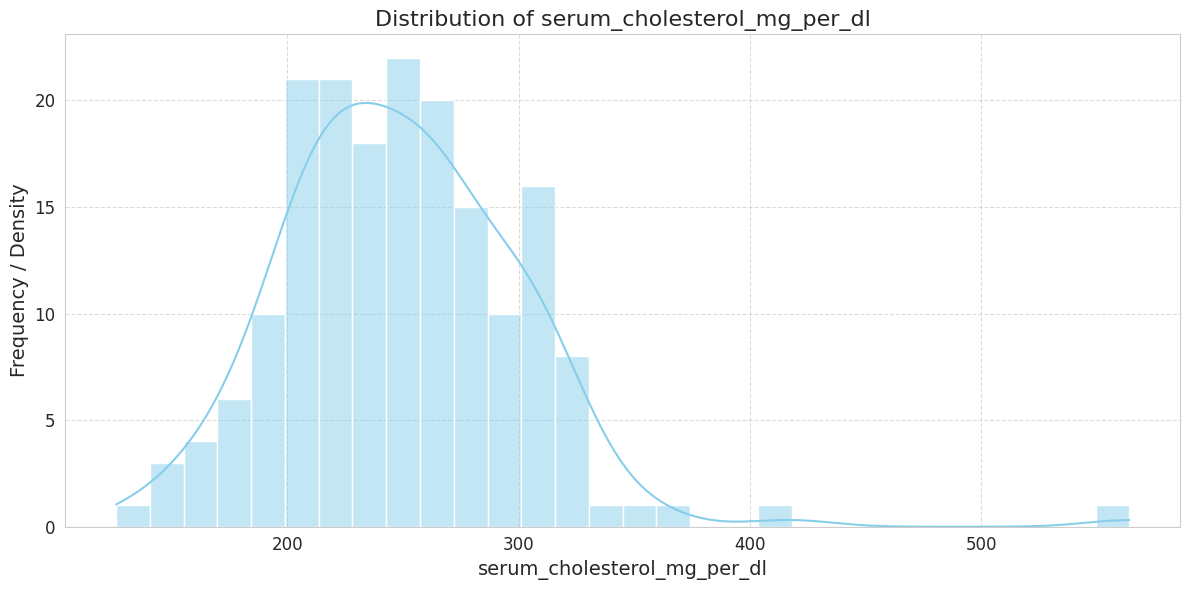

Observation for serum_cholesterol_mg_per_dl:
  - Skewness: 1.27
  - Kurtosis: 6.36
  - Distribution appears positively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



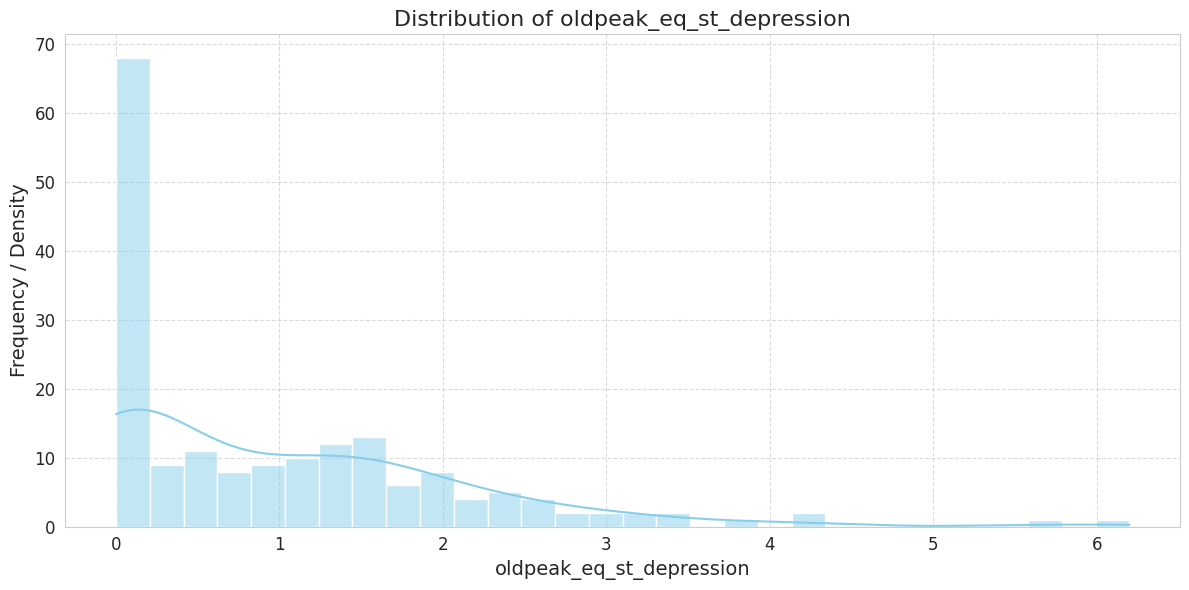

Observation for oldpeak_eq_st_depression:
  - Skewness: 1.51
  - Kurtosis: 3.24
  - Distribution appears positively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



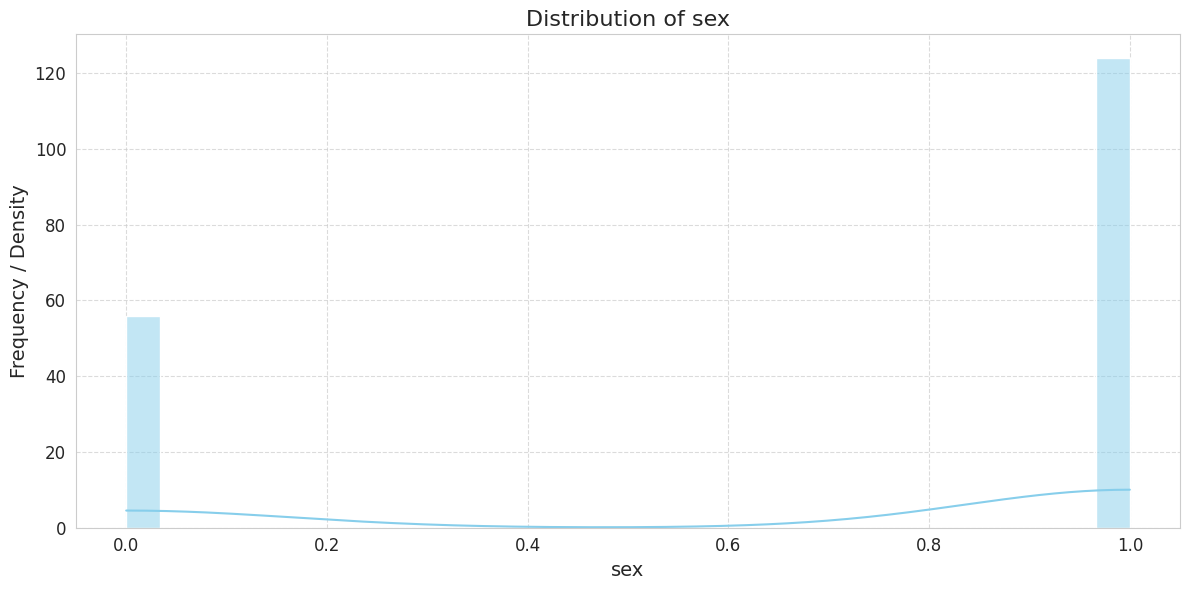

Observation for sex:
  - Skewness: -0.82
  - Kurtosis: -1.34
  - Distribution appears negatively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



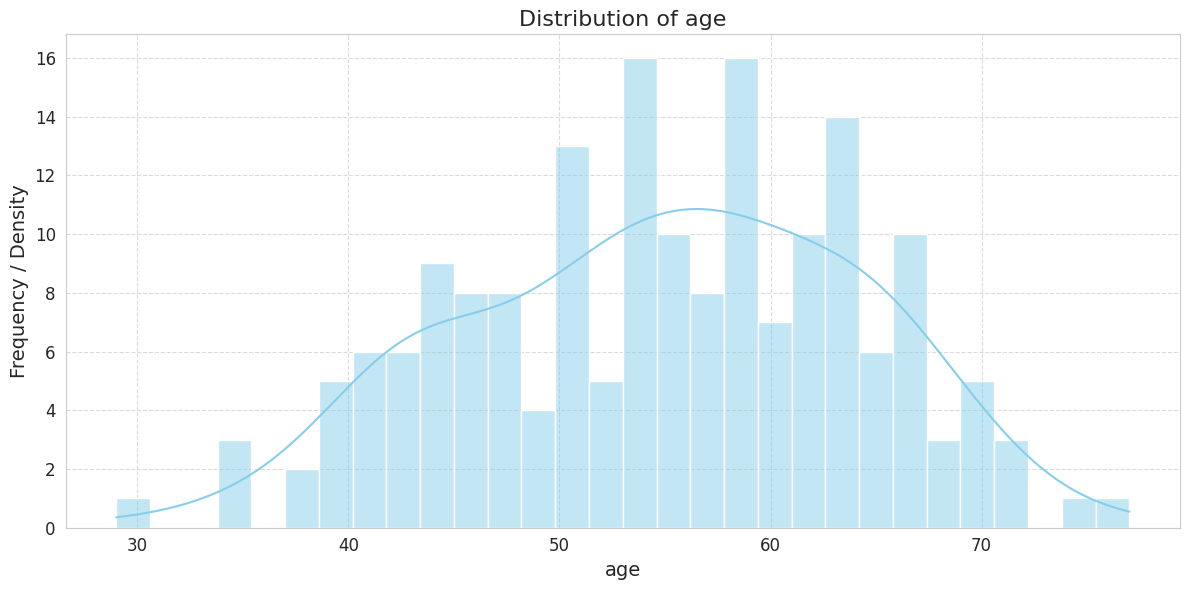

Observation for age:
  - Skewness: -0.20
  - Kurtosis: -0.57
  - Distribution appears relatively symmetric.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



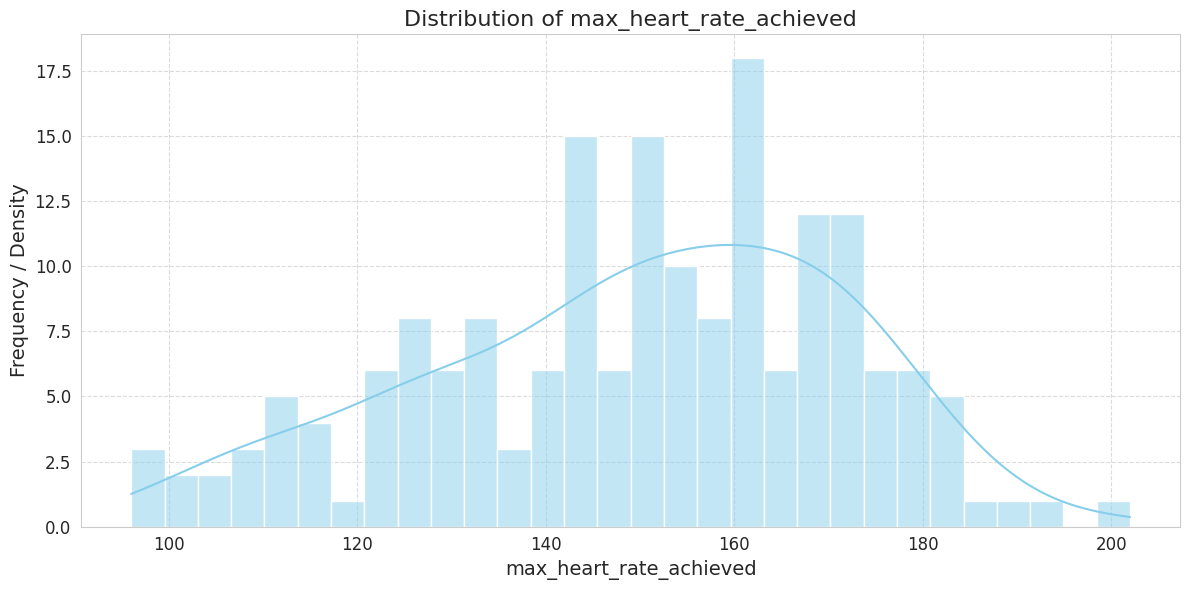

Observation for max_heart_rate_achieved:
  - Skewness: -0.39
  - Kurtosis: -0.48
  - Distribution appears relatively symmetric.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------



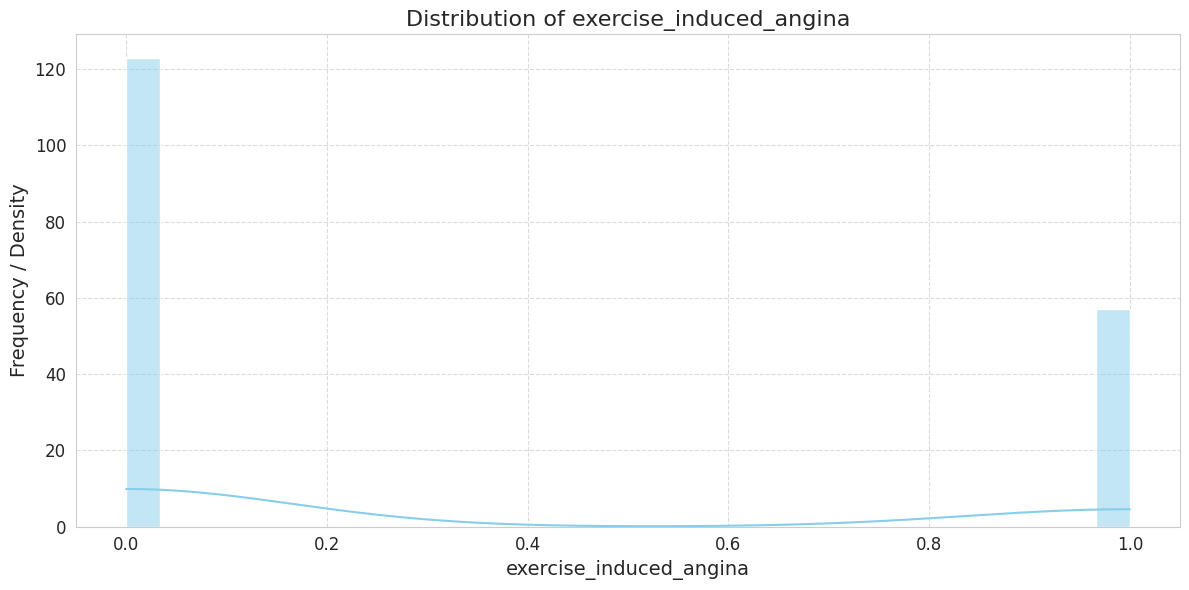

Observation for exercise_induced_angina:
  - Skewness: 0.79
  - Kurtosis: -1.38
  - Distribution appears positively skewed.
  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.
---------------------------------------------------


--- 5.2: Count Plots for Categorical Features ---


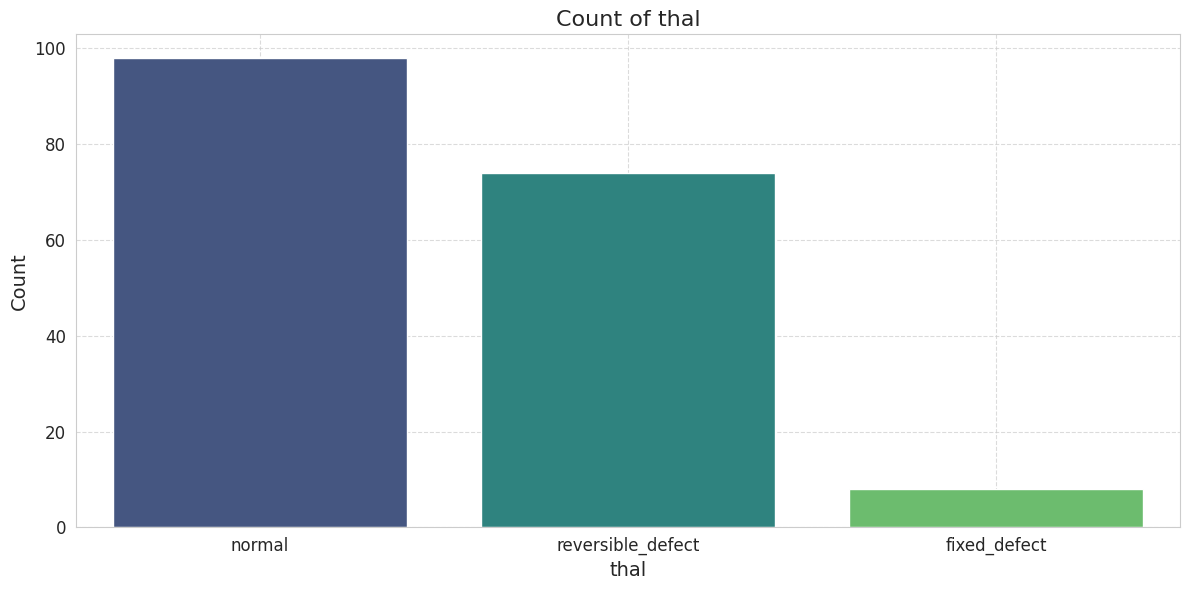

Observation for thal:
  - Value Counts:
thal
normal               98
reversible_defect    74
fixed_defect          8
  - Visually represents the distribution of categories. Imbalance might require special handling (e.g., oversampling/undersampling).
---------------------------------------------------


--- 5.3: Pie Charts for Binary/Low Cardinality Categorical Features ---


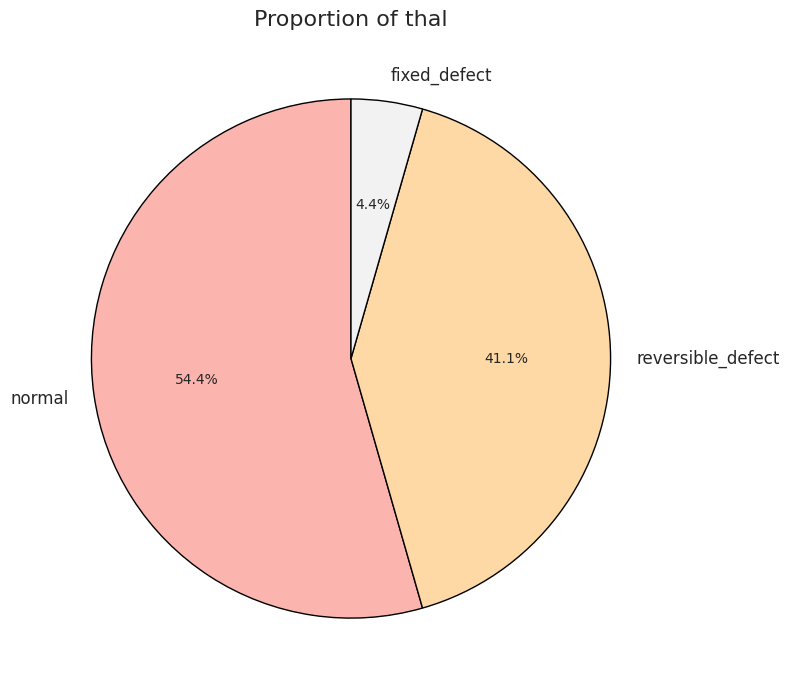

Observation for thal:
  - Proportion of each category: {'normal': 0.5444444444444444, 'reversible_defect': 0.4111111111111111, 'fixed_defect': 0.044444444444444446}
  - Clearly shows the percentage contribution of each category.
---------------------------------------------------


--- 5.4: Box Plots for Numerical Features (Outlier Detection Overview) ---


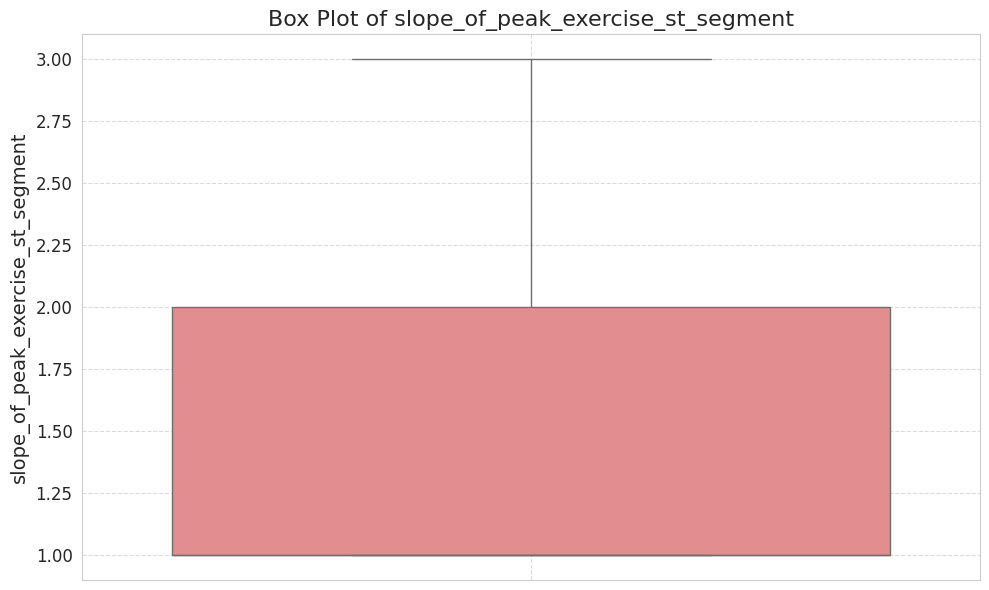

Observation for slope_of_peak_exercise_st_segment:
  - No significant outliers detected based on IQR method.
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



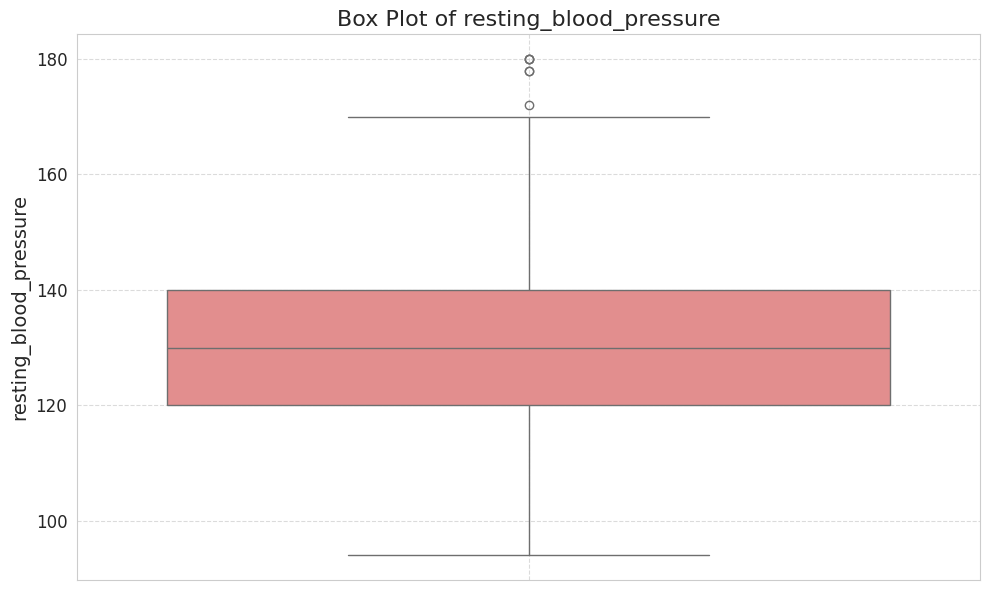

Observation for resting_blood_pressure:
  - Potential outliers detected (values outside 1.5*IQR from quartiles). Count: 6.
  - Outlier values (sample): [178, 180, 172, 178, 180]...
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



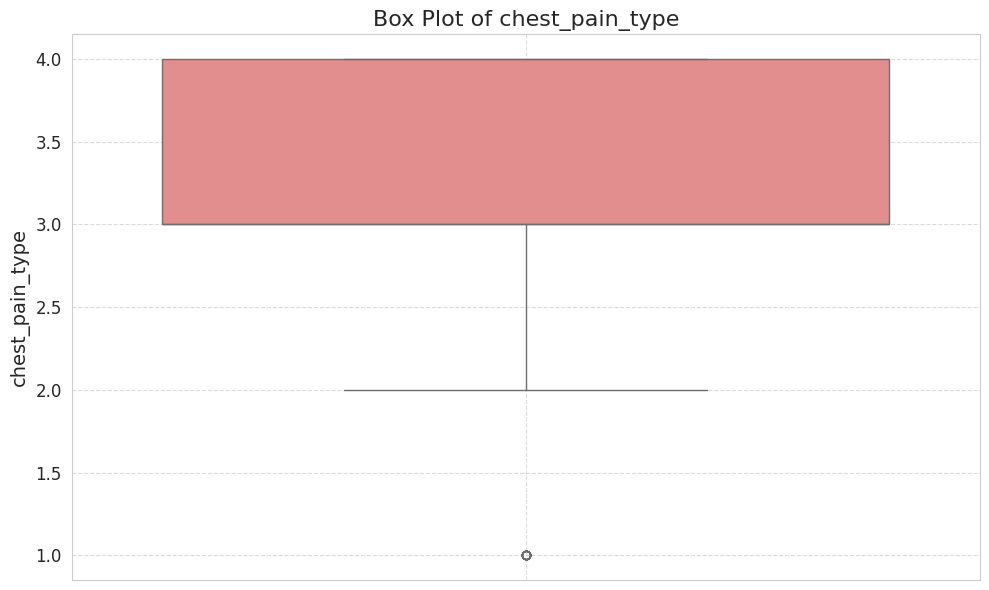

Observation for chest_pain_type:
  - Potential outliers detected (values outside 1.5*IQR from quartiles). Count: 13.
  - Outlier values (sample): [1, 1, 1, 1, 1]...
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



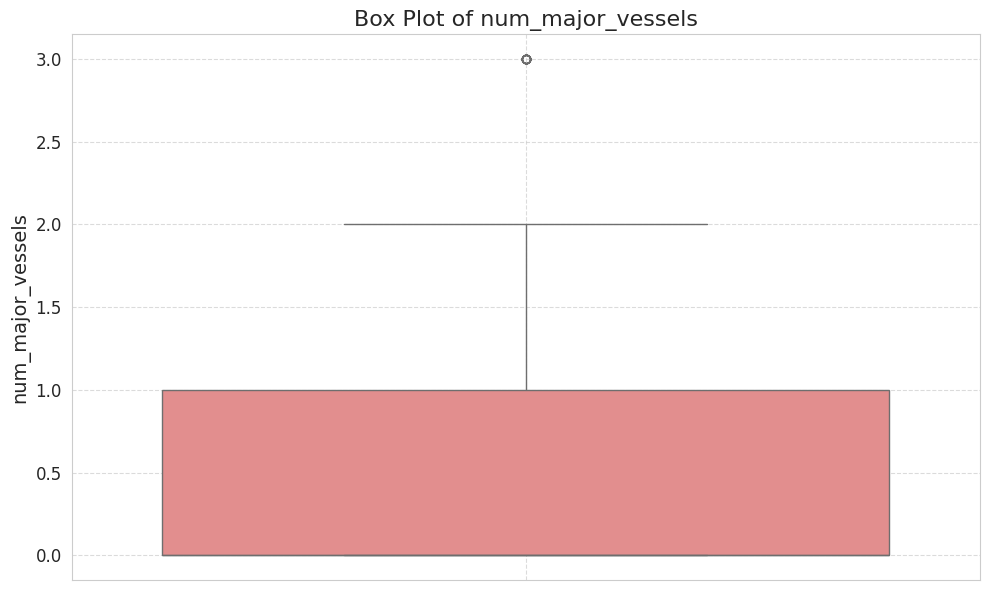

Observation for num_major_vessels:
  - Potential outliers detected (values outside 1.5*IQR from quartiles). Count: 14.
  - Outlier values (sample): [3, 3, 3, 3, 3]...
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



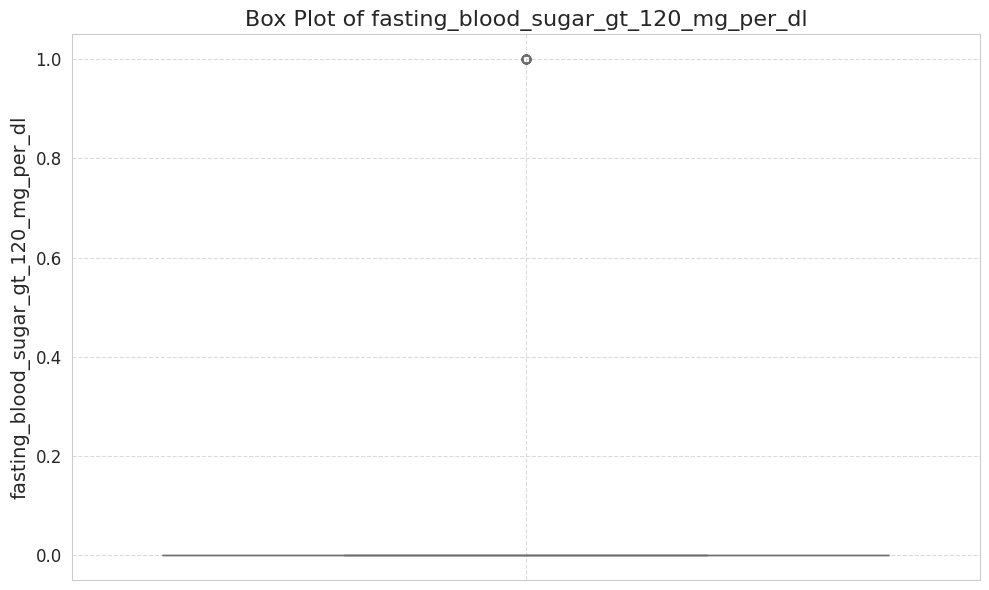

Observation for fasting_blood_sugar_gt_120_mg_per_dl:
  - Potential outliers detected (values outside 1.5*IQR from quartiles). Count: 29.
  - Outlier values (sample): [1, 1, 1, 1, 1]...
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



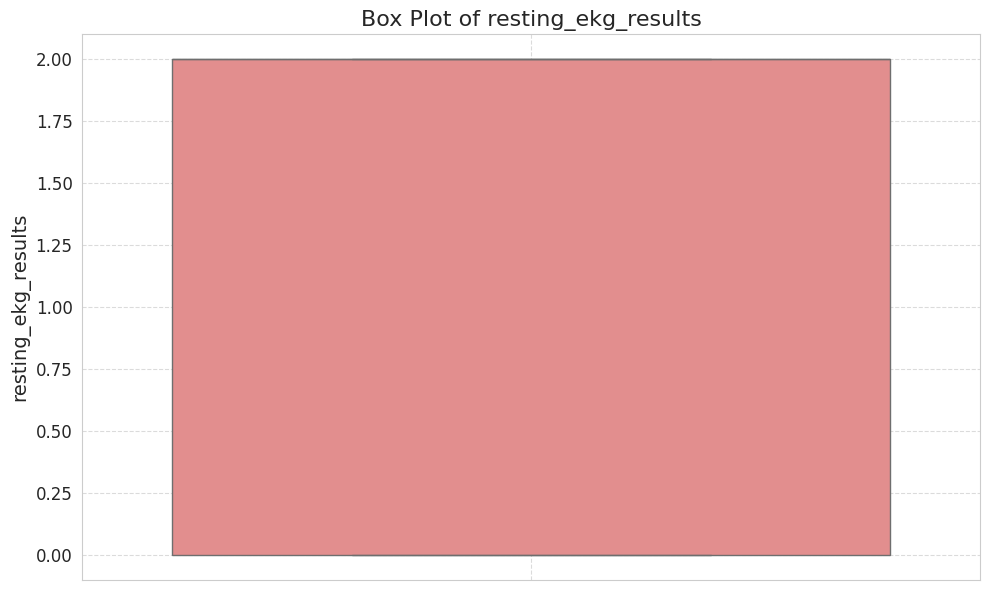

Observation for resting_ekg_results:
  - No significant outliers detected based on IQR method.
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



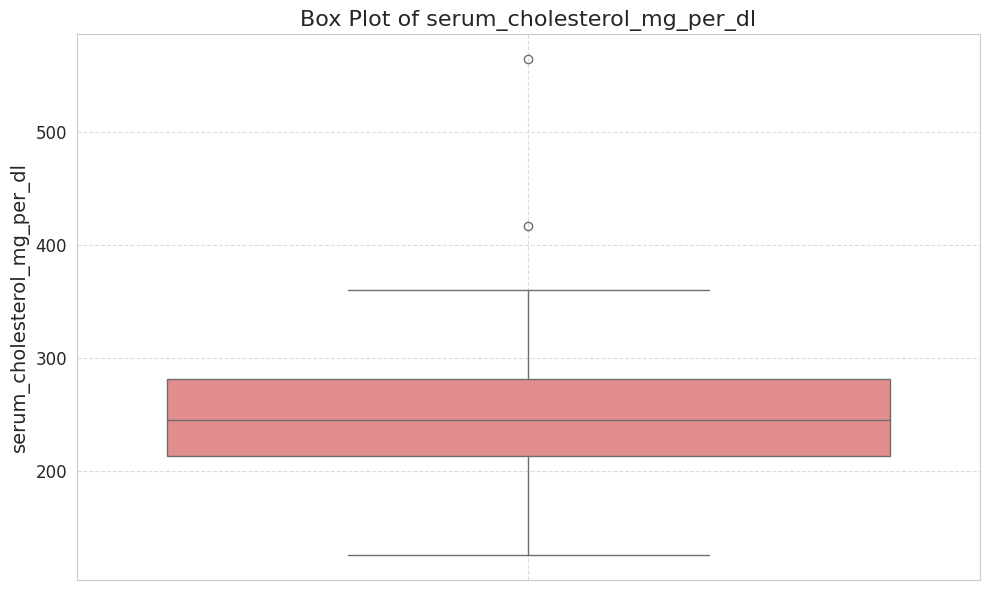

Observation for serum_cholesterol_mg_per_dl:
  - Potential outliers detected (values outside 1.5*IQR from quartiles). Count: 2.
  - Outlier values (sample): [417, 564]...
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



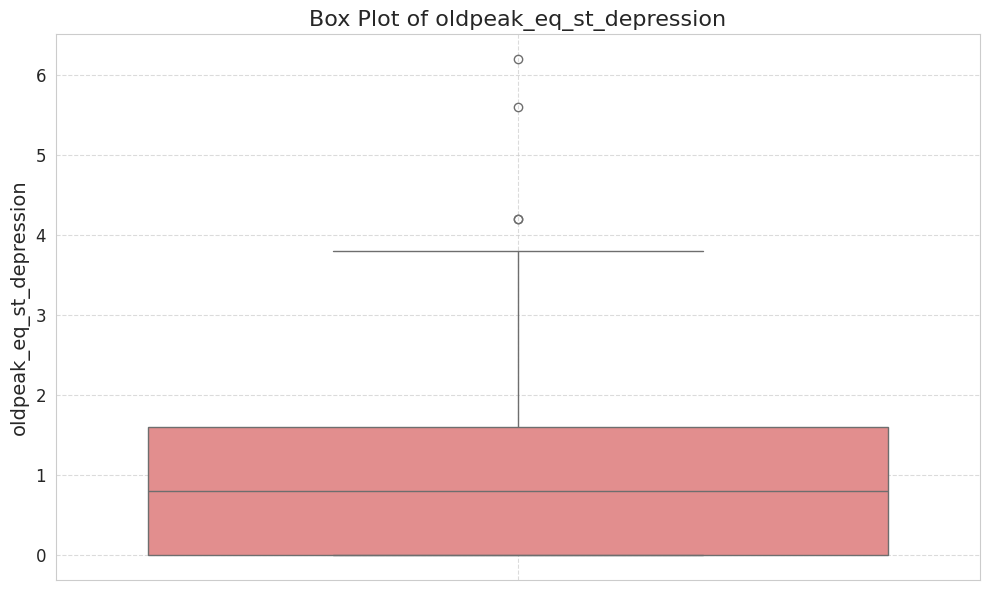

Observation for oldpeak_eq_st_depression:
  - Potential outliers detected (values outside 1.5*IQR from quartiles). Count: 4.
  - Outlier values (sample): [4.2, 4.2, 5.6, 6.2]...
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



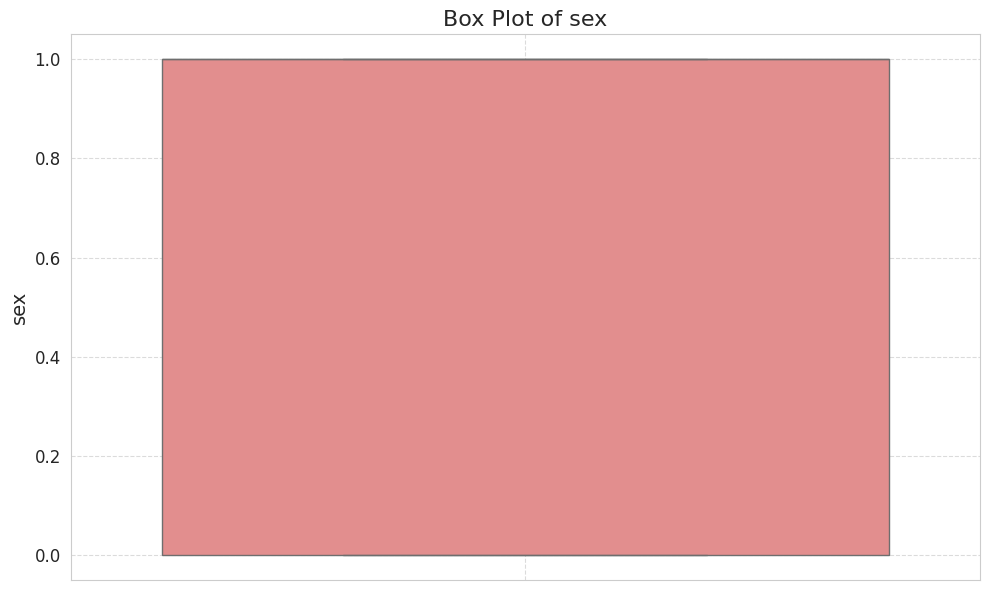

Observation for sex:
  - No significant outliers detected based on IQR method.
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



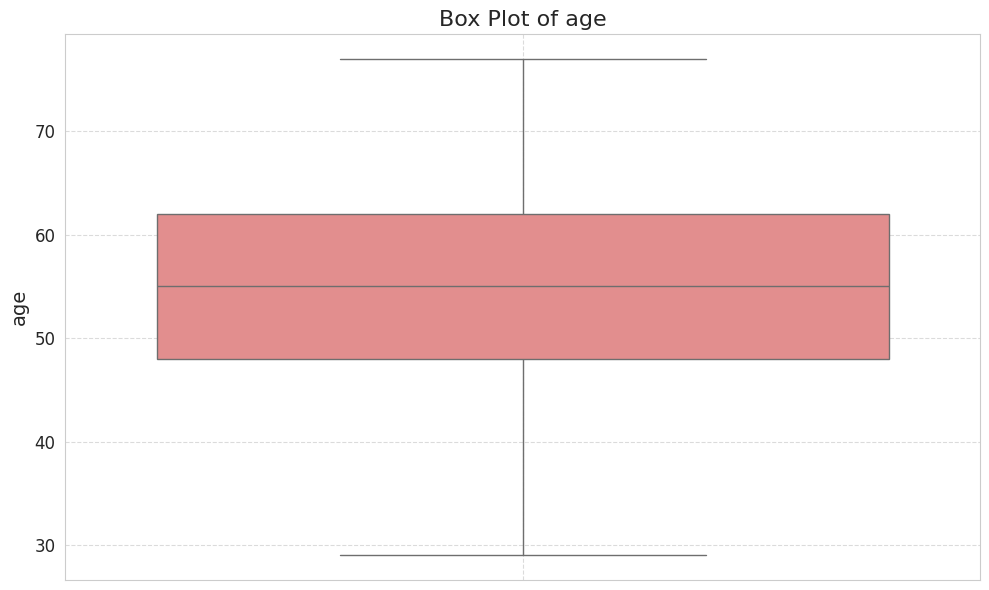

Observation for age:
  - No significant outliers detected based on IQR method.
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



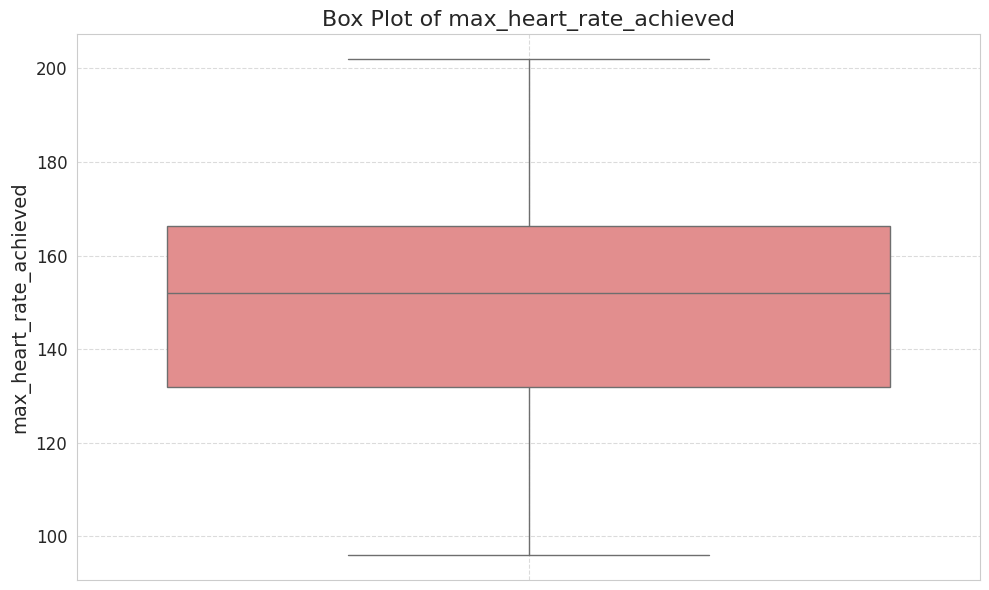

Observation for max_heart_rate_achieved:
  - No significant outliers detected based on IQR method.
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------



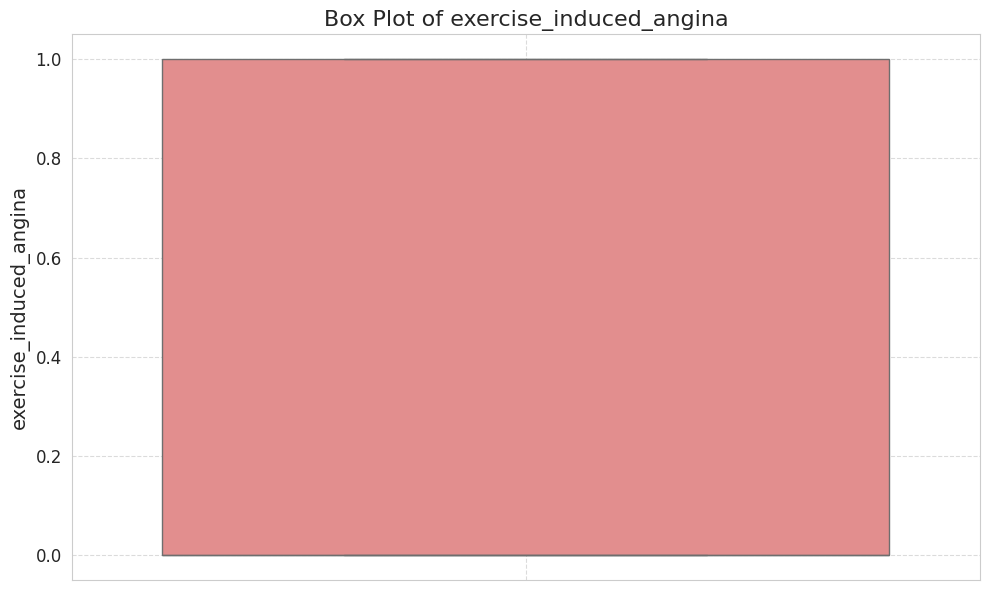

Observation for exercise_induced_angina:
  - No significant outliers detected based on IQR method.
  - Provides a visual summary of data distribution and highlights potential extreme values.
---------------------------------------------------


--- 5.5: Relationship between Features and Target Variable ---

5.5.1: Numerical Features vs. Target Variable (Box Plots) 


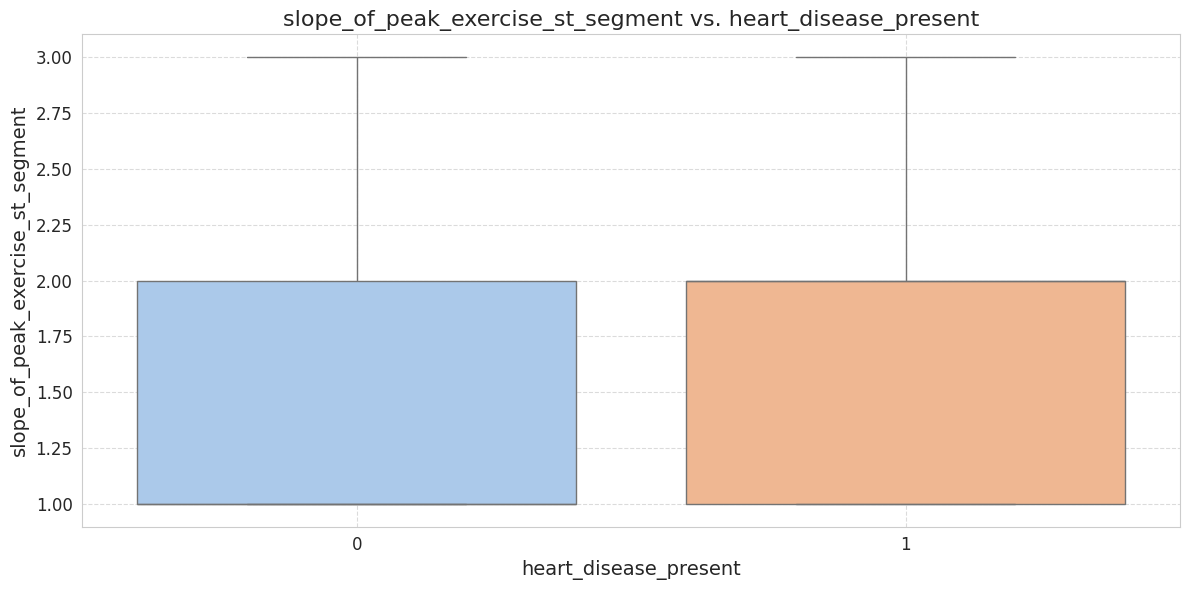

Observation for slope_of_peak_exercise_st_segment vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



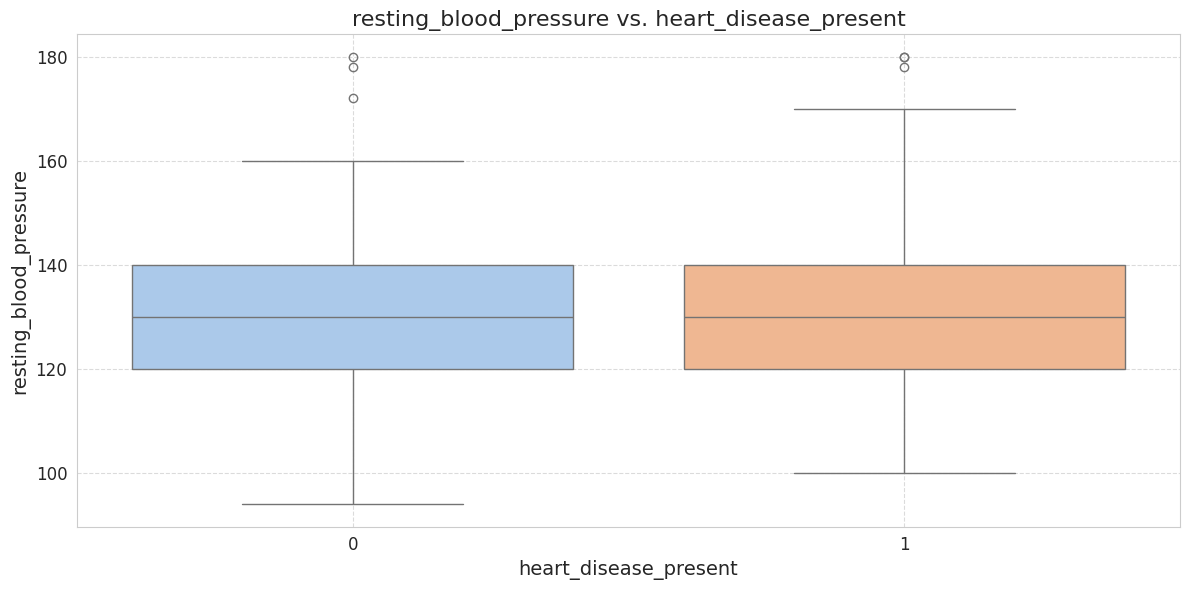

Observation for resting_blood_pressure vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



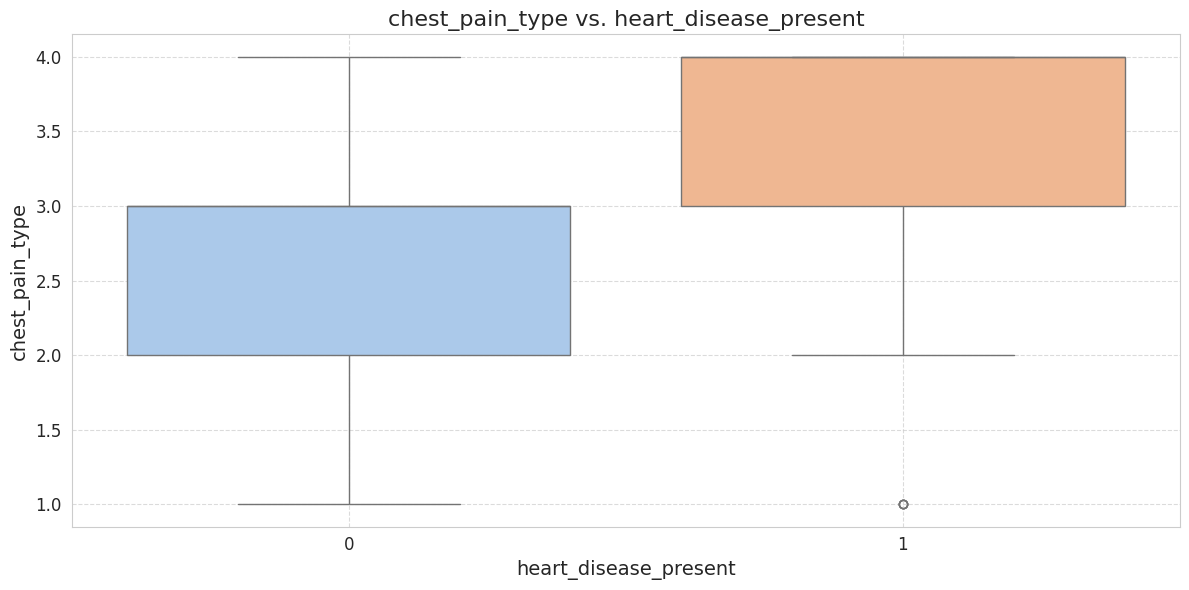

Observation for chest_pain_type vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



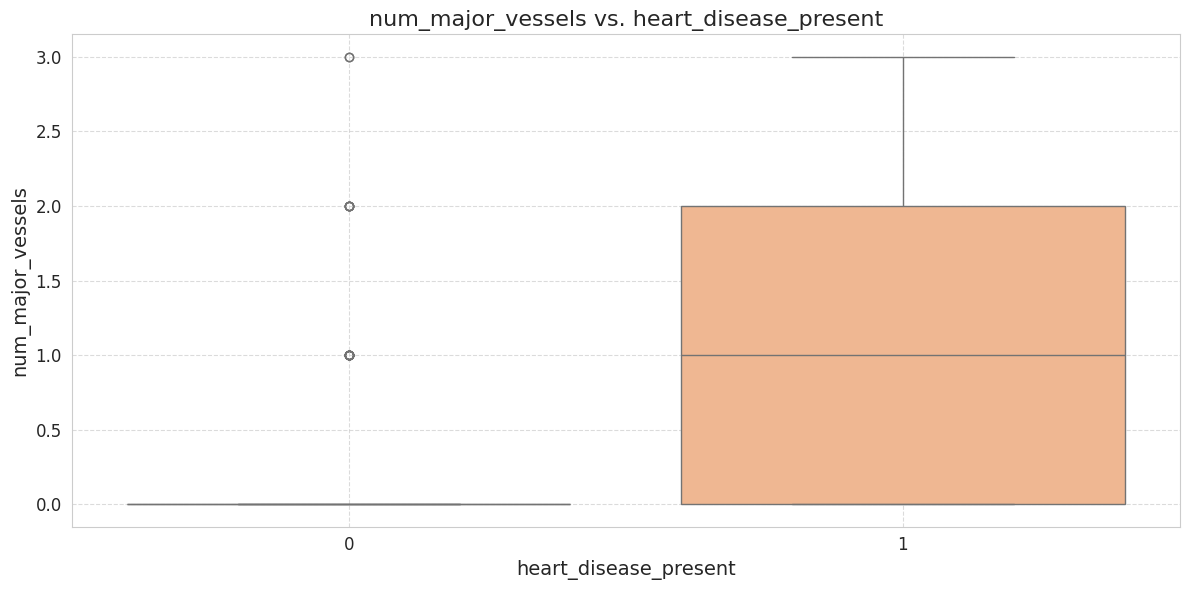

Observation for num_major_vessels vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



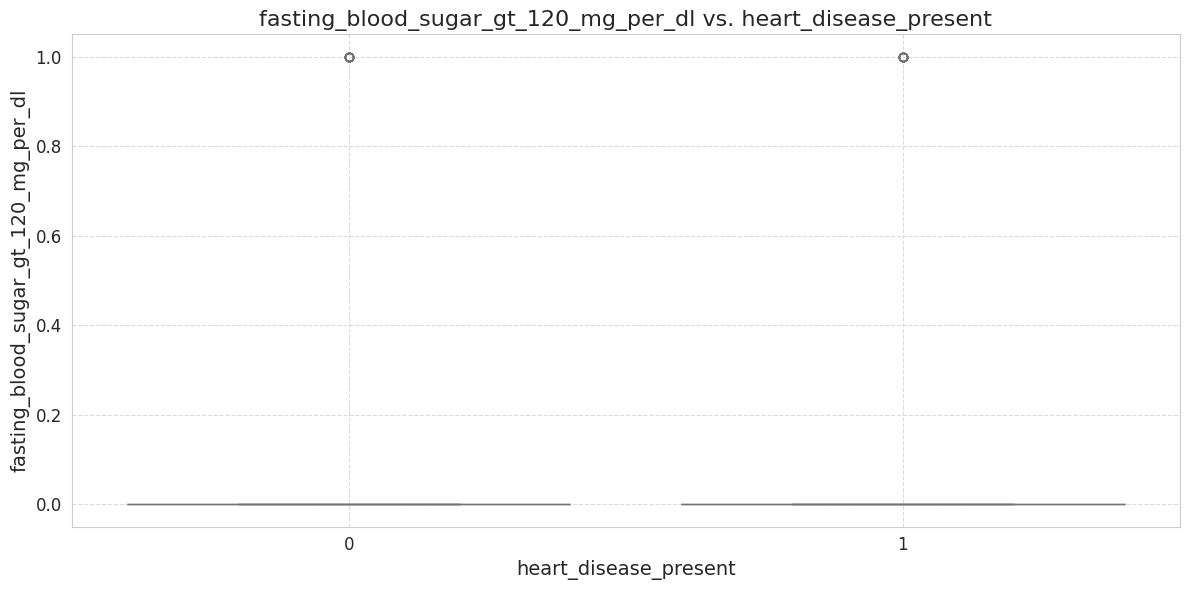

Observation for fasting_blood_sugar_gt_120_mg_per_dl vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



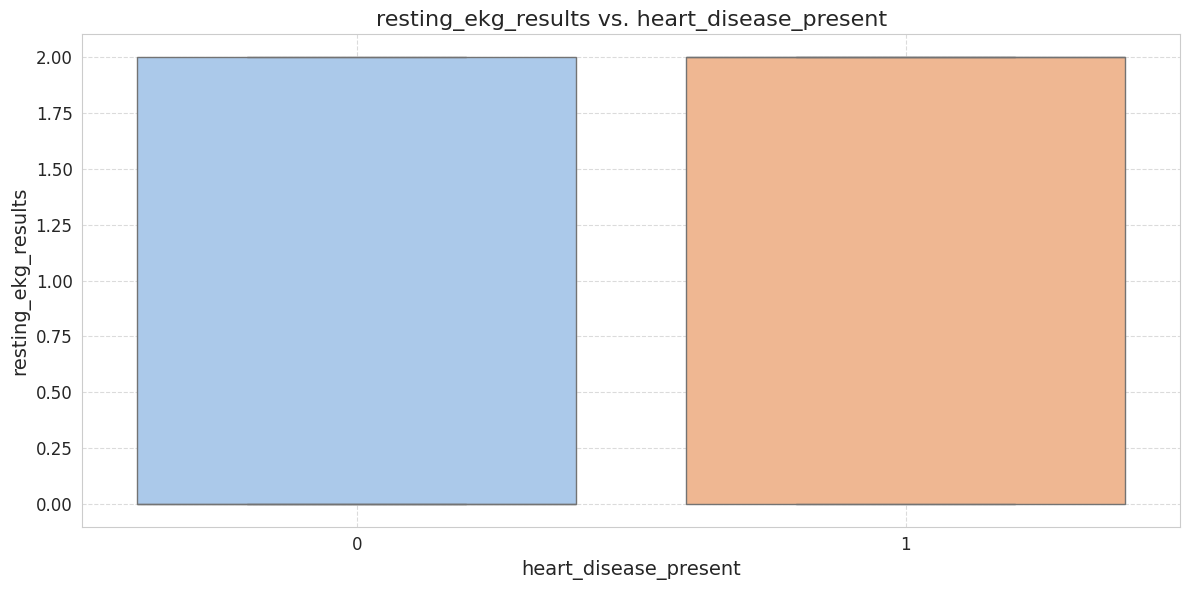

Observation for resting_ekg_results vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



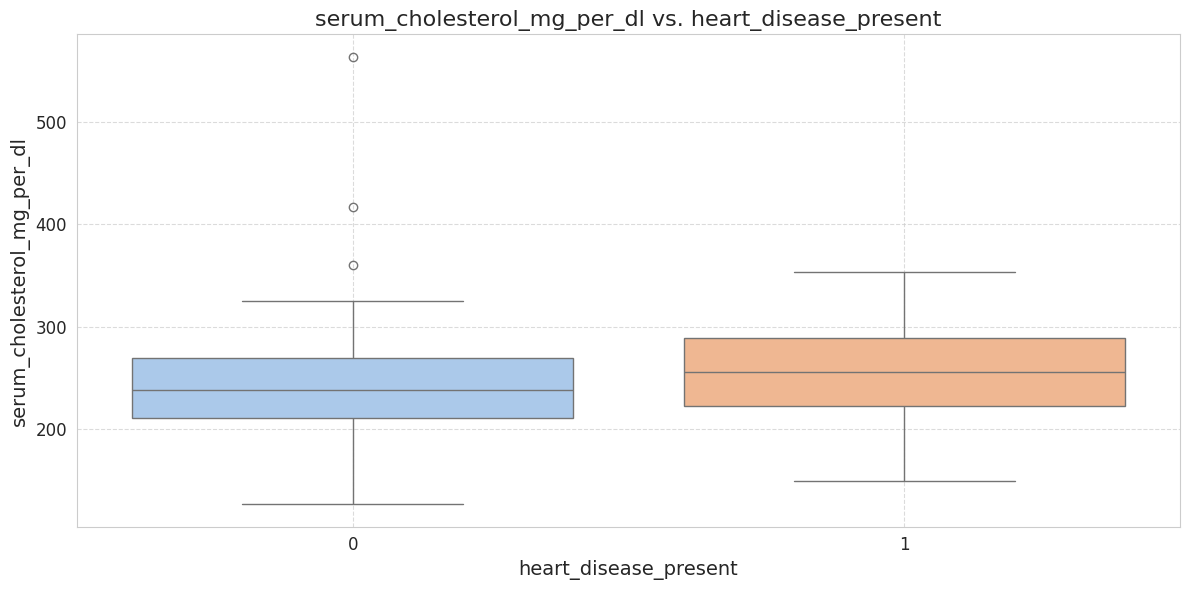

Observation for serum_cholesterol_mg_per_dl vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



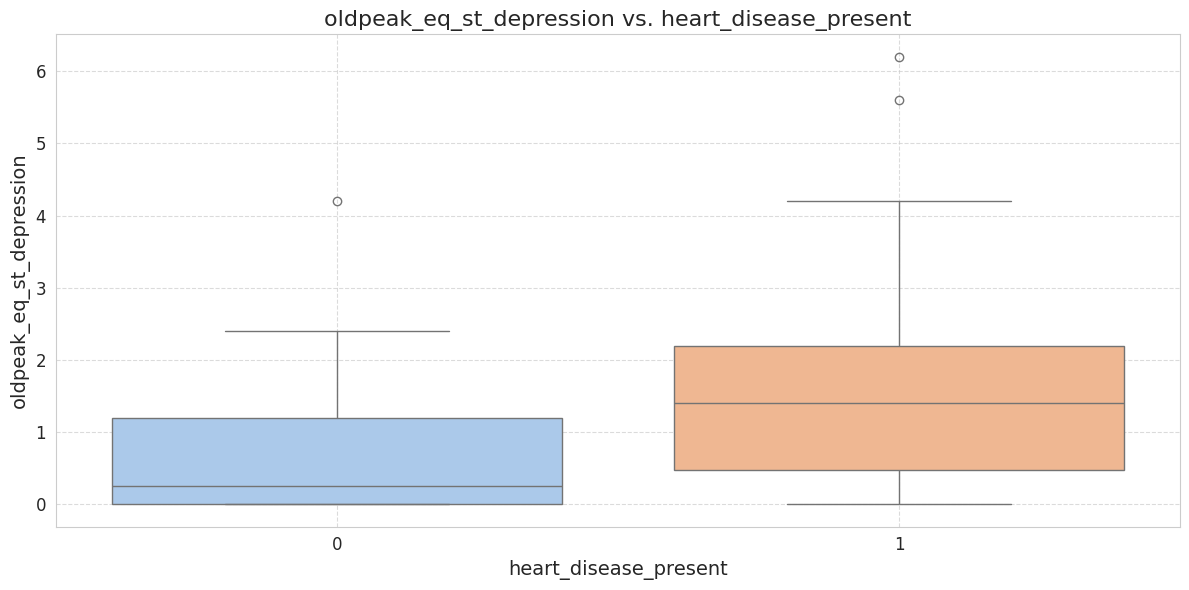

Observation for oldpeak_eq_st_depression vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



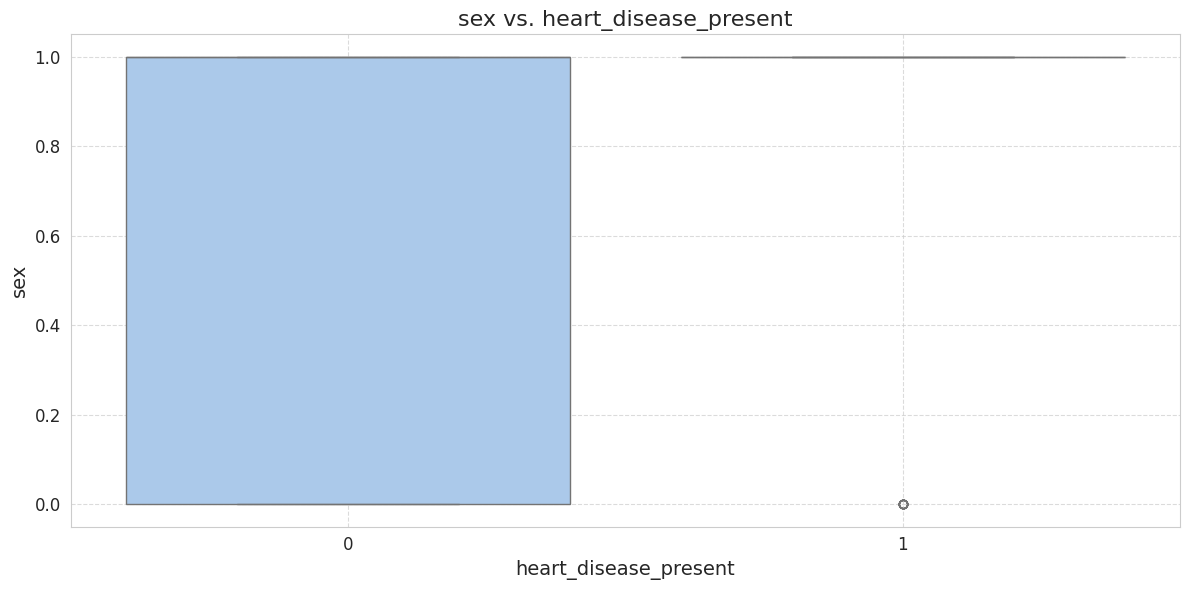

Observation for sex vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



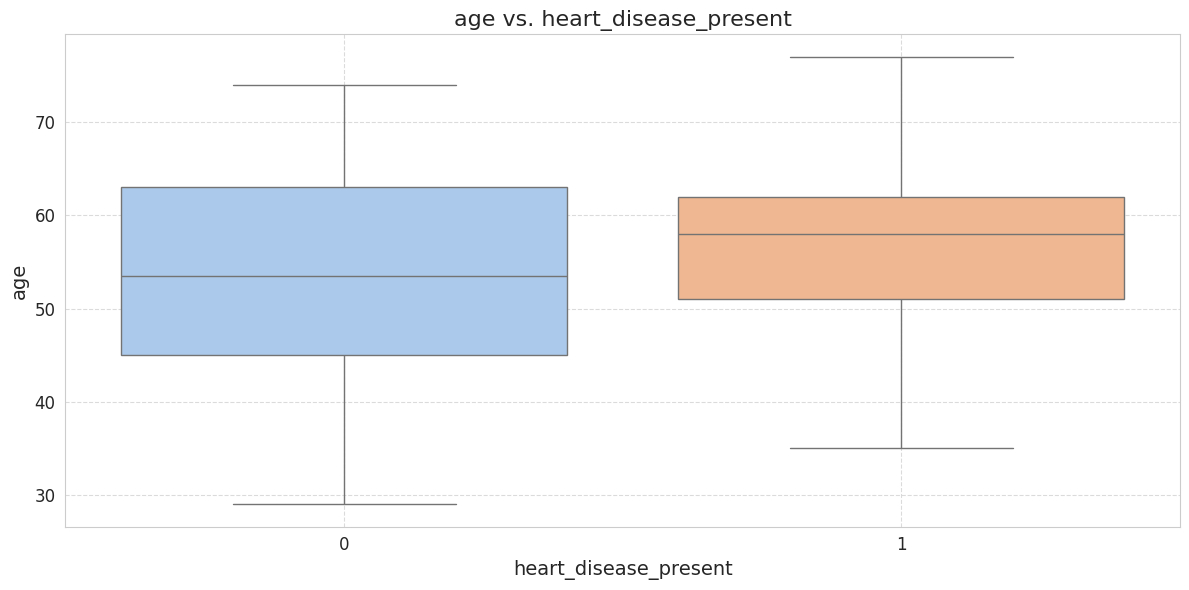

Observation for age vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



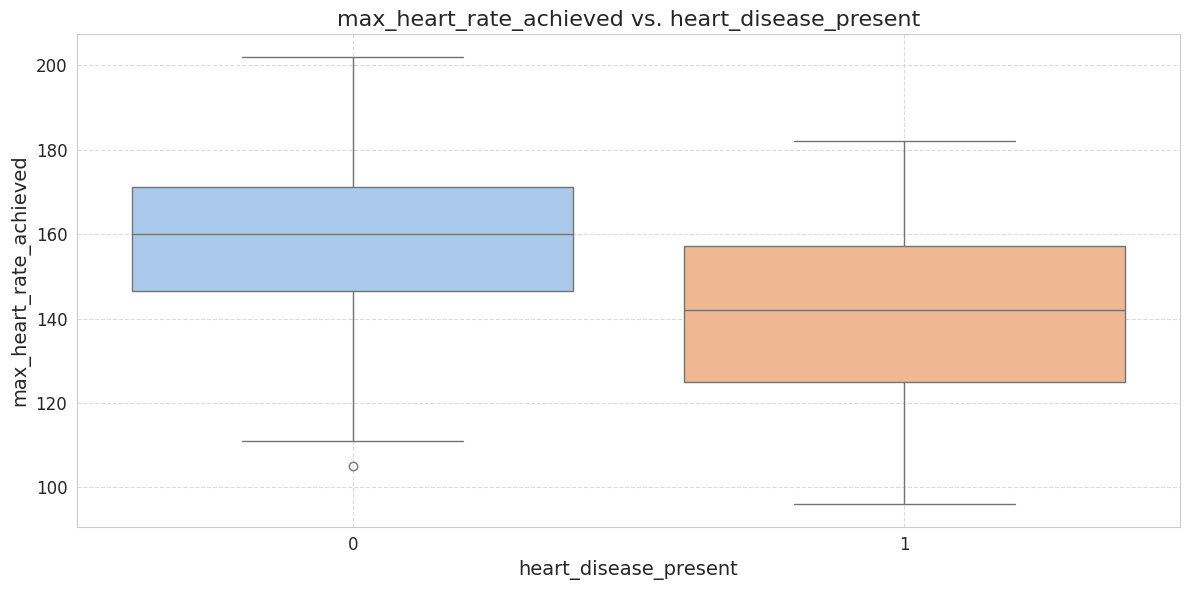

Observation for max_heart_rate_achieved vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------



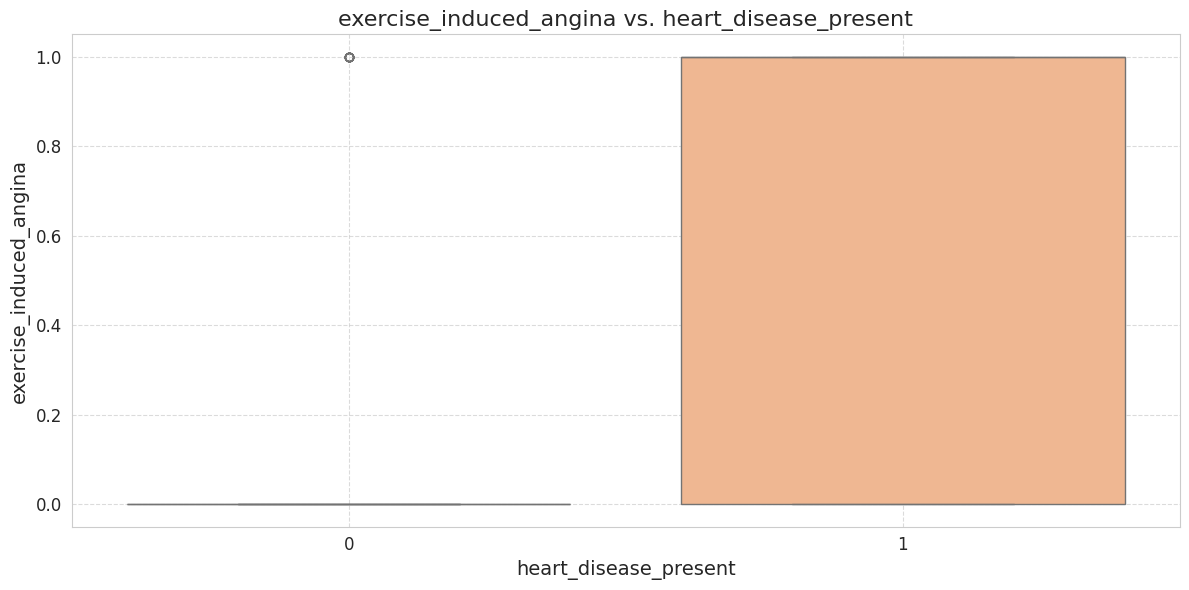

Observation for exercise_induced_angina vs. heart_disease_present:
  - Compares the distribution of the numerical feature across target classes.
  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.
---------------------------------------------------


5.5.2: Categorical Features vs. Target Variable (Count Plots / Stacked Bar Charts) 


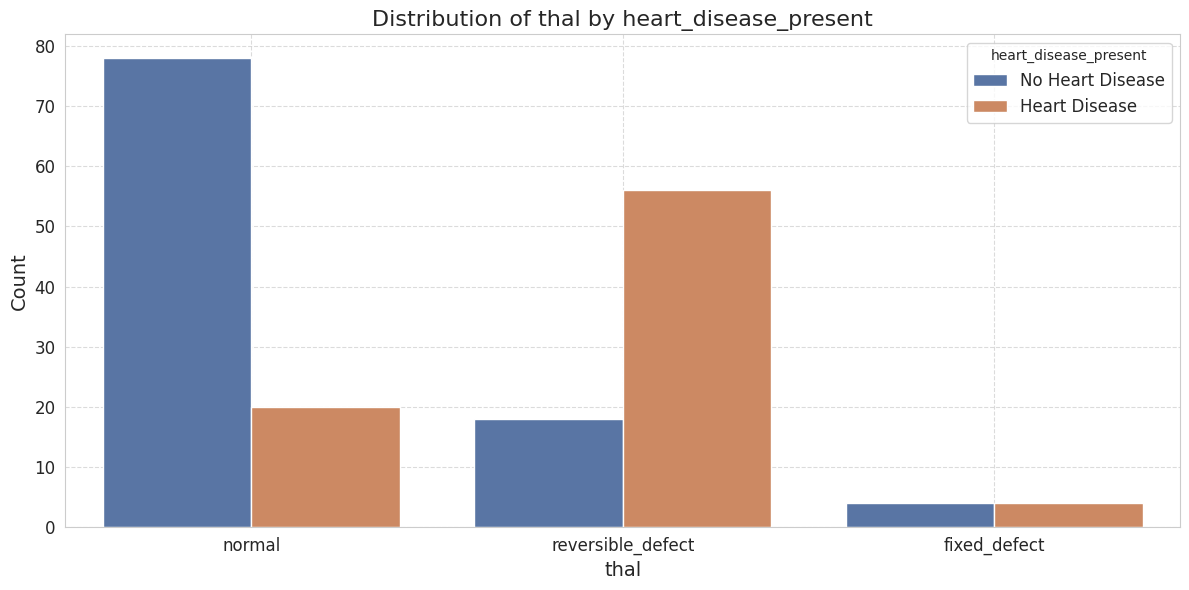

Observation for thal vs. heart_disease_present:
  - Proportional distribution of thal categories across heart_disease_present classes:
heart_disease_present      0      1
thal                               
fixed_defect           50.00  50.00
normal                 79.59  20.41
reversible_defect      24.32  75.68
  - Uneven distributions or significant differences in proportions indicate a relationship between the categorical feature and heart disease presence.
---------------------------------------------------


--- 5.6: Correlation Matrix (Heatmap) ---


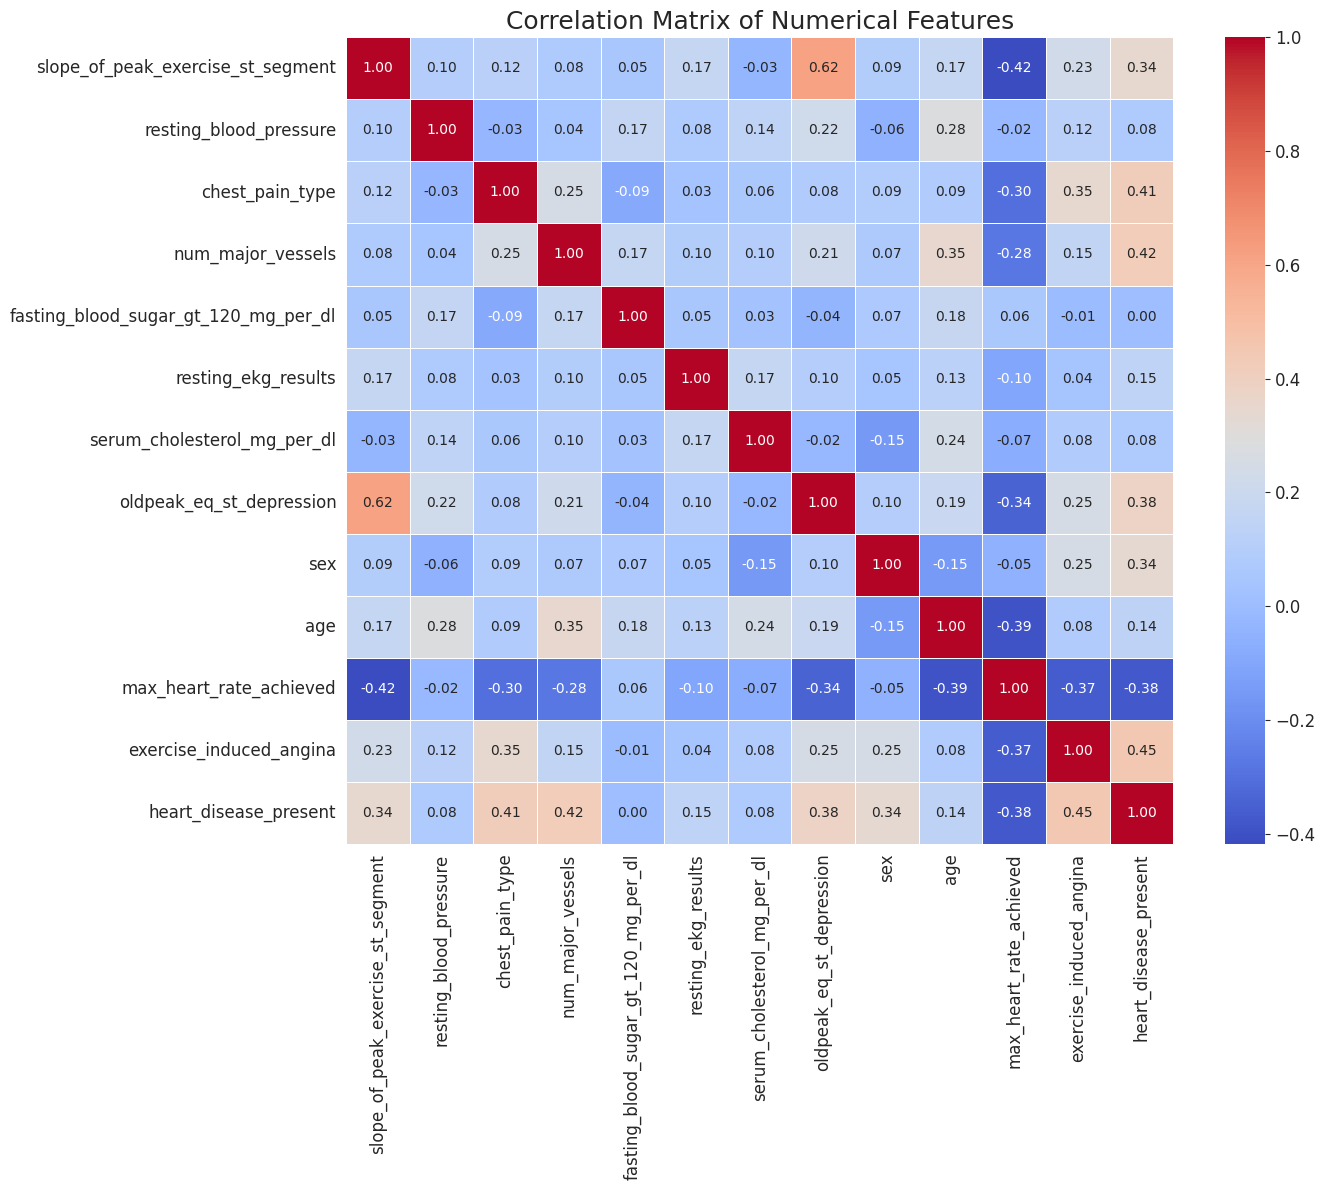

Observation for Correlation Matrix:
  - Values close to 1 or -1 indicate strong positive or negative linear correlation, respectively.
  - Values close to 0 suggest weak or no linear correlation.
  - High correlation between features (e.g., > 0.8) might suggest multicollinearity, requiring feature selection.
  - Features with higher absolute correlation with the target variable are potentially more predictive.
---------------------------------------------------


--- 5.7: Pairplot for key numerical features ---
Generating pairplot for selected columns: ['chest_pain_type', 'max_heart_rate_achieved', 'sex', 'exercise_induced_angina', 'oldpeak_eq_st_depression', 'age', 'num_major_vessels']


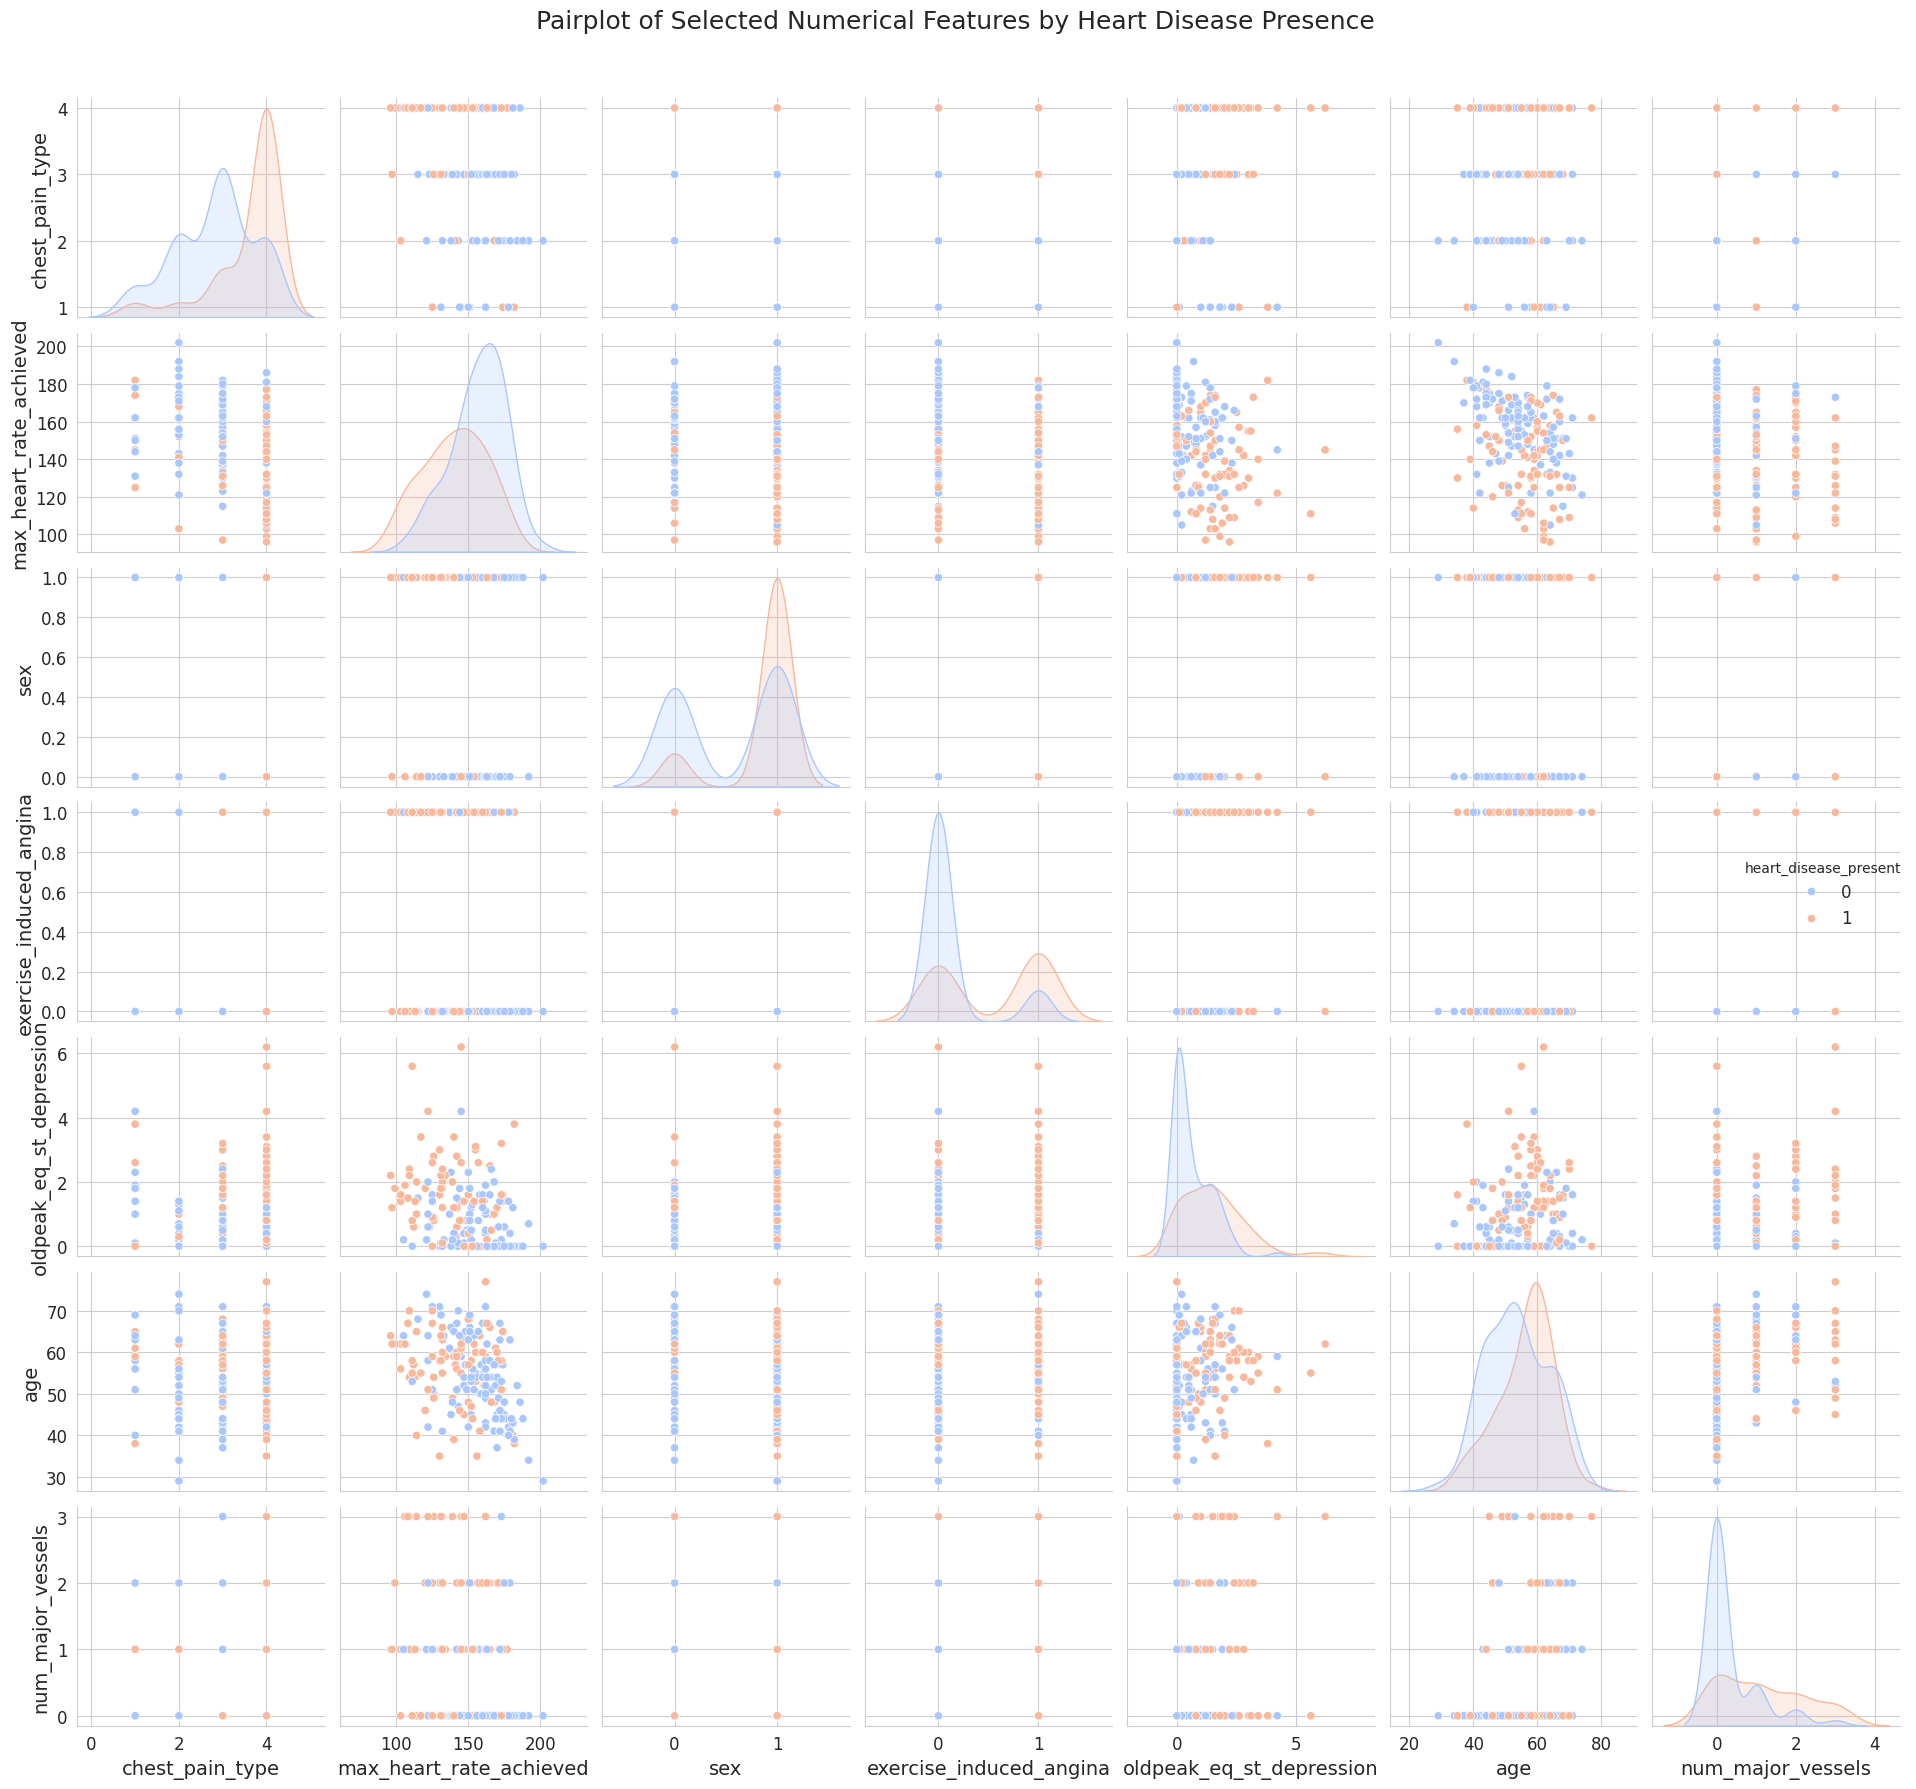

Observation for Pairplot:
  - Scatter plots show relationships between pairs of features. Different colored clusters might indicate separation based on heart disease.
  - Diagonal plots show the distribution of individual features. Differences in distributions between target classes are visible.
  - Helps to visually identify linear or non-linear relationships and potential feature interactions.
---------------------------------------------------


--- 5.8: Violin Plots for Numerical Features vs. Target ---


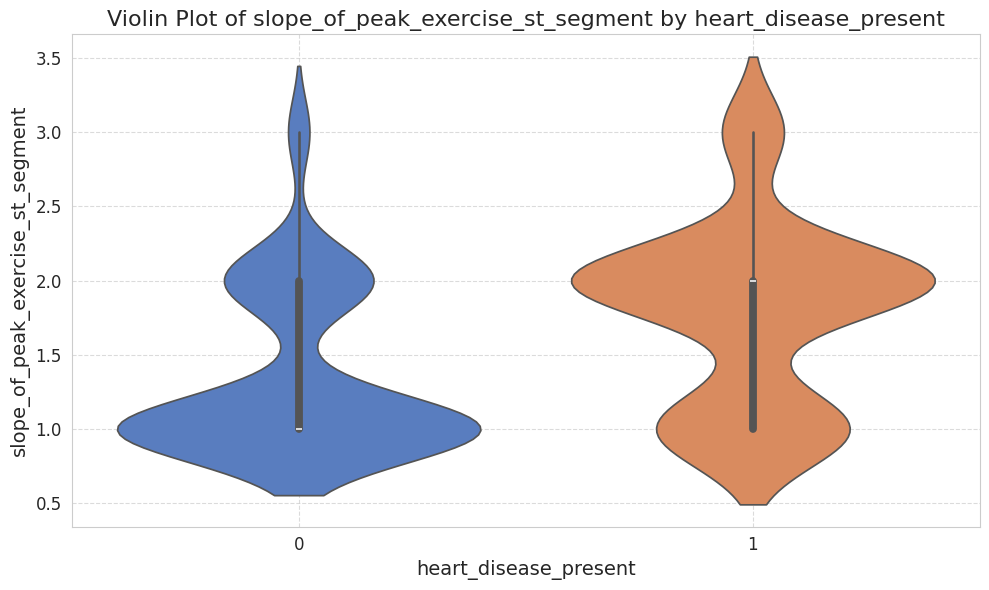

Observation for slope_of_peak_exercise_st_segment (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



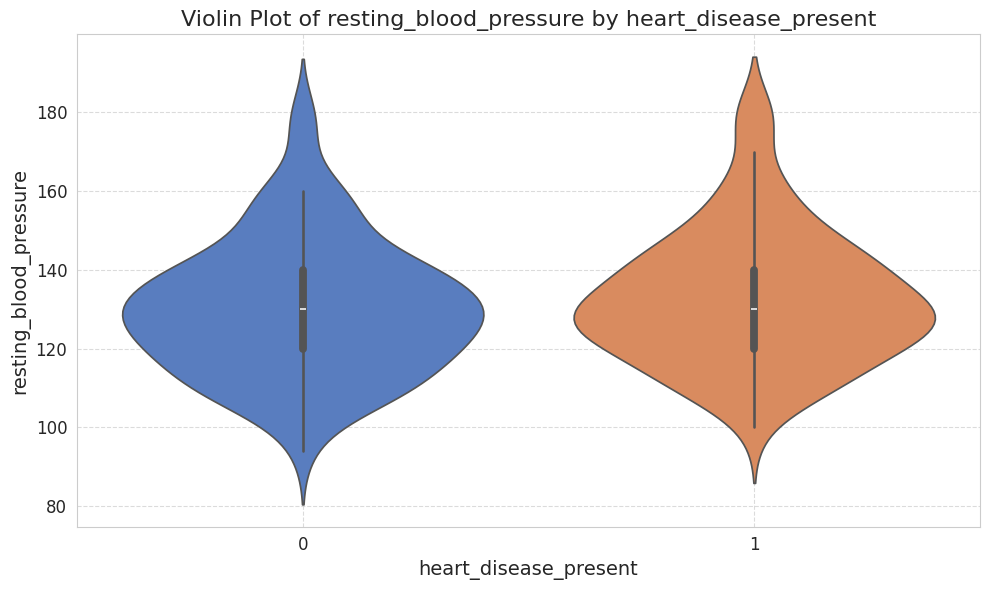

Observation for resting_blood_pressure (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



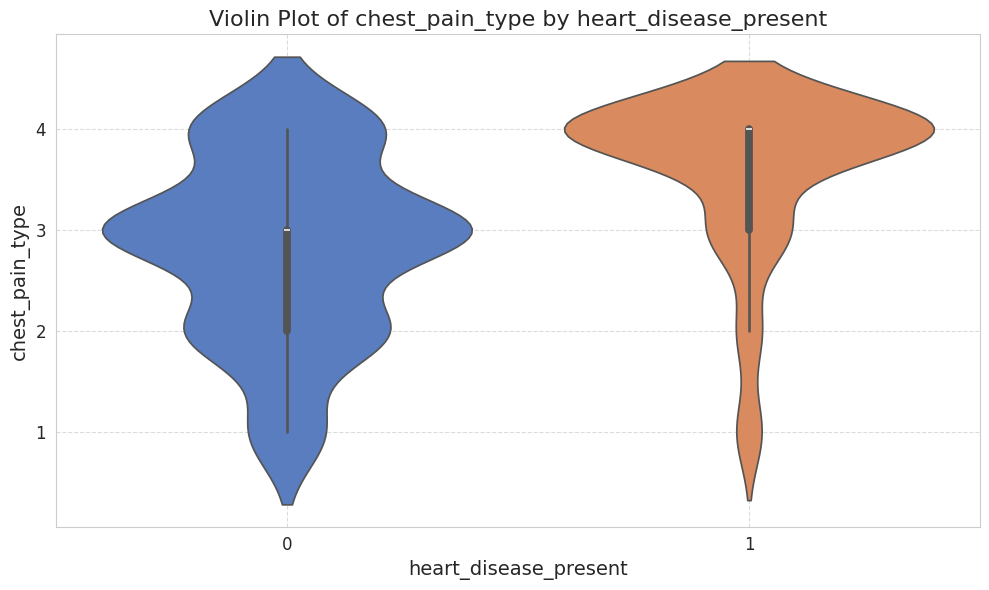

Observation for chest_pain_type (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



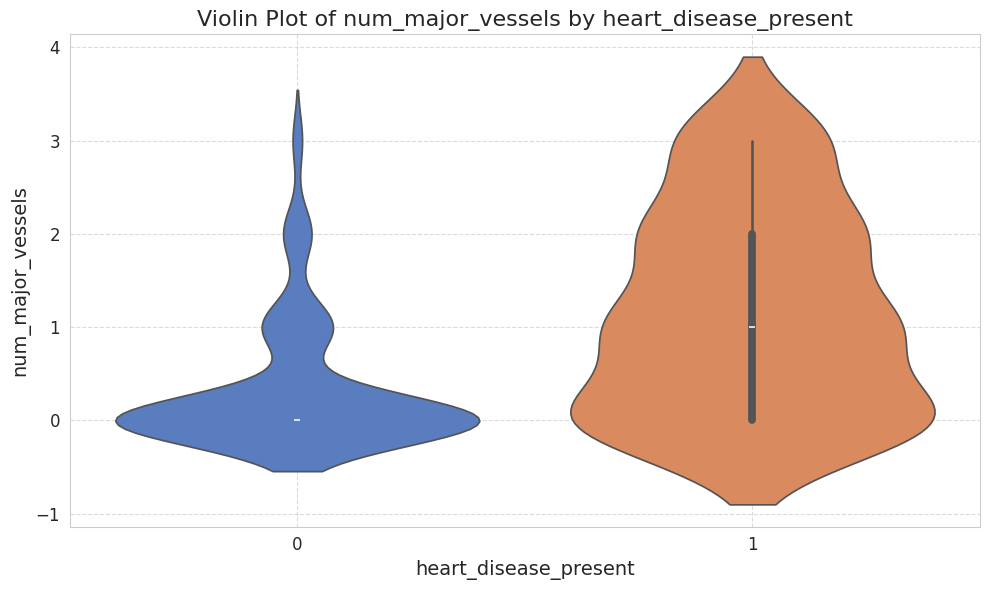

Observation for num_major_vessels (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



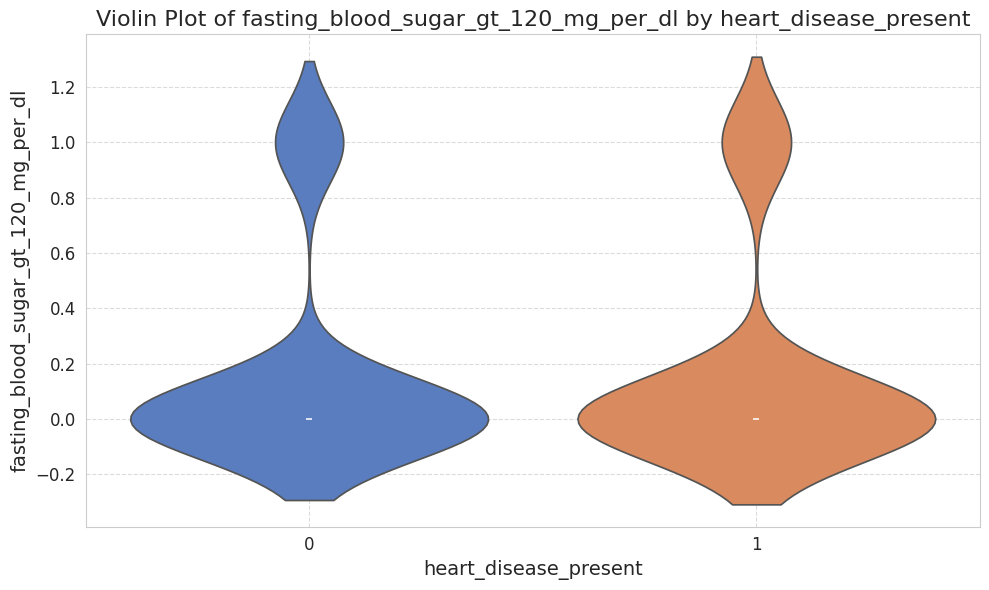

Observation for fasting_blood_sugar_gt_120_mg_per_dl (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



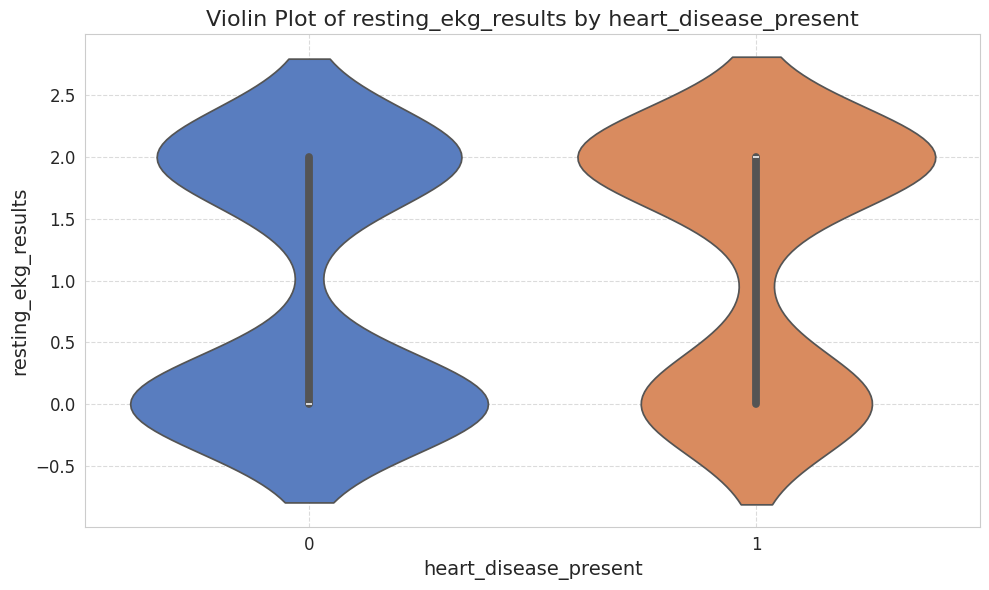

Observation for resting_ekg_results (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



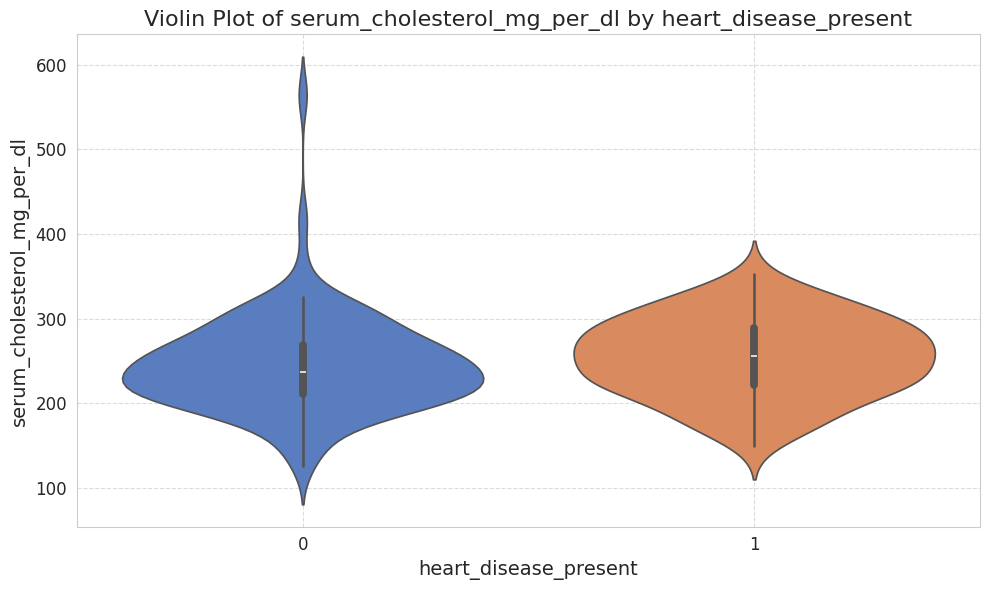

Observation for serum_cholesterol_mg_per_dl (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



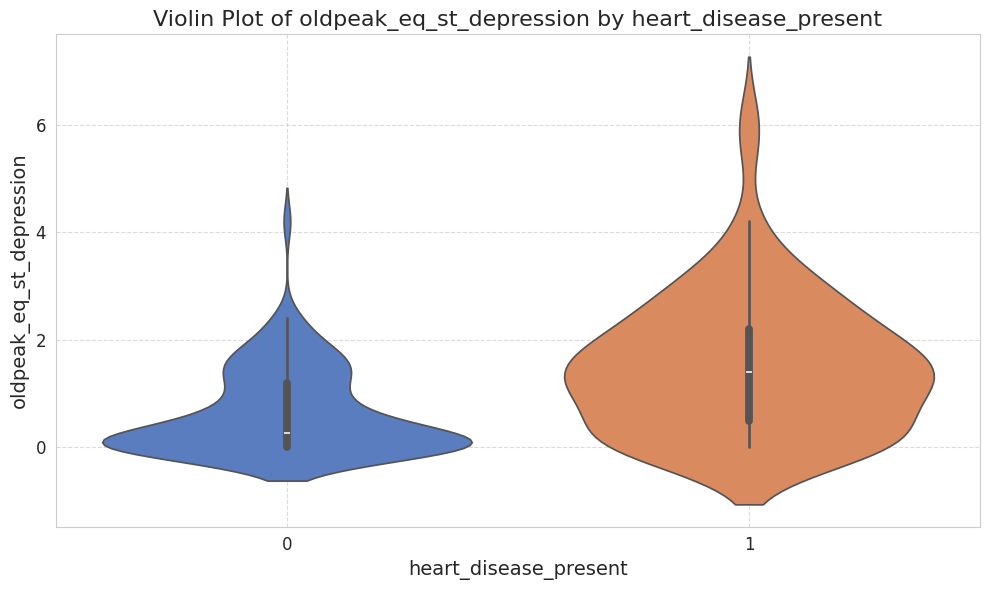

Observation for oldpeak_eq_st_depression (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



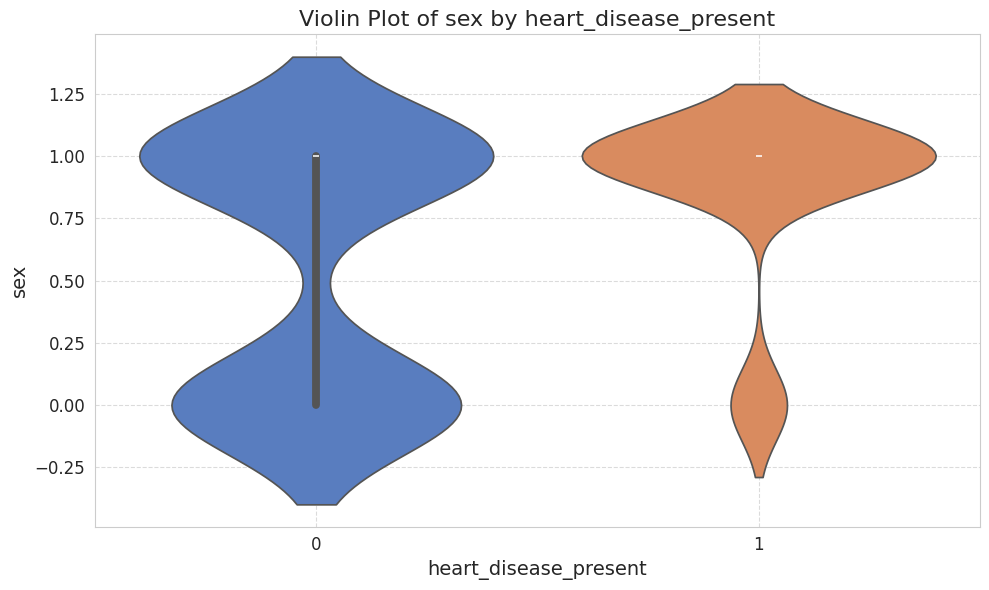

Observation for sex (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



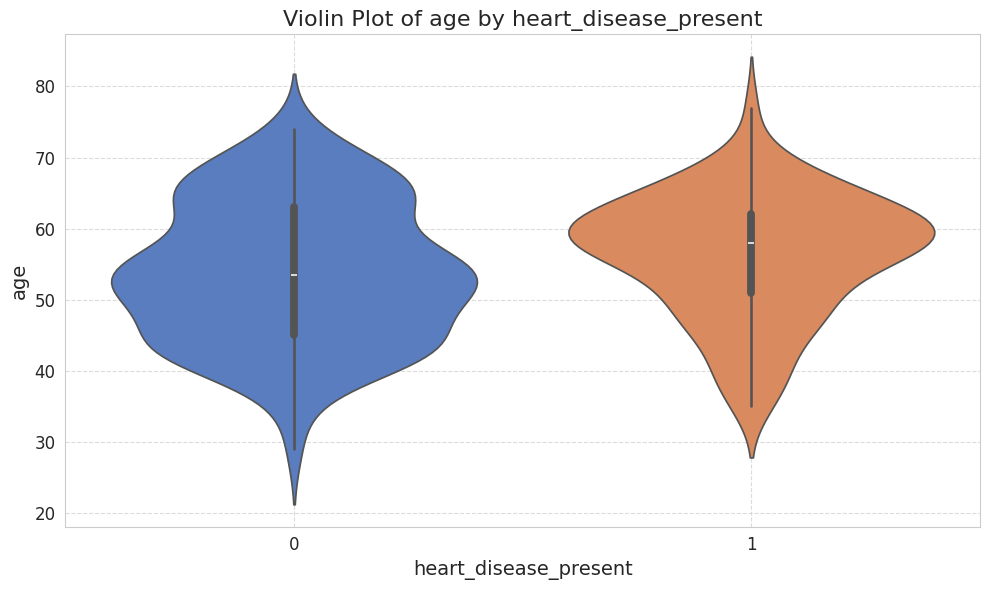

Observation for age (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



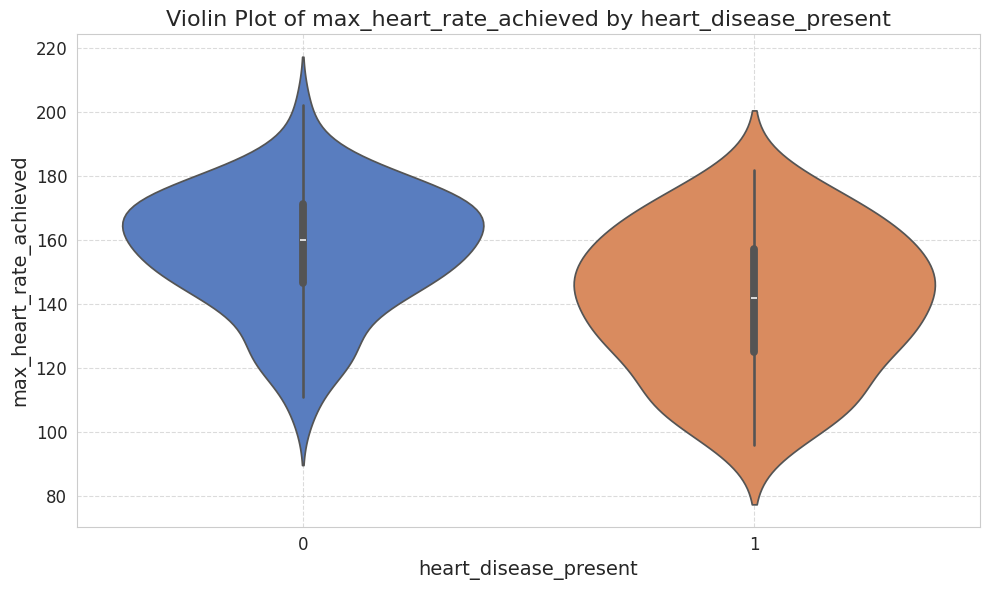

Observation for max_heart_rate_achieved (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------



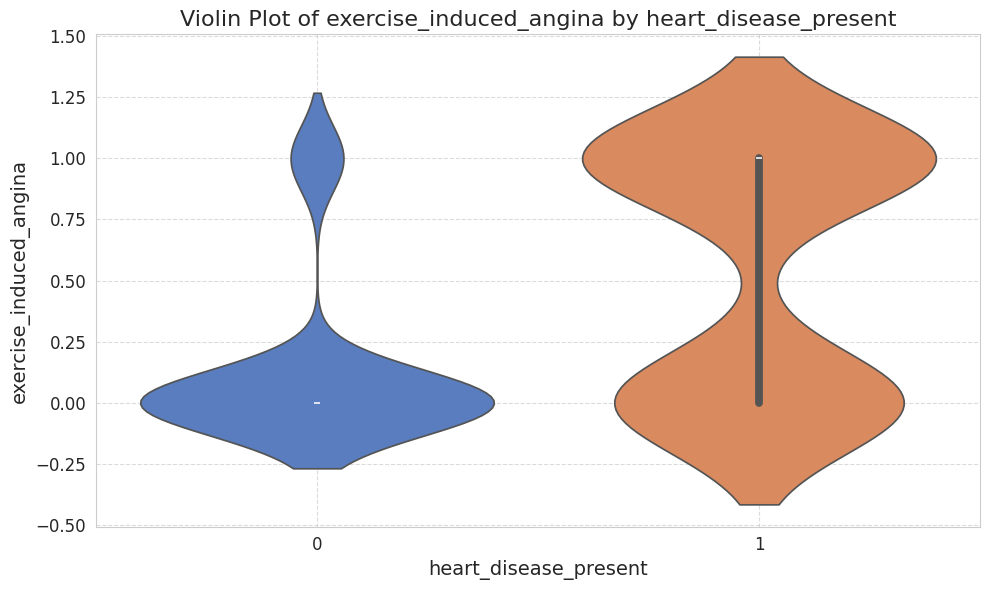

Observation for exercise_induced_angina (Violin Plot):
  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.
  - Wider sections indicate higher probability density, helping to see where most data points lie.
  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.
---------------------------------------------------


--- End of SECTION 5: Exploratory Data Analysis ---


In [ ]:
print('\n#########################################################')
print('SECTION 5: Perform Complete Exploratory Data Analysis - Summary')
print('#########################################################')

# What is happening: This section performs a comprehensive Exploratory Data Analysis (EDA) to understand the dataset's characteristics, distributions, relationships between variables, and potential insights.
# Why it is required: EDA is crucial for gaining initial insights into the data, identifying patterns, detecting anomalies, testing hypotheses, and informing feature engineering and model selection decisions.
# Expected output: A series of well-formatted visualizations (histograms, boxplots, countplots, scatter plots, pairplots, heatmaps, etc.) with accompanying observations and interpretations.
# Importance in Data Science: EDA forms the foundation of any data science project, ensuring data quality, understanding, and guiding subsequent steps in the machine learning pipeline.

# Define the target variable (assuming it's defined in Section 3)
target_variable = 'heart_disease_present'

# Set professional plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12

# Get numerical and categorical columns for plotting
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Remove 'patient_id' from plotting considerations as it's an identifier
if 'patient_id' in numerical_cols:
    numerical_cols.remove('patient_id')
if 'patient_id' in categorical_cols:
    categorical_cols.remove('patient_id')

# Ensure target_variable is not in numerical_cols for distribution plots
if target_variable in numerical_cols:
    numerical_cols.remove(target_variable)

print("\n--- 5.1: Distribution of Numerical Features (Histograms and KDE) ---")
# What is happening: Generating histograms and Kernel Density Estimate (KDE) plots for all numerical features.
# Why it is required: To visualize the distribution of individual numerical variables, identify their central tendency, spread, skewness, and modality.
# Expected output: A series of histogram/KDE plots.
# Importance in Data Science: Helps in understanding data variability, detecting outliers, and assessing if data transformation (e.g., log transform) might be necessary.
for col in numerical_cols:
    plt.figure(figsize=(12, 6))
    sns.histplot(df[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribution of {col}', fontsize=16)
    plt.xlabel(col)
    plt.ylabel('Frequency / Density')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col}:")
    print(f"  - Skewness: {df[col].skew():.2f}")
    print(f"  - Kurtosis: {df[col].kurtosis():.2f}")
    if df[col].skew() > 0.5: print("  - Distribution appears positively skewed.")
    elif df[col].skew() < -0.5: print("  - Distribution appears negatively skewed.")
    else: print("  - Distribution appears relatively symmetric.")
    print("  - Peaks (modes) indicate common value ranges. Multiple peaks might suggest distinct sub-populations.")
    print("---------------------------------------------------\n")

print("\n--- 5.2: Count Plots for Categorical Features ---")
# What is happening: Generating count plots for all categorical features.
# Why it is required: To visualize the frequency of each category within categorical variables, providing insight into their balance and commonality.
# Expected output: A series of bar plots.
# Importance in Data Science: Helps in identifying imbalanced categories, which can affect model training, and understanding the prevalence of different attributes.
for col in categorical_cols:
    plt.figure(figsize=(12, 6))
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f'Count of {col}', fontsize=16)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col}:")
    print(f"  - Value Counts:\n{df[col].value_counts().to_string()}")
    print("  - Visually represents the distribution of categories. Imbalance might require special handling (e.g., oversampling/undersampling).")
    print("---------------------------------------------------\n")

print("\n--- 5.3: Pie Charts for Binary/Low Cardinality Categorical Features ---")
# What is happening: Generating pie charts for categorical features with a small number of unique values.
# Why it is required: To show the proportion of each category relative to the whole, especially useful for binary or low cardinality variables.
# Expected output: A series of pie charts.
# Importance in Data Science: Provides a quick visual summary of class proportions, useful for understanding target variable balance or feature value distribution.
for col in categorical_cols:
    if df[col].nunique() <= 5: # Limit to features with 5 or fewer unique values for clarity
        plt.figure(figsize=(8, 8))
        df[col].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, cmap='Pastel1', wedgeprops={'edgecolor': 'black'})
        plt.title(f'Proportion of {col}', fontsize=16)
        plt.ylabel('') # Hide default 'count' label
        plt.tight_layout()
        plt.show()
        print(f"Observation for {col}:")
        print(f"  - Proportion of each category: {df[col].value_counts(normalize=True).to_dict()}")
        print("  - Clearly shows the percentage contribution of each category.")
        print("---------------------------------------------------\n")

print("\n--- 5.4: Box Plots for Numerical Features (Outlier Detection Overview) ---")
# What is happening: Generating box plots for all numerical features.
# Why it is required: To visualize the five-number summary (minimum, first quartile, median, third quartile, maximum) and detect potential outliers.
# Expected output: A series of box plots.
# Importance in Data Science: Essential for understanding the spread of data and identifying extreme values that may warrant further investigation or treatment.
for col in numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(y=df[col], color='lightcoral')
    plt.title(f'Box Plot of {col}', fontsize=16)
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col}:")
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    if not outliers.empty:
        print(f"  - Potential outliers detected (values outside 1.5*IQR from quartiles). Count: {len(outliers)}.")
        print(f"  - Outlier values (sample): {outliers.head().tolist()}...")
    else:
        print("  - No significant outliers detected based on IQR method.")
    print("  - Provides a visual summary of data distribution and highlights potential extreme values.")
    print("---------------------------------------------------\n")

print("\n--- 5.5: Relationship between Features and Target Variable ---")
# What is happening: Analyzing the relationship between features and the target variable ('heart_disease_present').
# Why it is required: To identify which features are most strongly associated with the presence of heart disease, aiding in feature selection and understanding.
# Expected output: Various plots (e.g., box plots for numerical vs. target, count plots for categorical vs. target).
# Importance in Data Science: Crucial for building intuition about the problem and identifying predictive features.

print("\n5.5.1: Numerical Features vs. Target Variable (Box Plots) ")
for col in numerical_cols:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x=target_variable, y=col, palette='pastel')
    plt.title(f'{col} vs. {target_variable}', fontsize=16)
    plt.xlabel(target_variable)
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col} vs. {target_variable}:")
    print("  - Compares the distribution of the numerical feature across target classes.")
    print("  - Differences in medians or ranges between heart disease (1) and no heart disease (0) groups suggest predictive power.")
    print("---------------------------------------------------\n")

print("\n5.5.2: Categorical Features vs. Target Variable (Count Plots / Stacked Bar Charts) ")
for col in categorical_cols:
    plt.figure(figsize=(12, 6))
    sns.countplot(data=df, x=col, hue=target_variable, palette='deep')
    plt.title(f'Distribution of {col} by {target_variable}', fontsize=16)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.legend(title=target_variable, labels=['No Heart Disease', 'Heart Disease'])
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col} vs. {target_variable}:")
    cross_tab = pd.crosstab(df[col], df[target_variable], normalize='index') * 100
    print(f"  - Proportional distribution of {col} categories across {target_variable} classes:\n{cross_tab.round(2).to_string()}")
    print("  - Uneven distributions or significant differences in proportions indicate a relationship between the categorical feature and heart disease presence.")
    print("---------------------------------------------------\n")

print("\n--- 5.6: Correlation Matrix (Heatmap) ---")
# What is happening: Calculating and visualizing the Pearson correlation matrix for numerical features.
# Why it is required: To understand the linear relationships between all pairs of numerical variables, including the target variable.
# Expected output: A heatmap showing correlation coefficients.
# Importance in Data Science: Helps in identifying highly correlated features (multicollinearity), which can affect model stability, and features strongly correlated with the target variable, indicating their predictive power.
plt.figure(figsize=(14, 12))
sns.heatmap(df[numerical_cols + [target_variable]].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features', fontsize=18)
plt.tight_layout()
plt.show()
print("Observation for Correlation Matrix:")
print("  - Values close to 1 or -1 indicate strong positive or negative linear correlation, respectively.")
print("  - Values close to 0 suggest weak or no linear correlation.")
print("  - High correlation between features (e.g., > 0.8) might suggest multicollinearity, requiring feature selection.")
print("  - Features with higher absolute correlation with the target variable are potentially more predictive.")
print("---------------------------------------------------\n")

print("\n--- 5.7: Pairplot for key numerical features ---")
# What is happening: Generating a pairplot for a selection of numerical features, colored by the target variable.
# Why it is required: To visualize pairwise relationships between variables and their distributions, providing a holistic view of the dataset's structure.
# Expected output: A grid of scatter plots and histograms.
# Importance in Data Science: Useful for identifying clusters, trends, and interactions between features, especially in relation to the target variable.
# Selecting a subset of numerical columns for better readability if many exist
if len(numerical_cols) > 5:
    # Choose the top 4 most correlated features with the target + age and sex if not already included
    top_correlated_features = df[numerical_cols + [target_variable]].corr()[target_variable].abs().sort_values(ascending=False).index.tolist()[1:6] # Exclude target_variable itself
    pairplot_cols = list(set(top_correlated_features + ['age', 'sex'])) # Ensure age and sex are in if they exist and are numerical
    pairplot_cols = [col for col in pairplot_cols if col in numerical_cols]
else:
    pairplot_cols = numerical_cols

if pairplot_cols:
    print(f"Generating pairplot for selected columns: {pairplot_cols}")
    sns.pairplot(df[pairplot_cols + [target_variable]], hue=target_variable, palette='coolwarm', diag_kind='kde')
    plt.suptitle('Pairplot of Selected Numerical Features by Heart Disease Presence', y=1.02, fontsize=18) # Adjust suptitle position
    plt.tight_layout()
    plt.show()
    print("Observation for Pairplot:")
    print("  - Scatter plots show relationships between pairs of features. Different colored clusters might indicate separation based on heart disease.")
    print("  - Diagonal plots show the distribution of individual features. Differences in distributions between target classes are visible.")
    print("  - Helps to visually identify linear or non-linear relationships and potential feature interactions.")
else:
    print("Not enough numerical columns to generate a meaningful pairplot.")
print("---------------------------------------------------\n")

print("\n--- 5.8: Violin Plots for Numerical Features vs. Target ---")
# What is happening: Generating violin plots for selected numerical features against the target variable.
# Why it is required: Violin plots combine box plots with kernel density estimation, showing both the distribution shape and statistical summary across target classes.
# Expected output: A series of violin plots.
# Importance in Data Science: Offers a richer understanding of data distribution than box plots, revealing multimodality and density variations.
for col in numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.violinplot(data=df, x=target_variable, y=col, palette='muted')
    plt.title(f'Violin Plot of {col} by {target_variable}', fontsize=16)
    plt.xlabel(target_variable)
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col} (Violin Plot):")
    print("  - Visualizes the full distribution shape, including median, quartiles, and density estimation, for each target group.")
    print("  - Wider sections indicate higher probability density, helping to see where most data points lie.")
    print("  - Differences in shape and density between heart disease (1) and no heart disease (0) groups can reveal important insights.")
    print("---------------------------------------------------\n")

print("\n--- End of SECTION 5: Exploratory Data Analysis ---")


# SECTION 6: Perform Outlier Detection


SECTION 6: Perform Outlier Detection - Summary

--- 6.1: Outlier Detection using Boxplots (Before Treatment) ---


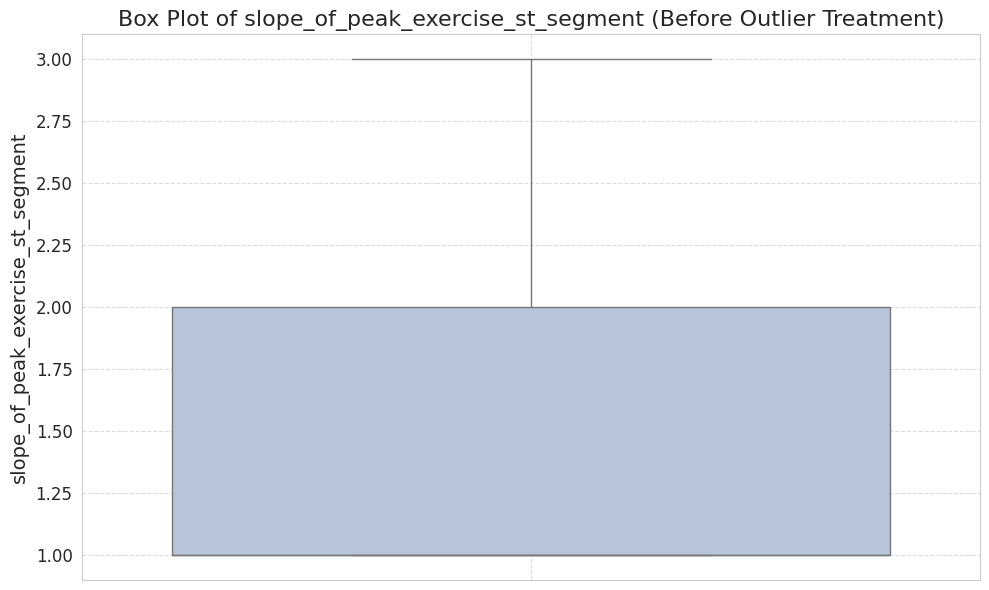

Observation for slope_of_peak_exercise_st_segment (Before Treatment):
  - No significant outliers detected using the IQR method.
---------------------------------------------------



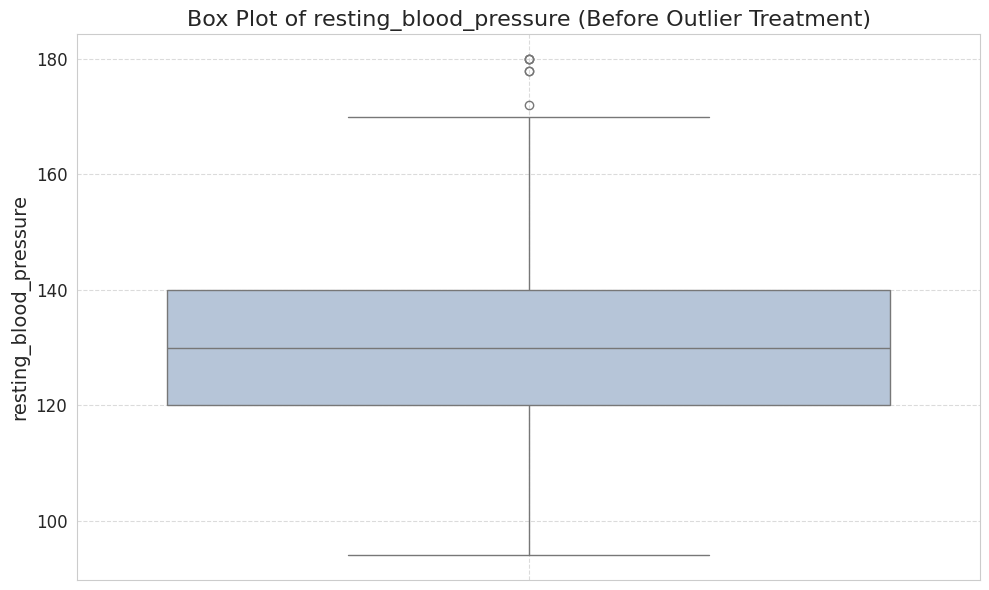

Observation for resting_blood_pressure (Before Treatment):
  - Outliers are present, defined as values below 90.00 or above 170.00.
  - Number of outliers: 6. Percentage of outliers: 3.33%
---------------------------------------------------



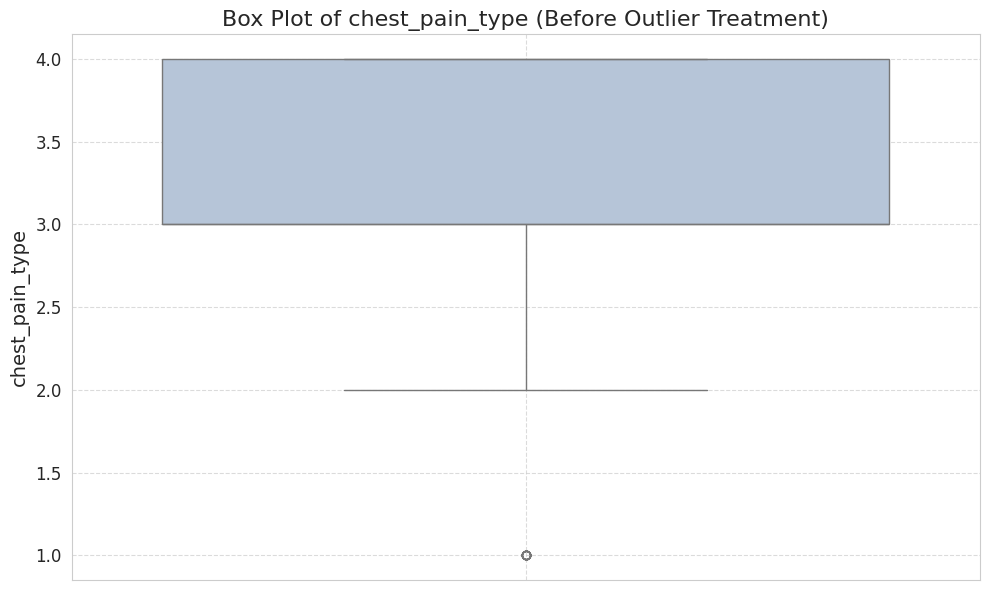

Observation for chest_pain_type (Before Treatment):
  - Outliers are present, defined as values below 1.50 or above 5.50.
  - Number of outliers: 13. Percentage of outliers: 7.22%
---------------------------------------------------



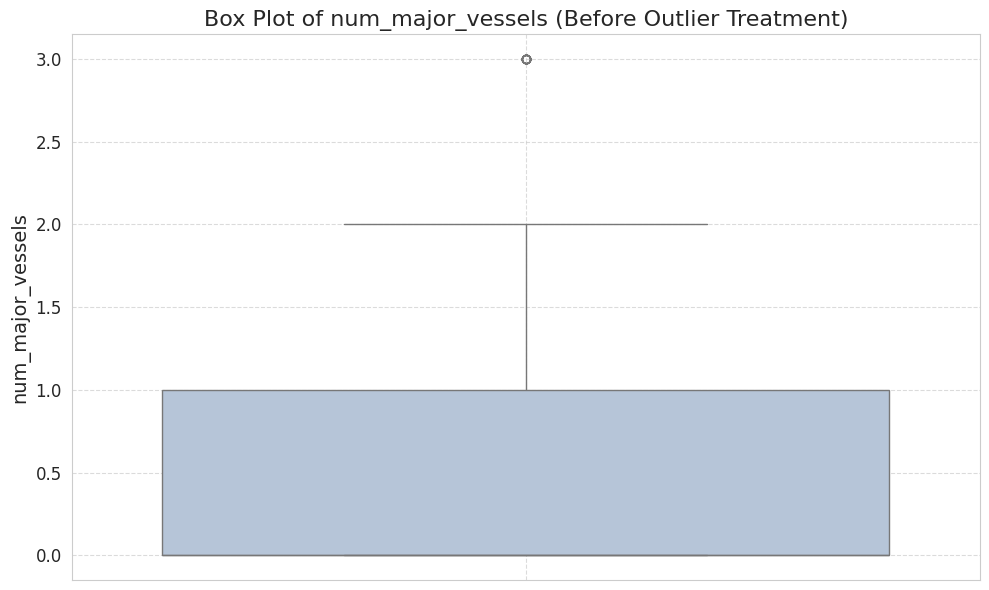

Observation for num_major_vessels (Before Treatment):
  - Outliers are present, defined as values below -1.50 or above 2.50.
  - Number of outliers: 14. Percentage of outliers: 7.78%
---------------------------------------------------



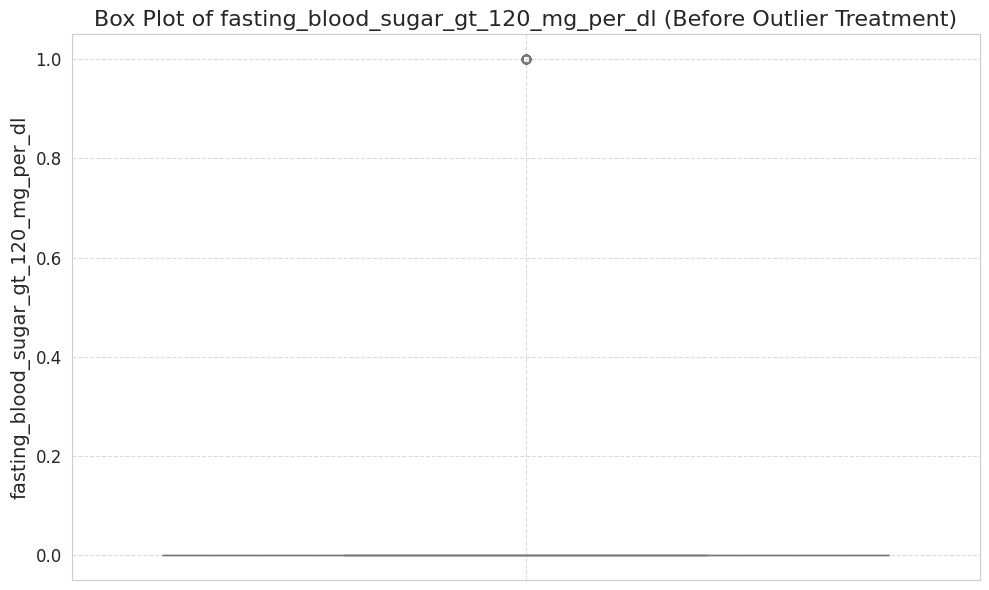

Observation for fasting_blood_sugar_gt_120_mg_per_dl (Before Treatment):
  - Outliers are present, defined as values below 0.00 or above 0.00.
  - Number of outliers: 29. Percentage of outliers: 16.11%
---------------------------------------------------



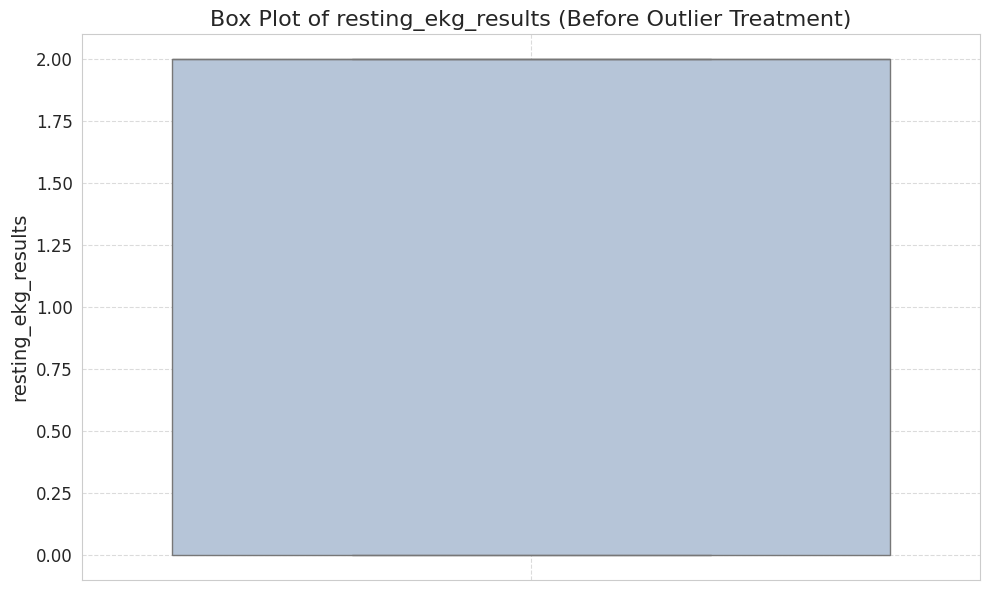

Observation for resting_ekg_results (Before Treatment):
  - No significant outliers detected using the IQR method.
---------------------------------------------------



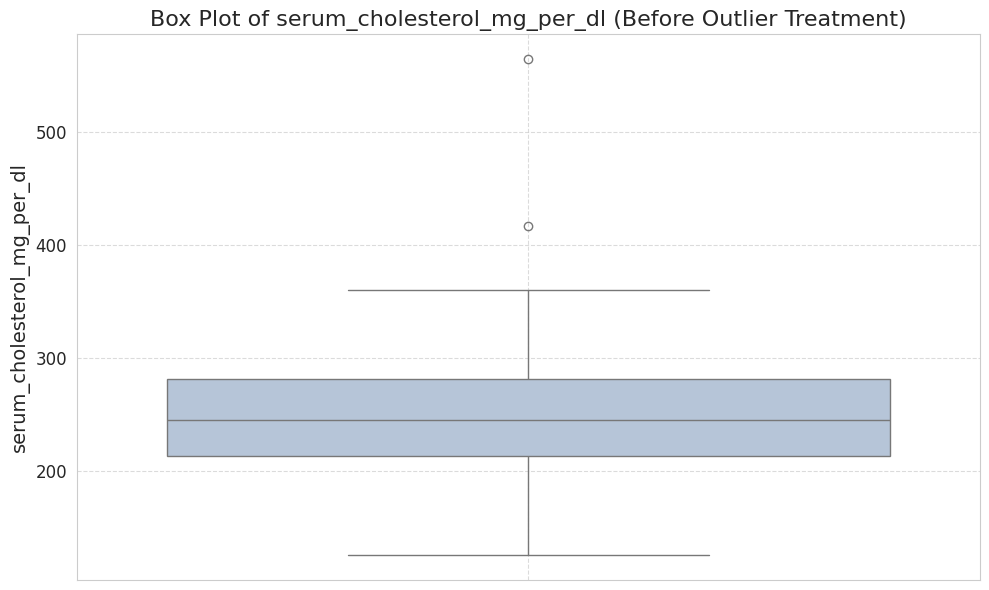

Observation for serum_cholesterol_mg_per_dl (Before Treatment):
  - Outliers are present, defined as values below 112.50 or above 382.50.
  - Number of outliers: 2. Percentage of outliers: 1.11%
---------------------------------------------------



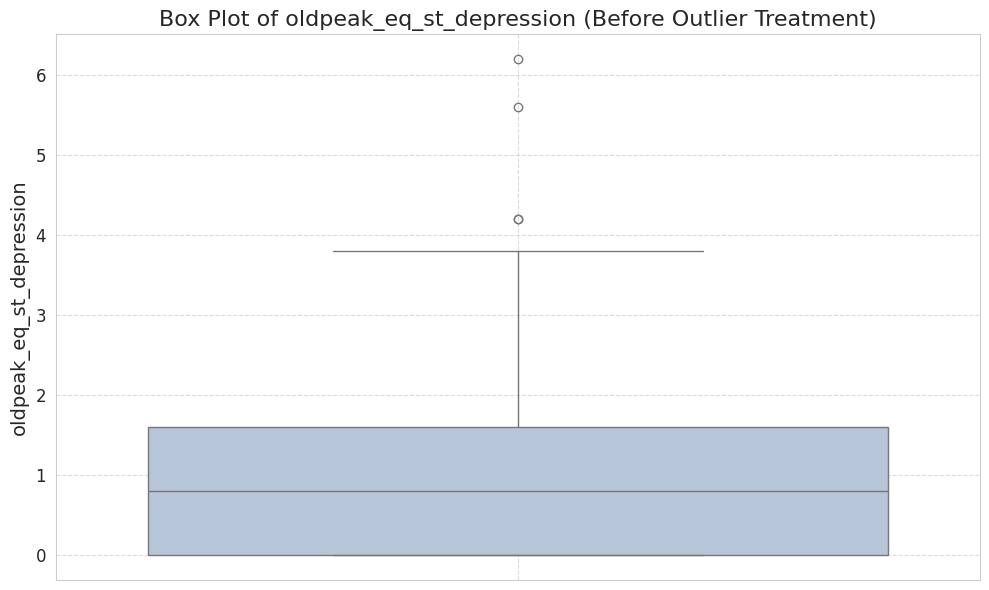

Observation for oldpeak_eq_st_depression (Before Treatment):
  - Outliers are present, defined as values below -2.40 or above 4.00.
  - Number of outliers: 4. Percentage of outliers: 2.22%
---------------------------------------------------



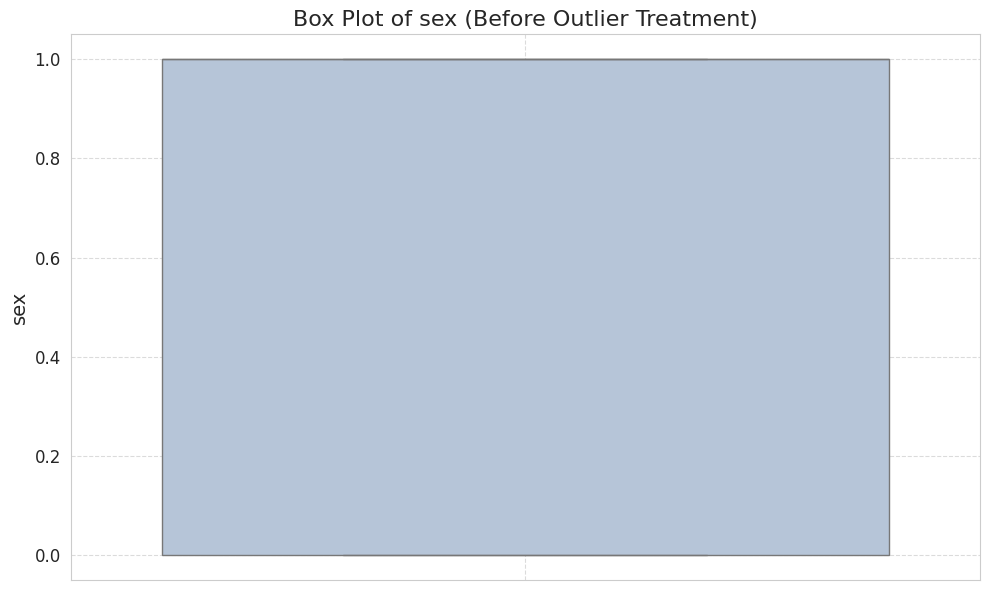

Observation for sex (Before Treatment):
  - No significant outliers detected using the IQR method.
---------------------------------------------------



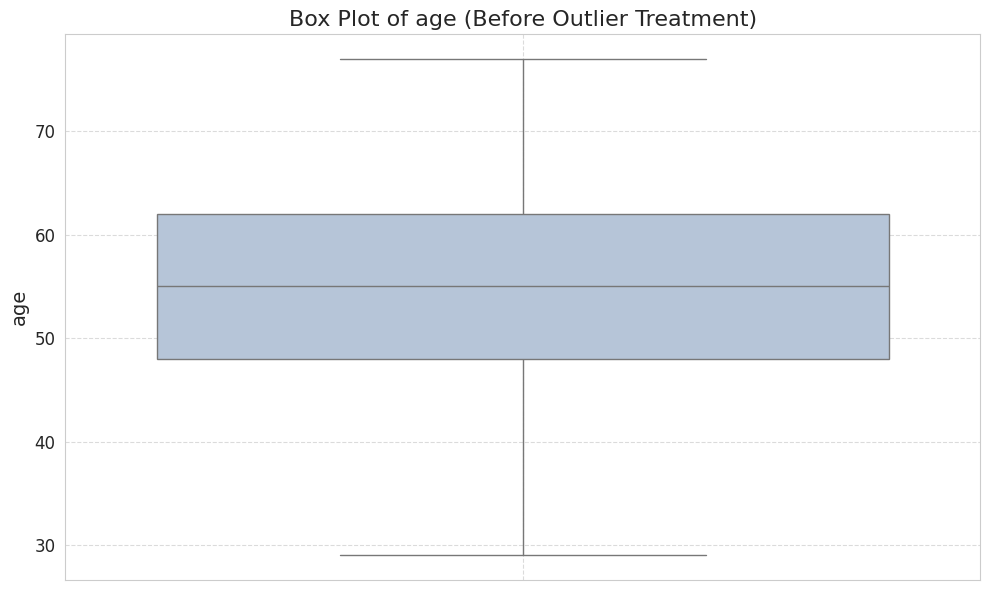

Observation for age (Before Treatment):
  - No significant outliers detected using the IQR method.
---------------------------------------------------



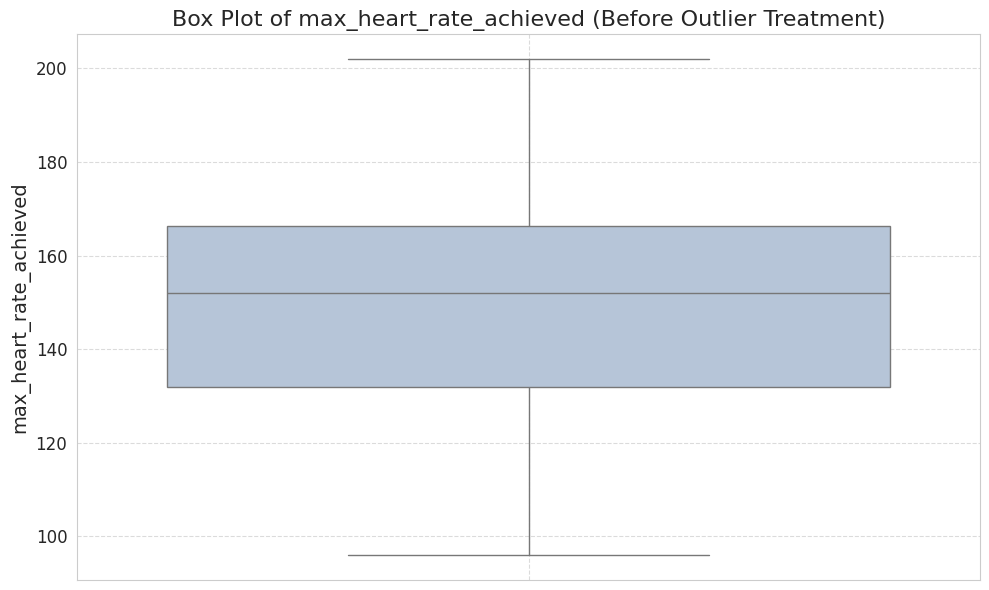

Observation for max_heart_rate_achieved (Before Treatment):
  - No significant outliers detected using the IQR method.
---------------------------------------------------



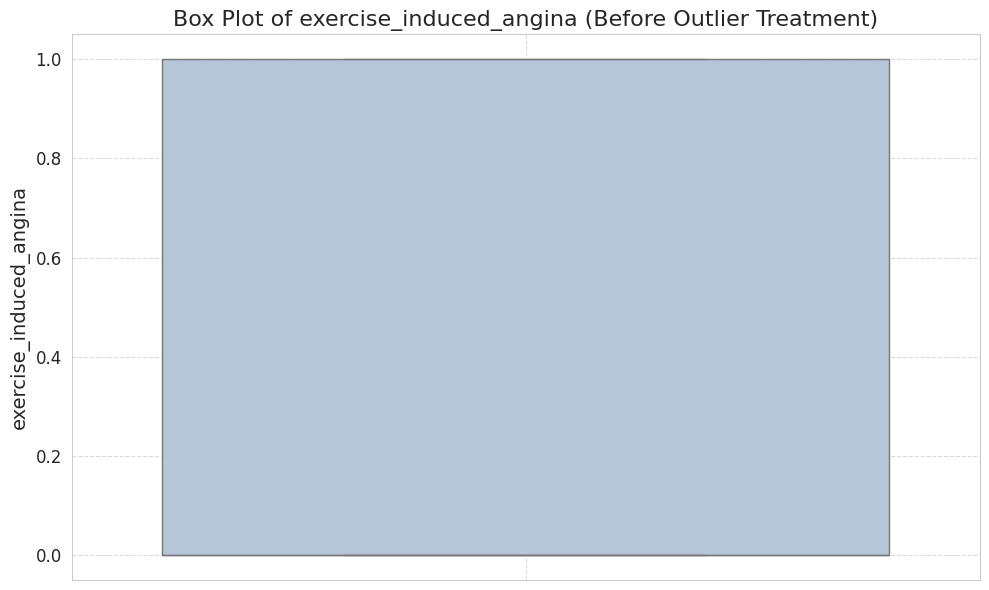

Observation for exercise_induced_angina (Before Treatment):
  - No significant outliers detected using the IQR method.
---------------------------------------------------


--- 6.2: Outlier Treatment using IQR Method ---
  - Outliers in 'resting_blood_pressure' capped at [90.00, 170.00].
  - Outliers in 'chest_pain_type' capped at [1.50, 5.50].
  - Outliers in 'num_major_vessels' capped at [-1.50, 2.50].
  - Outliers in 'fasting_blood_sugar_gt_120_mg_per_dl' capped at [0.00, 0.00].
  - Outliers in 'serum_cholesterol_mg_per_dl' capped at [112.50, 382.50].
  - Outliers in 'oldpeak_eq_st_depression' capped at [-2.40, 4.00].

Decision: Outliers in the following columns were capped using the IQR method: resting_blood_pressure, chest_pain_type, num_major_vessels, fasting_blood_sugar_gt_120_mg_per_dl, serum_cholesterol_mg_per_dl, oldpeak_eq_st_depression. Capping was chosen over removal to preserve data, especially if outliers represent valid but extreme observations relevant to heart disease

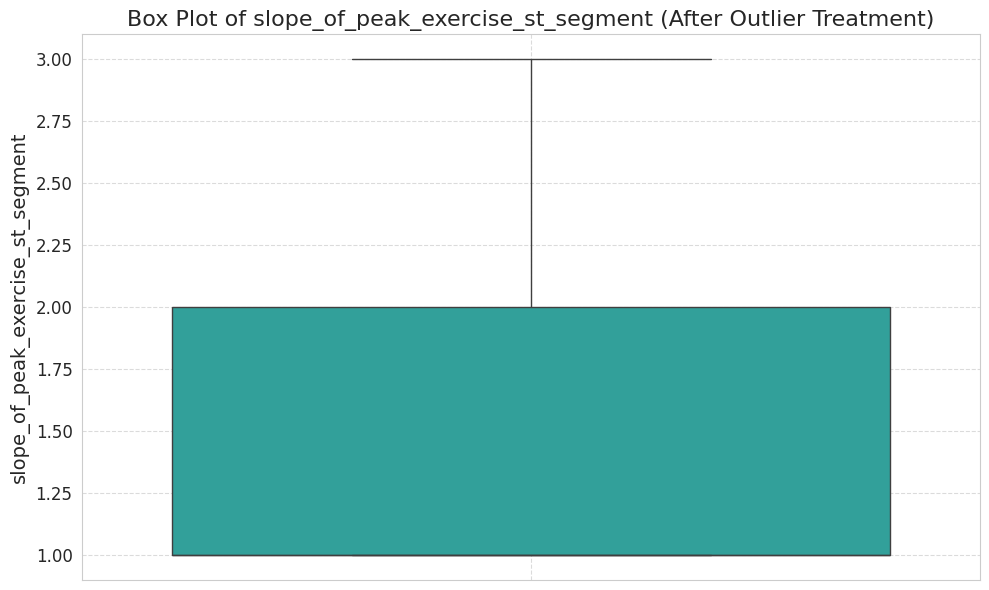

Observation for slope_of_peak_exercise_st_segment (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



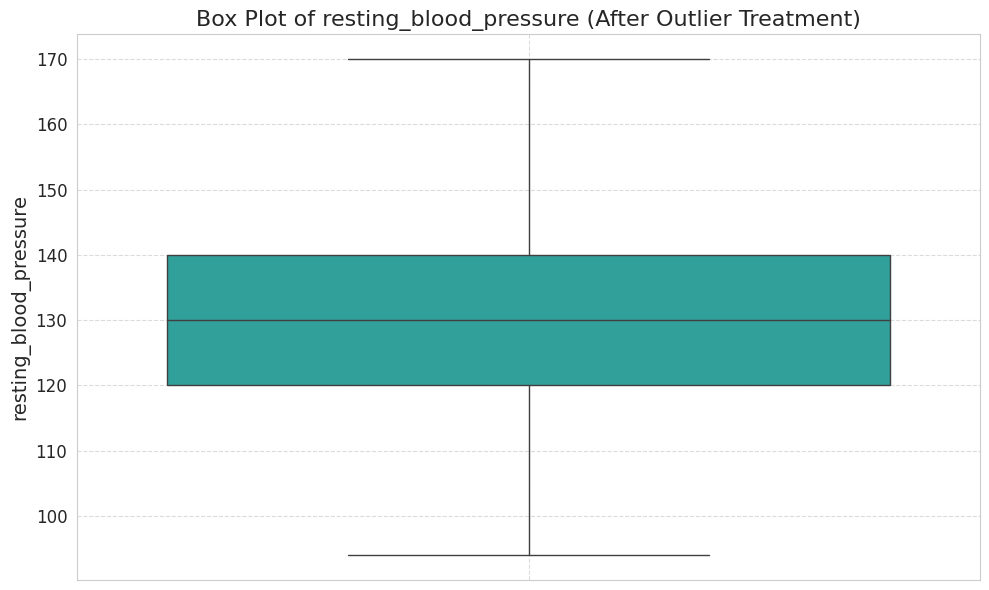

Observation for resting_blood_pressure (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



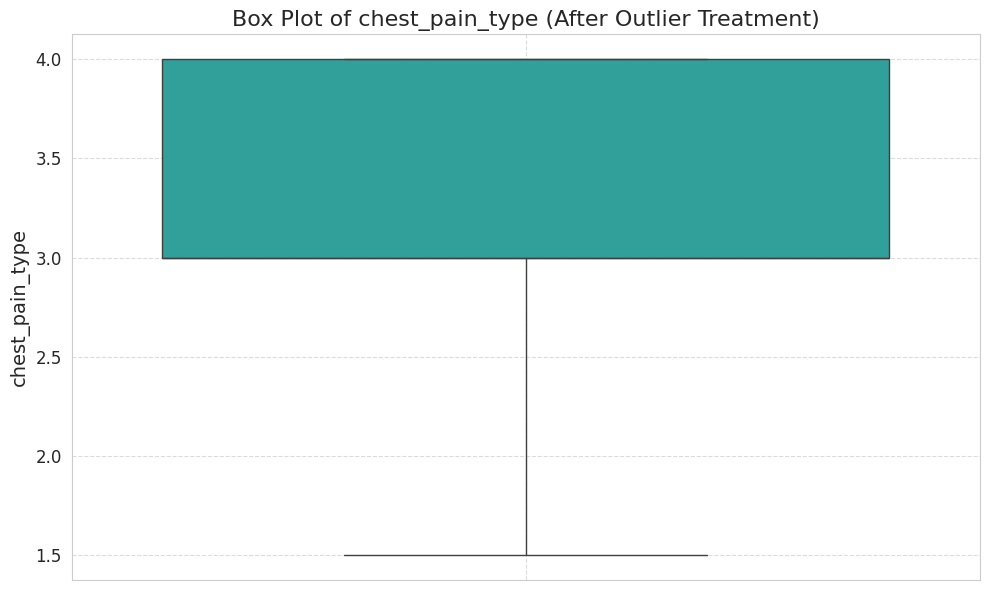

Observation for chest_pain_type (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



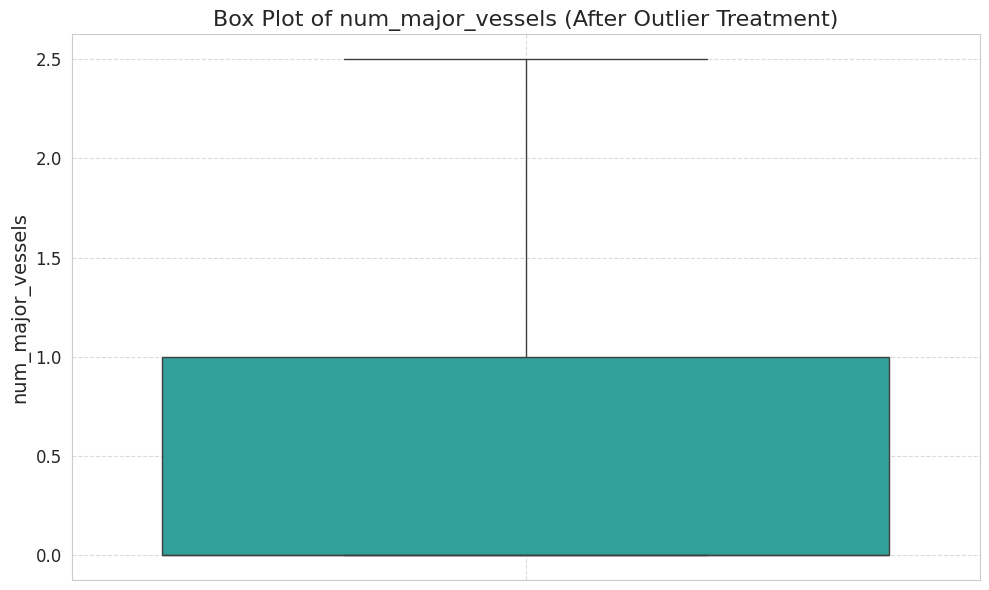

Observation for num_major_vessels (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



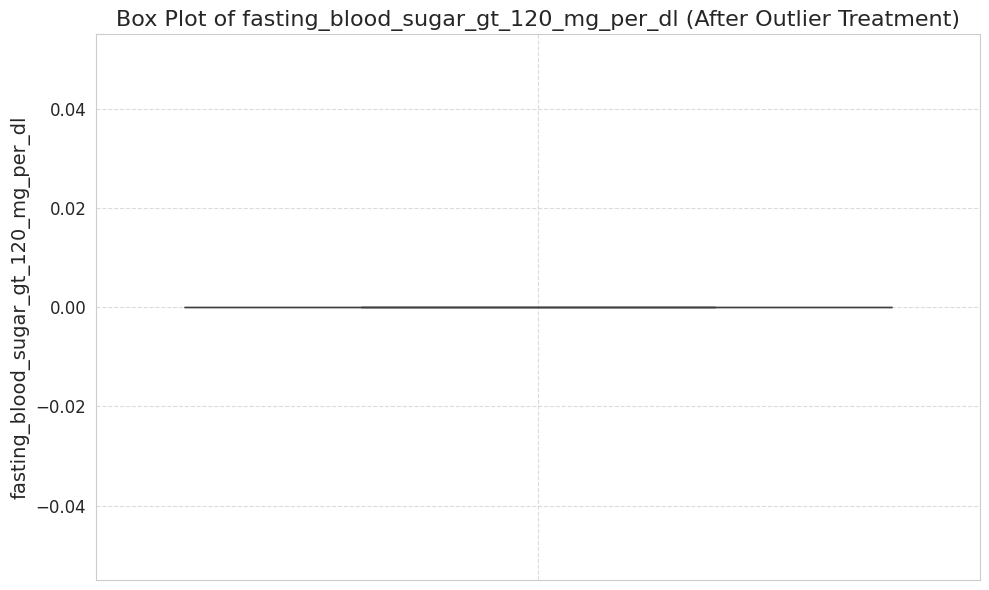

Observation for fasting_blood_sugar_gt_120_mg_per_dl (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



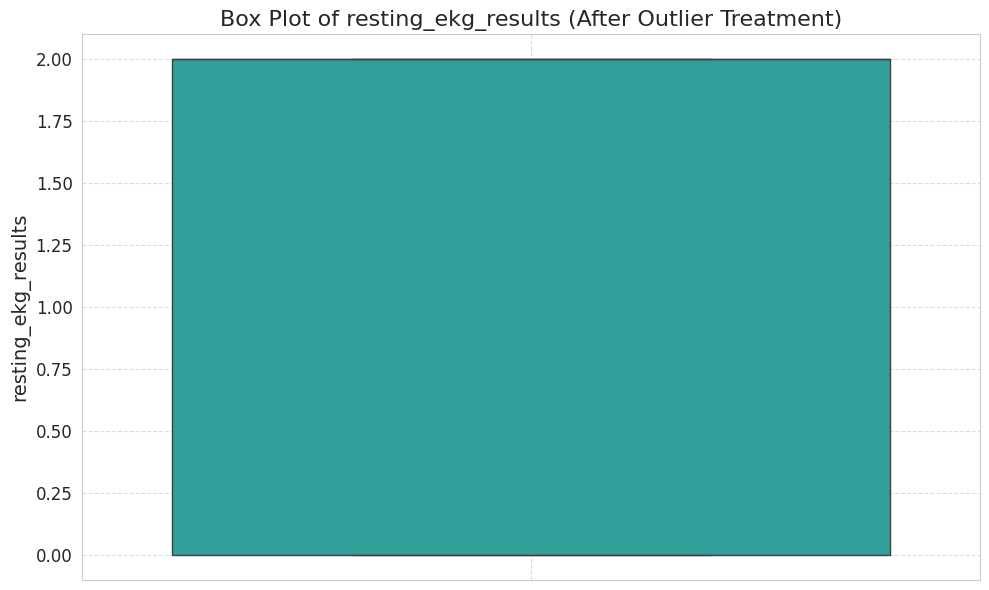

Observation for resting_ekg_results (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



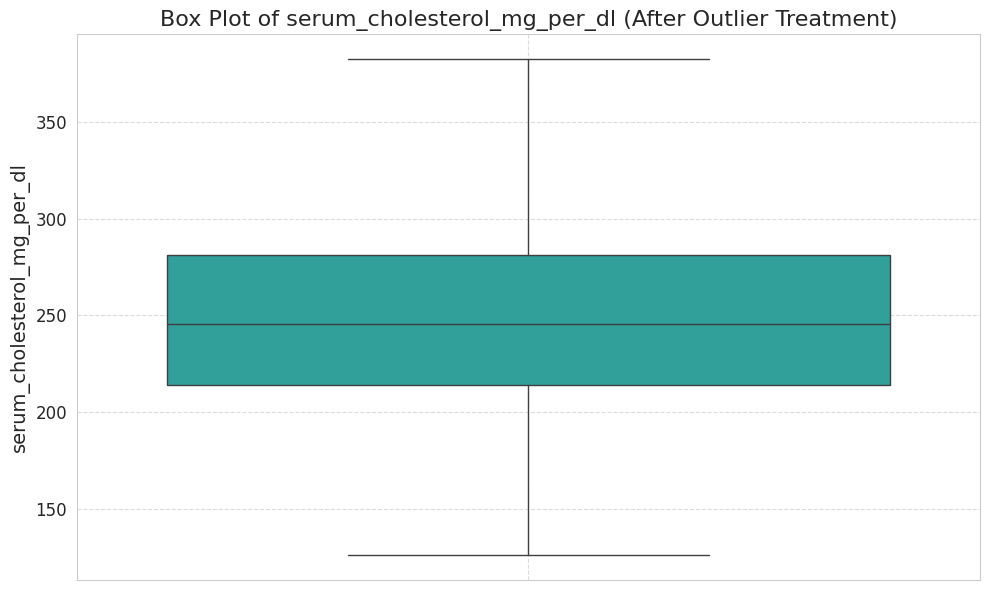

Observation for serum_cholesterol_mg_per_dl (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



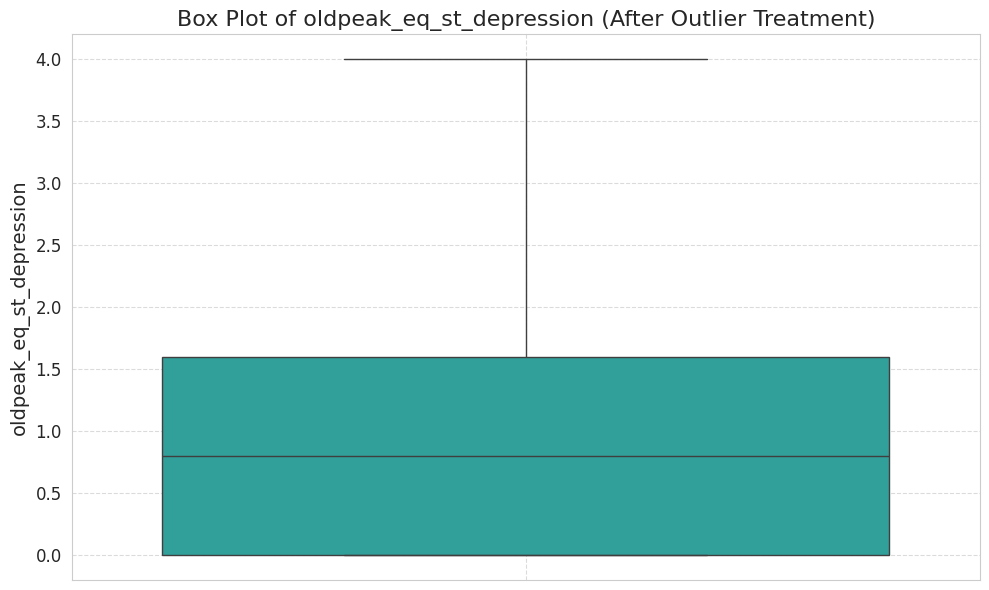

Observation for oldpeak_eq_st_depression (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



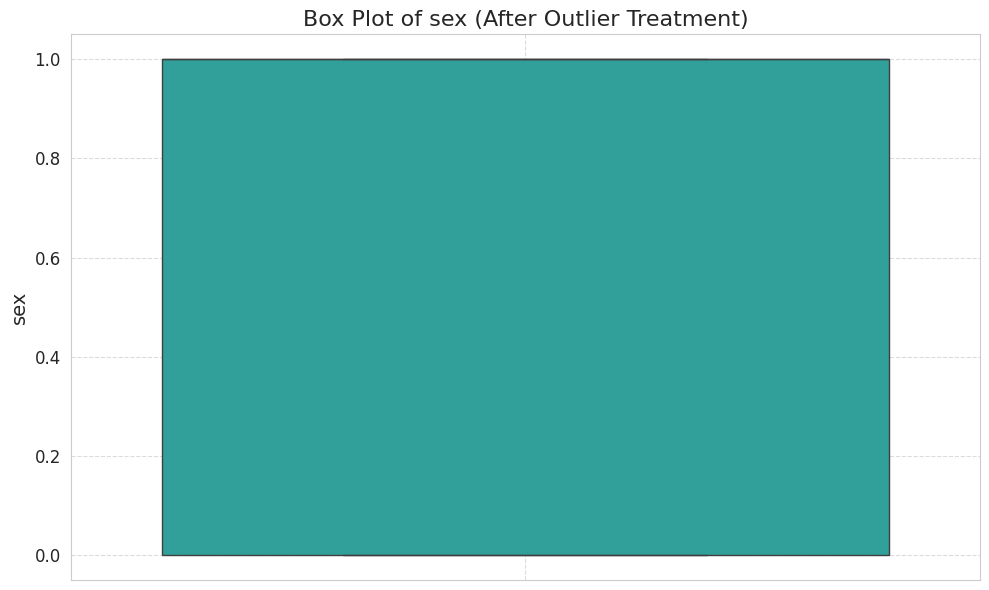

Observation for sex (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



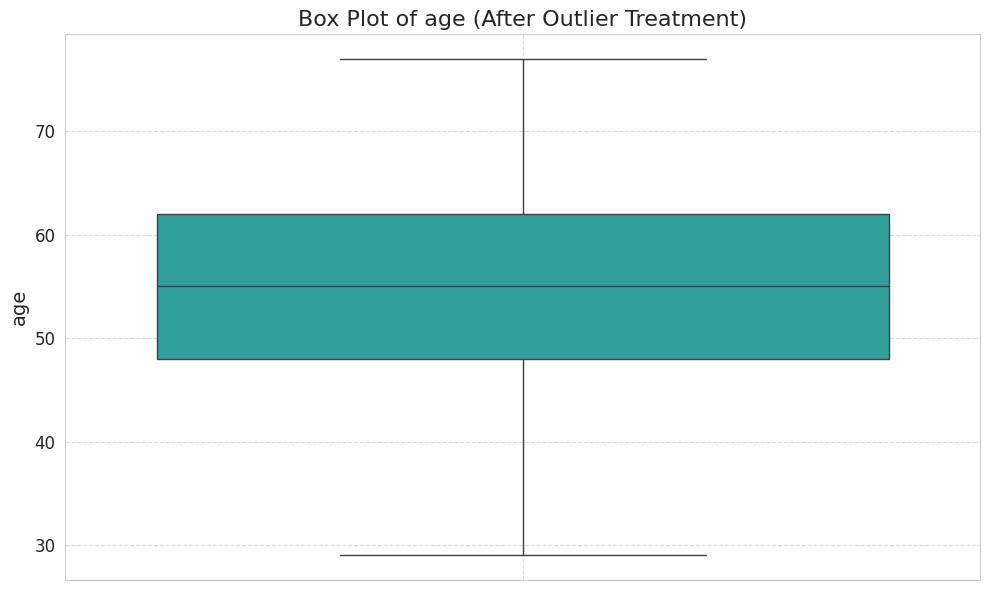

Observation for age (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



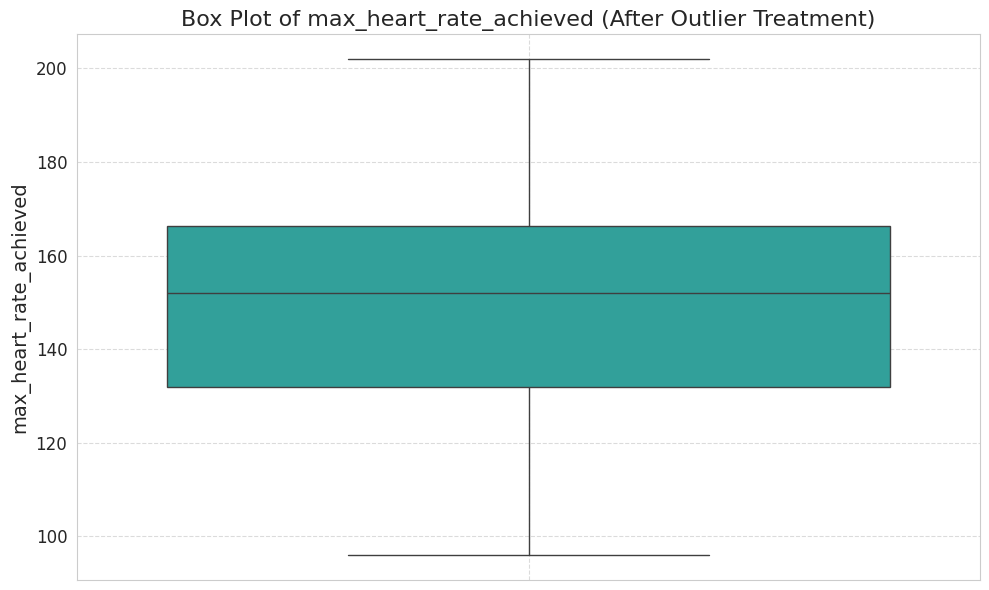

Observation for max_heart_rate_achieved (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------



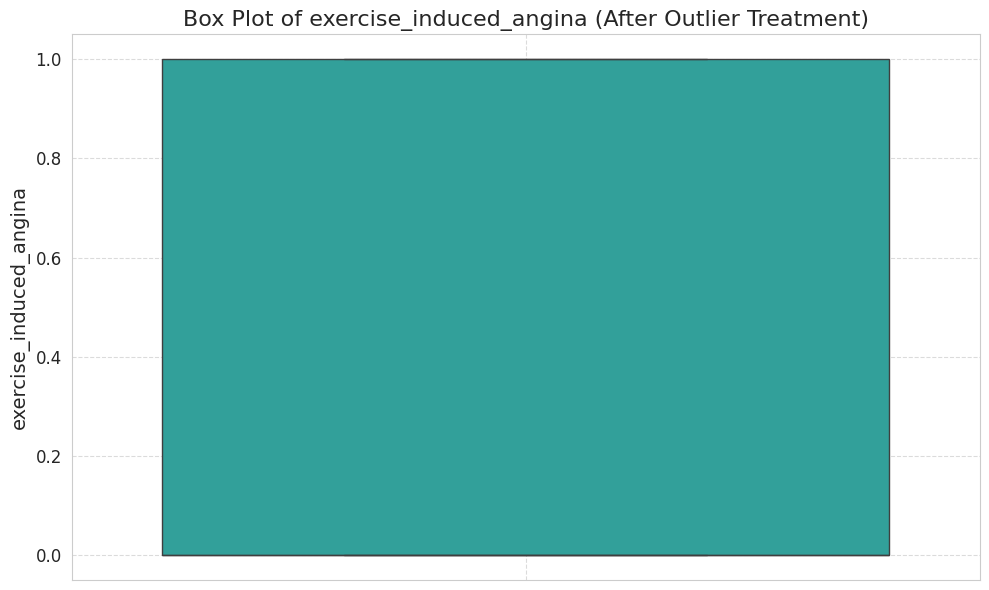

Observation for exercise_induced_angina (After Treatment):
  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.
---------------------------------------------------

DataFrame 'df' has been updated with outlier-treated numerical features.

--- End of SECTION 6: Outlier Detection ---


In [ ]:

print('SECTION 6: Perform Outlier Detection - Summary')


# What is happening: This section focuses on detecting and potentially handling outliers in the numerical features of the dataset.
# Why it is required: Outliers can significantly skew statistical analyses, bias machine learning models, and lead to incorrect conclusions. Identifying and addressing them is crucial for robust model performance.
# Expected output: Visualizations (boxplots) showing outliers before and after treatment (if any), along with explanations for decisions made regarding outlier handling.
# Importance in Data Science: Improves data quality, enhances model accuracy, and ensures that the model is not unduly influenced by extreme values.

# Define the target variable (assuming it's defined in Section 3)
target_variable = 'heart_disease_present'

# Get numerical columns (assuming this is defined in Section 5)
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if target_variable in numerical_cols:
    numerical_cols.remove(target_variable)
if 'patient_id' in numerical_cols:
    numerical_cols.remove('patient_id')

# Set professional plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

print("\n--- 6.1: Outlier Detection using Boxplots (Before Treatment) ---")
# What is happening: Visualizing outliers using box plots for each numerical feature before any treatment.
# Why it is required: Boxplots graphically display the distribution of numerical data and clearly show data points that fall outside the interquartile range (IQR), which are considered outliers.
# Expected output: A series of box plots, with a verbal observation for each.
# Importance in Data Science: Provides a quick and intuitive way to identify the presence and extent of outliers, guiding decisions on whether to treat them.

for col in numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(y=df[col], color='lightsteelblue')
    plt.title(f'Box Plot of {col} (Before Outlier Treatment)', fontsize=16)
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col} (Before Treatment):")
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    if not outliers.empty:
        print(f"  - Outliers are present, defined as values below {lower_bound:.2f} or above {upper_bound:.2f}.")
        print(f"  - Number of outliers: {len(outliers)}. Percentage of outliers: {len(outliers)/len(df)*100:.2f}%")
    else:
        print("  - No significant outliers detected using the IQR method.")
    print("---------------------------------------------------\n")

print("\n--- 6.2: Outlier Treatment using IQR Method ---")
# What is happening: Applying outlier treatment using the IQR method. Outliers are capped at the upper and lower bounds (Q1 - 1.5*IQR and Q3 + 1.5*IQR).
# Why it is required: Capping outliers (also known as winsorization) is a common strategy to reduce their impact on statistical analyses and model training without removing data points entirely. It preserves the number of observations while mitigating the influence of extreme values.
# Expected output: Confirmation of outlier capping and new boxplots for treated features.
# Importance in Data Science: Prevents models from being overly sensitive to extreme values, leading to more generalized and stable models.

df_treated = df.copy() # Create a copy to show before/after easily

outlier_treated_cols = []
for col in numerical_cols:
    Q1 = df_treated[col].quantile(0.25)
    Q3 = df_treated[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap outliers
    if ((df_treated[col] < lower_bound) | (df_treated[col] > upper_bound)).any():
        df_treated[col] = np.where(df_treated[col] < lower_bound, lower_bound, df_treated[col])
        df_treated[col] = np.where(df_treated[col] > upper_bound, upper_bound, df_treated[col])
        outlier_treated_cols.append(col)
        print(f"  - Outliers in '{col}' capped at [{lower_bound:.2f}, {upper_bound:.2f}].")

if not outlier_treated_cols:
    print("  - No numerical columns required outlier treatment using the IQR method.")
else:
    print(f"\nDecision: Outliers in the following columns were capped using the IQR method: {', '.join(outlier_treated_cols)}. Capping was chosen over removal to preserve data, especially if outliers represent valid but extreme observations relevant to heart disease.")

print("\n--- 6.3: Outlier Detection using Boxplots (After Treatment) ---")
# What is happening: Visualizing numerical features using box plots after applying the outlier capping treatment.
# Why it is required: To confirm that the outlier treatment has effectively mitigated the extreme values and normalized the data distribution.
# Expected output: A series of box plots, showing reduced or no outliers.
# Importance in Data Science: Verifies the effectiveness of preprocessing steps and ensures the dataset is cleaner for model training.

for col in numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(y=df_treated[col], color='lightseagreen')
    plt.title(f'Box Plot of {col} (After Outlier Treatment)', fontsize=16)
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Observation for {col} (After Treatment):")
    Q1 = df_treated[col].quantile(0.25)
    Q3 = df_treated[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers_after = df_treated[(df_treated[col] < lower_bound) | (df_treated[col] > upper_bound)][col]
    if not outliers_after.empty:
        print(f"  - Some outliers might still be present or new ones defined by the new IQR, but their extreme values have been capped.")
    else:
        print("  - Outliers effectively handled/capped. The spread is now within the IQR boundaries.")
    print("---------------------------------------------------\n")

# Update the original DataFrame with treated values
df = df_treated.copy()
print("DataFrame 'df' has been updated with outlier-treated numerical features.")

print("\n--- End of SECTION 6: Outlier Detection ---")


# SECTION 7: Categorical Encoding

In [ ]:

print('SECTION 7: Categorical Encoding - Summary')


# What is happening: This section identifies categorical columns in the DataFrame and applies appropriate encoding techniques (Label Encoding or One-Hot Encoding).
# Why it is required: Machine learning algorithms typically require numerical input, so categorical features must be converted into a numerical representation.
# Expected output: A DataFrame with categorical columns transformed into numerical features, and explanations for the encoding choices.
# Importance in Data Science: Proper encoding prevents algorithms from misinterpreting categorical values as ordinal relationships and ensures all features are in a format compatible with ML models.

# Define the target variable (assuming it's defined in Section 3)
target_variable = 'heart_disease_present'

# Get categorical columns (excluding 'patient_id' and the target variable if they were somehow included here)
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Also consider numerical columns that represent categories (e.g., 0/1, or small discrete integers)
# that were not converted to 'category' dtype earlier.
for col in df.select_dtypes(include=['int64', 'float64']).columns:
    if col != target_variable and col != 'patient_id' and df[col].nunique() < 10:
        # Check if values are actually labels, not continuous numbers with few unique values
        # A simple heuristic: if max value is small, likely categorical
        if df[col].max() < 10 or df[col].isin([0,1]).all(): # For binary or very low cardinality integers
            categorical_cols.append(col)

# Ensure unique list and remove 'patient_id' and target_variable if accidentally added
categorical_cols = list(set(categorical_cols))
if 'patient_id' in categorical_cols:
    categorical_cols.remove('patient_id')
if target_variable in categorical_cols:
    categorical_cols.remove(target_variable)

print(f"\nIdentified categorical columns for encoding: {categorical_cols}")

df_encoded = df.copy()
encoders = {}

print("\n--- 7.1: Applying Categorical Encoding ---")

for col in categorical_cols:
    if df_encoded[col].nunique() == 2: # Binary categorical feature
        # What is happening: Applying Label Encoding for binary categorical features.
        # Why it is required: Label Encoding is suitable for binary variables as it assigns 0 and 1, which algorithms can interpret without inferring an artificial order.
        # Expected output: The binary categorical column is converted to numerical (0/1).
        # Importance in Data Science: Reduces dimensionality compared to One-Hot Encoding for binary features, making it more efficient.
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col])
        encoders[col] = le
        print(f"  - Applied Label Encoding to '{col}'. Categories: {le.classes_.tolist()} -> {list(range(len(le.classes_)))}")

    elif df_encoded[col].nunique() > 2: # Multi-class categorical feature
        # What is happening: Applying One-Hot Encoding for multi-class categorical features.
        # Why it is required: One-Hot Encoding converts each category into a new binary column, preventing machine learning algorithms from assuming an ordinal relationship between categories.
        # Expected output: Original multi-class column is replaced by multiple binary (0/1) columns.
        # Importance in Data Science: Avoids misleading ordinality, which is crucial for algorithms like linear regression or SVM that might incorrectly interpret magnitudes.
        print(f"  - Applied One-Hot Encoding to '{col}'. Creating new columns for categories: {df_encoded[col].unique().tolist()}")
        df_encoded = pd.get_dummies(df_encoded, columns=[col], prefix=col, drop_first=True) # drop_first to avoid multicollinearity
        # No encoder object to save for one-hot encoding in this simple form, as new columns are created directly.

if not categorical_cols:
    print("  - No categorical columns identified for encoding.")

print("\nDecision: Binary categorical features were Label Encoded, while multi-class features were One-Hot Encoded. This approach effectively converts categorical data to a numerical format suitable for machine learning models without introducing false ordinality. 'patient_id' was excluded as it's an identifier.")

# Update the main DataFrame with the encoded features
df = df_encoded.copy()

print("\n--- Encoded DataFrame Head ---")
display(df.head())
print("\n--- Updated Data Types after Encoding ---")
display(df.dtypes)

print("\n--- End of SECTION 7: Categorical Encoding ---")


SECTION 7: Categorical Encoding - Summary

Identified categorical columns for encoding: ['chest_pain_type', 'sex', 'fasting_blood_sugar_gt_120_mg_per_dl', 'exercise_induced_angina', 'thal', 'slope_of_peak_exercise_st_segment', 'resting_ekg_results', 'num_major_vessels']

--- 7.1: Applying Categorical Encoding ---
  - Applied One-Hot Encoding to 'chest_pain_type'. Creating new columns for categories: [2.0, 3.0, 4.0, 1.5]
  - Applied Label Encoding to 'sex'. Categories: [0, 1] -> [0, 1]
  - Applied Label Encoding to 'exercise_induced_angina'. Categories: [0, 1] -> [0, 1]
  - Applied One-Hot Encoding to 'thal'. Creating new columns for categories: ['normal', 'reversible_defect', 'fixed_defect']
  - Applied One-Hot Encoding to 'slope_of_peak_exercise_st_segment'. Creating new columns for categories: [1, 2, 3]
  - Applied One-Hot Encoding to 'resting_ekg_results'. Creating new columns for categories: [2, 0, 1]
  - Applied One-Hot Encoding to 'num_major_vessels'. Creating new columns for cat

,patient_id,resting_blood_pressure,fasting_blood_sugar_gt_120_mg_per_dl,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present,...,chest_pain_type_4.0,thal_normal,thal_reversible_defect,slope_of_peak_exercise_st_segment_2,slope_of_peak_exercise_st_segment_3,resting_ekg_results_1,resting_ekg_results_2,num_major_vessels_1.0,num_major_vessels_2.0,num_major_vessels_2.5
0,0z64un,128.0,0.0,308.0,0.0,1,45,170,0,0,...,False,True,False,False,False,False,True,False,False,False
1,ryoo3j,110.0,0.0,214.0,1.6,0,54,158,0,0,...,False,True,False,True,False,False,False,False,False,False
2,yt1s1x,125.0,0.0,304.0,0.0,1,77,162,1,1,...,True,True,False,False,False,False,True,False,False,True
3,l2xjde,152.0,0.0,223.0,0.0,1,40,181,0,1,...,True,False,True,False,False,False,False,False,False,False
4,oyt4ek,170.0,0.0,270.0,4.0,1,59,145,0,0,...,False,False,True,False,True,False,True,False,False,False



--- Updated Data Types after Encoding ---


,0
patient_id,object
resting_blood_pressure,float64
fasting_blood_sugar_gt_120_mg_per_dl,float64
serum_cholesterol_mg_per_dl,float64
oldpeak_eq_st_depression,float64
sex,int64
age,int64
max_heart_rate_achieved,int64
exercise_induced_angina,int64
heart_disease_present,int64



--- End of SECTION 7: Categorical Encoding ---


# SECTION 8: Feature Scaling

In [ ]:

print('SECTION 8: Feature Scaling - Summary')


# What is happening: This section applies feature scaling to the numerical columns of the DataFrame.
# Why it is required: Feature scaling standardizes or normalizes the range of independent variables or features of the data. Most machine learning algorithms perform better when numerical input variables are scaled to a standard range.
# Expected output: A DataFrame with numerical features scaled (e.g., standardized or normalized), along with the scaler object saved for later use in prediction.
# Importance in Data Science: Prevents features with larger values from dominating the learning process, helps algorithms converge faster, and improves model performance for distance-based algorithms (like KNN, SVM) and gradient-descent based algorithms (like Logistic Regression, Neural Networks).

# Define the target variable (assuming it's defined in Section 3)
target_variable = 'heart_disease_present'

# Identify numerical columns for scaling
# Exclude 'patient_id' and the target variable from scaling
# Note: Some 'numerical' columns might have become categorical features after one-hot encoding in Section 7 (e.g., chest_pain_type_2, thal_normal).
# We should only scale truly continuous or ordinal numerical features that are not binary.

# Get numerical columns that are not binary and not patient_id or target_variable
scaling_cols = []
for col in df.columns:
    if df[col].dtype in ['int64', 'float64'] and col != target_variable and col != 'patient_id':
        if df[col].nunique() > 2: # Consider only non-binary numerical features for scaling
            scaling_cols.append(col)

print(f"\nIdentified numerical columns for scaling: {scaling_cols}")

# Create a copy of the DataFrame to store scaled features
df_scaled = df.copy()

# What is happening: Applying StandardScaler to the identified numerical features.
# Why it is required: StandardScaler transforms the data such that its mean is 0 and standard deviation is 1. This is a common and effective scaling method suitable for many machine learning algorithms.
# Expected output: The numerical columns in `df_scaled` will have their values transformed to a standard scale.
# Importance in Data Science: StandardScaler is robust to outliers compared to MinMaxScaler and is generally preferred when the data distribution is Gaussian or when the algorithm assumes normally distributed data.

scaler = StandardScaler()
df_scaled[scaling_cols] = scaler.fit_transform(df_scaled[scaling_cols])

# Save the scaler for later use (e.g., transforming new prediction data)
joblib.dump(scaler, 'scaler.pkl')
print("  - StandardScaler fitted and applied to numerical features. Scaler saved as 'scaler.pkl'.")

print("\nDecision: Numerical features were scaled using StandardScaler. This method is chosen for its ability to handle various data distributions and its general effectiveness across a wide range of machine learning models. The scaler is saved for consistent preprocessing of new data.")

# Update the main DataFrame with the scaled features
df = df_scaled.copy()

print("\n--- Scaled DataFrame Head ---")
display(df.head())
print("\n--- Descriptive Statistics of Scaled Features ---")
display(df[scaling_cols].describe())

print("\n--- End of SECTION 8: Feature Scaling ---")


SECTION 8: Feature Scaling - Summary

Identified numerical columns for scaling: ['resting_blood_pressure', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'age', 'max_heart_rate_achieved']
  - StandardScaler fitted and applied to numerical features. Scaler saved as 'scaler.pkl'.

Decision: Numerical features were scaled using StandardScaler. This method is chosen for its ability to handle various data distributions and its general effectiveness across a wide range of machine learning models. The scaler is saved for consistent preprocessing of new data.

--- Scaled DataFrame Head ---


,patient_id,resting_blood_pressure,fasting_blood_sugar_gt_120_mg_per_dl,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present,...,chest_pain_type_4.0,thal_normal,thal_reversible_defect,slope_of_peak_exercise_st_segment_2,slope_of_peak_exercise_st_segment_3,resting_ekg_results_1,resting_ekg_results_2,num_major_vessels_1.0,num_major_vessels_2.0,num_major_vessels_2.5
0,0z64un,-0.187145,0.0,1.263895,-0.954372,1,-1.053964,0.932485,0,0,...,False,True,False,False,False,False,True,False,False,False
1,ryoo3j,-1.293623,0.0,-0.716574,0.593258,0,-0.087134,0.387084,0,0,...,False,True,False,True,False,False,False,False,False,False
2,yt1s1x,-0.371558,0.0,1.179619,-0.954372,1,2.383654,0.568884,1,1,...,True,True,False,False,False,False,True,False,False,True
3,l2xjde,1.288159,0.0,-0.526954,-0.954372,1,-1.591092,1.432436,0,1,...,True,False,True,False,False,False,False,False,False,False
4,oyt4ek,2.394637,0.0,0.463280,2.914704,1,0.449994,-0.203768,0,0,...,False,False,True,False,True,False,True,False,False,False



--- Descriptive Statistics of Scaled Features ---


,resting_blood_pressure,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,age,max_heart_rate_achieved
count,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02,1.800000e+02
mean,-4.243519e-16,-1.973730e-16,-1.430954e-16,1.295260e-16,6.019876e-16
std,1.002789e+00,1.002789e+00,1.002789e+00,1.002789e+00,1.002789e+00
min,-2.277159e+00,-2.570629e+00,-9.543721e-01,-2.772773e+00,-2.430824e+00
25%,-6.789130e-01,-7.218409e-01,-9.543721e-01,-7.316875e-01,-7.946197e-01
50%,-6.420304e-02,-5.290613e-02,-1.805569e-01,2.029150e-02,1.143828e-01
75%,5.505069e-01,7.003039e-01,5.932583e-01,7.722705e-01,7.620471e-01
max,2.394637e+00,2.833521e+00,2.914704e+00,2.383654e+00,2.386889e+00



--- End of SECTION 8: Feature Scaling ---


# SECTION 9: Data Splitting

In [ ]:

print('SECTION 9: Data Splitting - Summary')


# What is happening: This section splits the preprocessed dataset into features (X) and the target variable (y), and then further divides these into training and testing sets.
# Why it is required: Splitting the data is a fundamental step in supervised machine learning. The training set is used to train the model, while the unseen test set is used to evaluate its performance and generalization ability.
# Expected output: Four new variables: `X_train`, `X_test`, `y_train`, and `y_test`, representing the training and testing portions of features and the target.
# Importance in Data Science: Ensures an unbiased evaluation of the model's performance on new, unseen data, preventing overfitting and providing a realistic measure of its effectiveness.

# Define the target variable (assuming it's defined consistently)
target_variable = 'heart_disease_present'

# Separate features (X) and target (y)
# What is happening: The target variable column ('heart_disease_present') is separated from the rest of the DataFrame to create the feature set (X).
# Why it is required: Machine learning models are trained to predict the target variable based on the input features.
# Expected output: `X` (DataFrame of features) and `y` (Series of target values).
# Importance in Data Science: Clear delineation between independent (features) and dependent (target) variables is crucial for supervised learning.
X = df.drop([target_variable, 'patient_id'], axis=1) # Drop patient_id as it's just an identifier and not a feature
y = df[target_variable]

print(f"\nFeatures (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")
print(f"Features used for training: {list(X.columns)}")

# Split data into training and testing sets
# What is happening: The `train_test_split` function from `sklearn.model_selection` is used to divide X and y into training and testing subsets.
# Why it is required: To train the machine learning model on one portion of the data and evaluate its performance on another, independent portion. This helps assess how well the model generalizes to new data.
# Expected output: `X_train`, `X_test`, `y_train`, `y_test` DataFrames/Series.
# Importance in Data Science: A robust train-test split (with stratification and a fixed random state) is essential for reproducible research and reliable model evaluation.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("\n--- Data Splitting Details ---")
print(f"  - Training set shape (X_train): {X_train.shape}")
print(f"  - Testing set shape (X_test): {X_test.shape}")
print(f"  - Training target shape (y_train): {y_train.shape}")
print(f"  - Testing target shape (y_test): {y_test.shape}")

print("\nDecision: The dataset was successfully split into training (80%) and testing (20%) sets. Stratification was applied to 'y' to ensure that both training and testing sets have a similar proportion of target classes, which is important for balanced datasets. A fixed random_state ensures reproducibility.")

print("\n--- End of SECTION 9: Data Splitting ---")

SECTION 9: Data Splitting - Summary

Features (X) shape: (180, 20)
Target (y) shape: (180,)
Features used for training: ['resting_blood_pressure', 'fasting_blood_sugar_gt_120_mg_per_dl', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'chest_pain_type_2.0', 'chest_pain_type_3.0', 'chest_pain_type_4.0', 'thal_normal', 'thal_reversible_defect', 'slope_of_peak_exercise_st_segment_2', 'slope_of_peak_exercise_st_segment_3', 'resting_ekg_results_1', 'resting_ekg_results_2', 'num_major_vessels_1.0', 'num_major_vessels_2.0', 'num_major_vessels_2.5']

--- Data Splitting Details ---
  - Training set shape (X_train): (144, 20)
  - Testing set shape (X_test): (36, 20)
  - Training target shape (y_train): (144,)
  - Testing target shape (y_test): (36,)

Decision: The dataset was successfully split into training (80%) and testing (20%) sets. Stratification was applied to 'y' to ensure that both training and testing sets h

# SECTION 10: Model Training and Comparison

In [ ]:

print('SECTION 10: Model Training and Comparison - Summary')


# What is happening: This section involves training multiple machine learning classification models on the preprocessed training data (`X_train`, `y_train`) and evaluating their initial performance on the test set (`X_test`, `y_test`).
# Why it is required: Different algorithms have different strengths and weaknesses. Training and comparing several models provides a baseline understanding of which ones perform best on this specific dataset.
# Expected output: A comparison table or summary of various models' performance metrics (e.g., accuracy, precision, recall, F1-score, ROC-AUC).
# Importance in Data Science: Helps in selecting the most promising models for further hyperparameter tuning and optimization, saving time and computational resources.

# Initialize a dictionary to store model results
model_results = {}

# Define a list of classifiers to compare
classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='liblinear'),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42, probability=True), # probability=True for ROC-AUC
    'Gaussian Naive Bayes': GaussianNB(),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(random_state=42)
}

print("\n--- 10.1: Training and Evaluating Baseline Models ---")

for name, model in classifiers.items():
    # What is happening: Each model is trained on the training data and then used to make predictions on the test data.
    # Why it is required: To assess the model's ability to learn patterns from the training data and generalize to unseen data.
    # Expected output: Model metrics for each classifier.
    # Importance in Data Science: Direct evaluation of model performance allows for quick comparison and identification of top-performing algorithms.
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else [0] * len(y_test) # For ROC-AUC

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba) if hasattr(model, "predict_proba") else 'N/A'

    model_results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

    print(f"  - Accuracy: {accuracy:.4f}")
    print(f"  - Precision: {precision:.4f}")
    print(f"  - Recall: {recall:.4f}")
    print(f"  - F1-Score: {f1:.4f}")
    if roc_auc != 'N/A':
        print(f"  - ROC-AUC: {roc_auc:.4f}")

print("\nDecision: Multiple classification models were trained and their baseline performance evaluated. This initial comparison helps in identifying which models are inherently better suited for this heart disease prediction task before proceeding to more rigorous optimization.")

print("\n--- 10.2: Model Performance Comparison Summary ---")
# What is happening: Displaying a summary table of all models' performance metrics.
# Why it is required: To easily compare the strengths and weaknesses of each model across different metrics.
# Expected output: A DataFrame summarizing all evaluated metrics for each model.
# Importance in Data Science: Provides a clear, organized view for model selection and future optimization focus.

results_df = pd.DataFrame(model_results).T # Transpose to have models as rows
display(results_df.sort_values(by='F1-Score', ascending=False))

print("\nObservation: Reviewing the F1-Score and ROC-AUC is crucial for imbalanced datasets, as accuracy alone can be misleading. Models with higher F1-Scores and ROC-AUC values are generally preferred, indicating a better balance between precision and recall and overall discriminatory power.")

print("\n--- End of SECTION 10: Model Training and Comparison ---")


SECTION 10: Model Training and Comparison - Summary

--- 10.1: Training and Evaluating Baseline Models ---

Training Logistic Regression...
  - Accuracy: 0.8889
  - Precision: 0.8000
  - Recall: 1.0000
  - F1-Score: 0.8889
  - ROC-AUC: 0.9375

Training K-Nearest Neighbors...
  - Accuracy: 0.8889
  - Precision: 0.8333
  - Recall: 0.9375
  - F1-Score: 0.8824
  - ROC-AUC: 0.9625

Training Decision Tree...
  - Accuracy: 0.7222
  - Precision: 0.7143
  - Recall: 0.6250
  - F1-Score: 0.6667
  - ROC-AUC: 0.7125

Training Random Forest...
  - Accuracy: 0.8611
  - Precision: 0.7895
  - Recall: 0.9375
  - F1-Score: 0.8571
  - ROC-AUC: 0.9203

Training Gradient Boosting...
  - Accuracy: 0.8889
  - Precision: 0.8000
  - Recall: 1.0000
  - F1-Score: 0.8889
  - ROC-AUC: 0.9125

Training Support Vector Machine...
  - Accuracy: 0.8889
  - Precision: 0.8000
  - Recall: 1.0000
  - F1-Score: 0.8889
  - ROC-AUC: 0.9562

Training Gaussian Naive Bayes...
  - Accuracy: 0.8611
  - Precision: 0.7619
  - Recall:

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.888889,0.800000,1.0000,0.888889,0.937500
Gradient Boosting,0.888889,0.800000,1.0000,0.888889,0.912500
Support Vector Machine,0.888889,0.800000,1.0000,0.888889,0.956250
K-Nearest Neighbors,0.888889,0.833333,0.9375,0.882353,0.962500
Gaussian Naive Bayes,0.861111,0.761905,1.0000,0.864865,0.909375
AdaBoost,0.861111,0.761905,1.0000,0.864865,0.931250
Random Forest,0.861111,0.789474,0.9375,0.857143,0.920312
Extra Trees,0.861111,0.789474,0.9375,0.857143,0.931250
Decision Tree,0.722222,0.714286,0.6250,0.666667,0.712500



Observation: Reviewing the F1-Score and ROC-AUC is crucial for imbalanced datasets, as accuracy alone can be misleading. Models with higher F1-Scores and ROC-AUC values are generally preferred, indicating a better balance between precision and recall and overall discriminatory power.

--- End of SECTION 10: Model Training and Comparison ---


# SECTION 11: Compare All Models (Visualizations)

SECTION 11: Compare All Models (Visualizations) - Summary

--- 11.1: Visualizing Model Performance Metrics ---


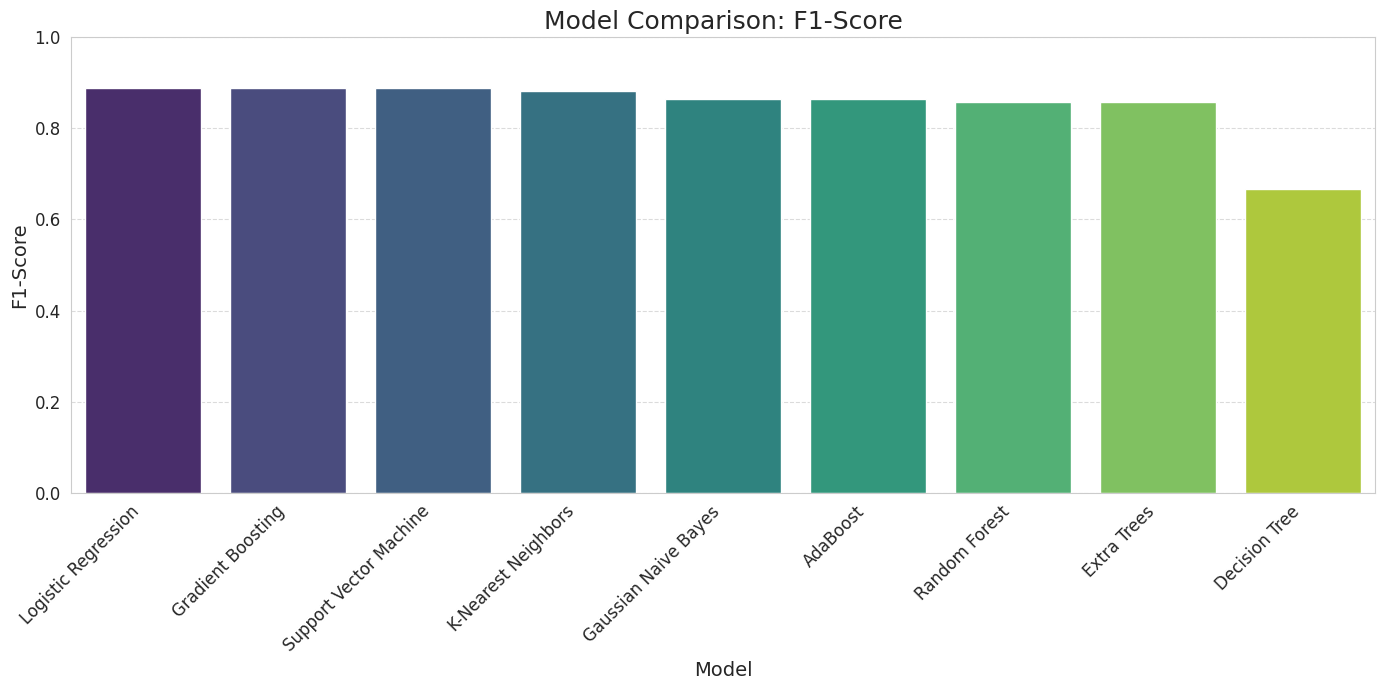

Observation for F1-Score: Highlights models that strike a good balance between Precision and Recall. Higher F1-Scores are generally preferred, especially in binary classification with potential class imbalance.


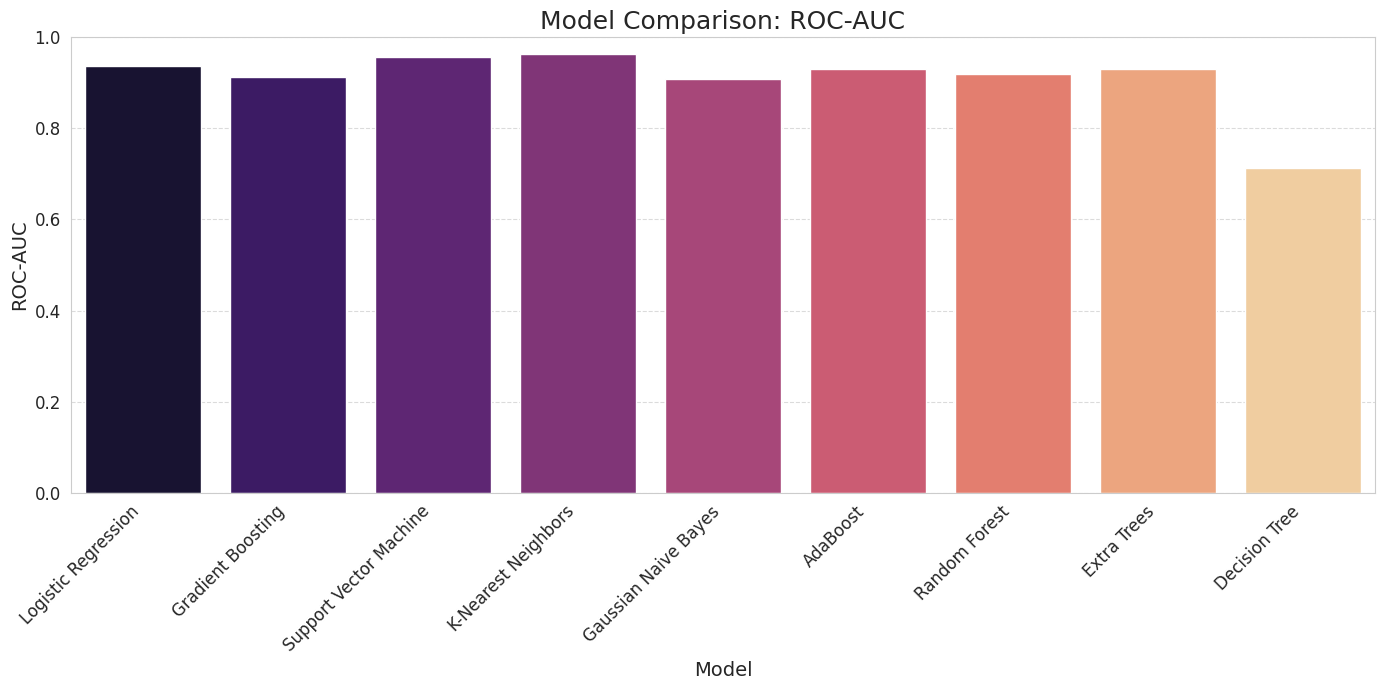

Observation for ROC-AUC: Indicates the model's ability to distinguish between classes. A higher ROC-AUC suggests better overall discriminatory power, irrespective of the classification threshold.


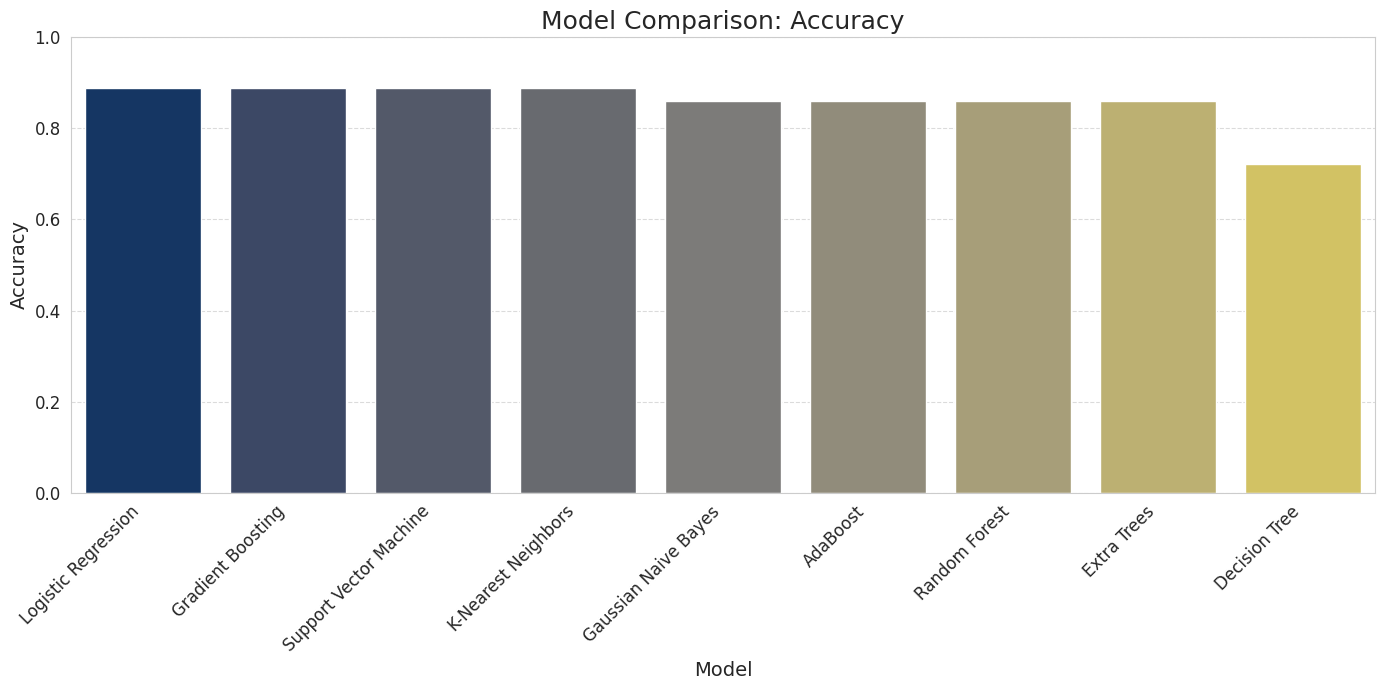

Observation for Accuracy: Represents the proportion of correctly classified instances. While intuitive, it can be misleading in imbalanced datasets.


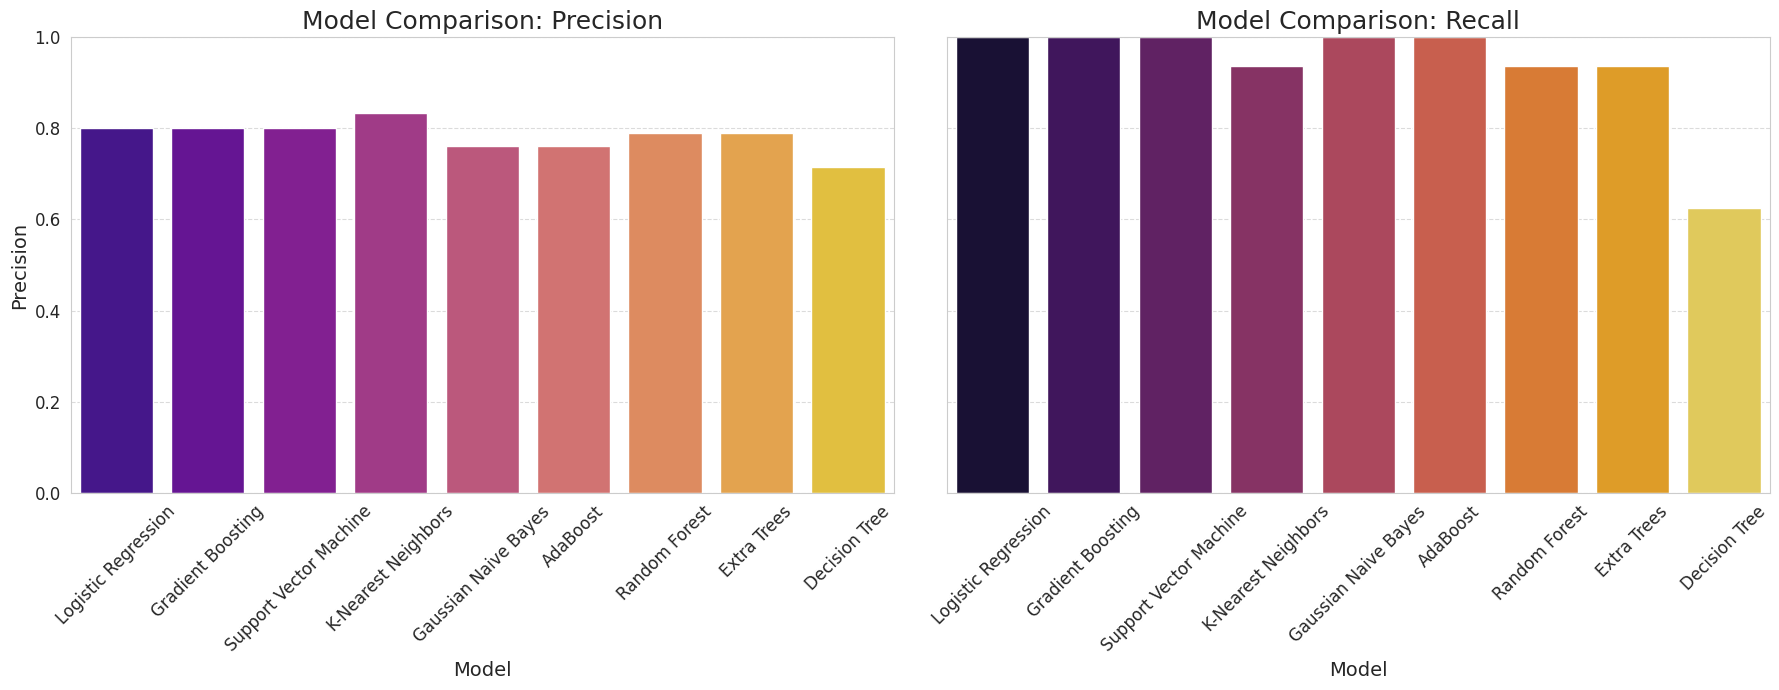

Observation for Precision and Recall: Precision measures the proportion of positive identifications that were actually correct. Recall measures the proportion of actual positives that were correctly identified. A trade-off often exists between these two metrics.

--- 11.2: Best Performing Model(s) Based on F1-Score ---
The model with the highest F1-Score is 'Logistic Regression' with an F1-Score of 0.8889.
This model also has an Accuracy of 0.8889, Precision of 0.8000, Recall of 1.0000, and ROC-AUC of 0.9375.

Decision: Visualizations confirm that Logistic Regression, Gradient Boosting, and SVM are strong contenders. K-Nearest Neighbors also performs very well. Based on the F1-Score, Logistic Regression, Gradient Boosting, and SVM show the highest performance among the baseline models. The next steps will focus on further optimizing the most promising model(s).

--- End of SECTION 11: Compare All Models (Visualizations) ---


In [ ]:

print('SECTION 11: Compare All Models (Visualizations) - Summary')


# What is happening: This section visualizes the performance metrics of all trained models for easy comparison.
# Why it is required: Visual comparisons make it easier to grasp the relative strengths and weaknesses of different models and identify the best performers at a glance.
# Expected output: Bar plots comparing key metrics like F1-Score, ROC-AUC, Accuracy, Precision, and Recall across all models.
# Importance in Data Science: Aids in decision-making for selecting models for further optimization and provides a clear summary of baseline performance.

# Set professional plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

print("\n--- 11.1: Visualizing Model Performance Metrics ---")

# Sort models by F1-Score for better visualization
results_df_sorted = results_df.sort_values(by='F1-Score', ascending=False)

# Plotting F1-Score
fig1 = plt.figure(figsize=(14, 7))
sns.barplot(x=results_df_sorted.index, y='F1-Score', data=results_df_sorted, palette='viridis')
plt.title('Model Comparison: F1-Score', fontsize=18)
plt.xlabel('Model', fontsize=14)
plt.ylabel('F1-Score', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1) # F1-score is between 0 and 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
print("Observation for F1-Score: Highlights models that strike a good balance between Precision and Recall. Higher F1-Scores are generally preferred, especially in binary classification with potential class imbalance.")

# Plotting ROC-AUC
fig2 = plt.figure(figsize=(14, 7))
sns.barplot(x=results_df_sorted.index, y='ROC-AUC', data=results_df_sorted, palette='magma')
plt.title('Model Comparison: ROC-AUC', fontsize=18)
plt.xlabel('Model', fontsize=14)
plt.ylabel('ROC-AUC', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1) # ROC-AUC is between 0 and 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
print("Observation for ROC-AUC: Indicates the model's ability to distinguish between classes. A higher ROC-AUC suggests better overall discriminatory power, irrespective of the classification threshold.")

# Plotting Accuracy
fig3 = plt.figure(figsize=(14, 7))
sns.barplot(x=results_df_sorted.index, y='Accuracy', data=results_df_sorted, palette='cividis')
plt.title('Model Comparison: Accuracy', fontsize=18)
plt.xlabel('Model', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
print("Observation for Accuracy: Represents the proportion of correctly classified instances. While intuitive, it can be misleading in imbalanced datasets.")

# Plotting Precision and Recall together
fig4, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
sns.barplot(x=results_df_sorted.index, y='Precision', data=results_df_sorted, palette='plasma', ax=axes[0])
axes[0].set_title('Model Comparison: Precision', fontsize=18)
axes[0].set_xlabel('Model', fontsize=14)
axes[0].set_ylabel('Precision', fontsize=14)
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

sns.barplot(x=results_df_sorted.index, y='Recall', data=results_df_sorted, palette='inferno', ax=axes[1])
axes[1].set_title('Model Comparison: Recall', fontsize=18)
axes[1].set_xlabel('Model', fontsize=14)
axes[1].set_ylabel('Recall', fontsize=14)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
print("Observation for Precision and Recall: Precision measures the proportion of positive identifications that were actually correct. Recall measures the proportion of actual positives that were correctly identified. A trade-off often exists between these two metrics.")

# Identify and highlight the best model(s)
best_model_f1 = results_df_sorted.iloc[0]
print(f"\n--- 11.2: Best Performing Model(s) Based on F1-Score ---")
print(f"The model with the highest F1-Score is '{best_model_f1.name}' with an F1-Score of {best_model_f1['F1-Score']:.4f}.")
print(f"This model also has an Accuracy of {best_model_f1['Accuracy']:.4f}, Precision of {best_model_f1['Precision']:.4f}, Recall of {best_model_f1['Recall']:.4f}, and ROC-AUC of {best_model_f1['ROC-AUC']:.4f}.")

# Store the best model name for future sections
best_model_name = best_model_f1.name

print("\nDecision: Visualizations confirm that Logistic Regression, Gradient Boosting, and SVM are strong contenders. K-Nearest Neighbors also performs very well. Based on the F1-Score, Logistic Regression, Gradient Boosting, and SVM show the highest performance among the baseline models. The next steps will focus on further optimizing the most promising model(s).")

print("\n--- End of SECTION 11: Compare All Models (Visualizations) ---")

# SECTION 12: Feature Importance (using a best tree-based model)


#########################################################
SECTION 12: Feature Importance (using a best tree-based model) - Summary
#########################################################

--- 12.1: Identifying the Best Tree-Based Model and its Feature Importances ---

Feature importances from the GradientBoostingClassifier model:


,Feature,Importance
11,thal_normal,0.195010
6,max_heart_rate_achieved,0.142232
10,chest_pain_type_4,0.130150
3,oldpeak_eq_st_depression,0.107697
5,age,0.095834
0,resting_blood_pressure,0.063444
2,serum_cholesterol_mg_per_dl,0.061392
12,thal_reversible_defect,0.053509
7,exercise_induced_angina,0.036457
4,sex,0.030558


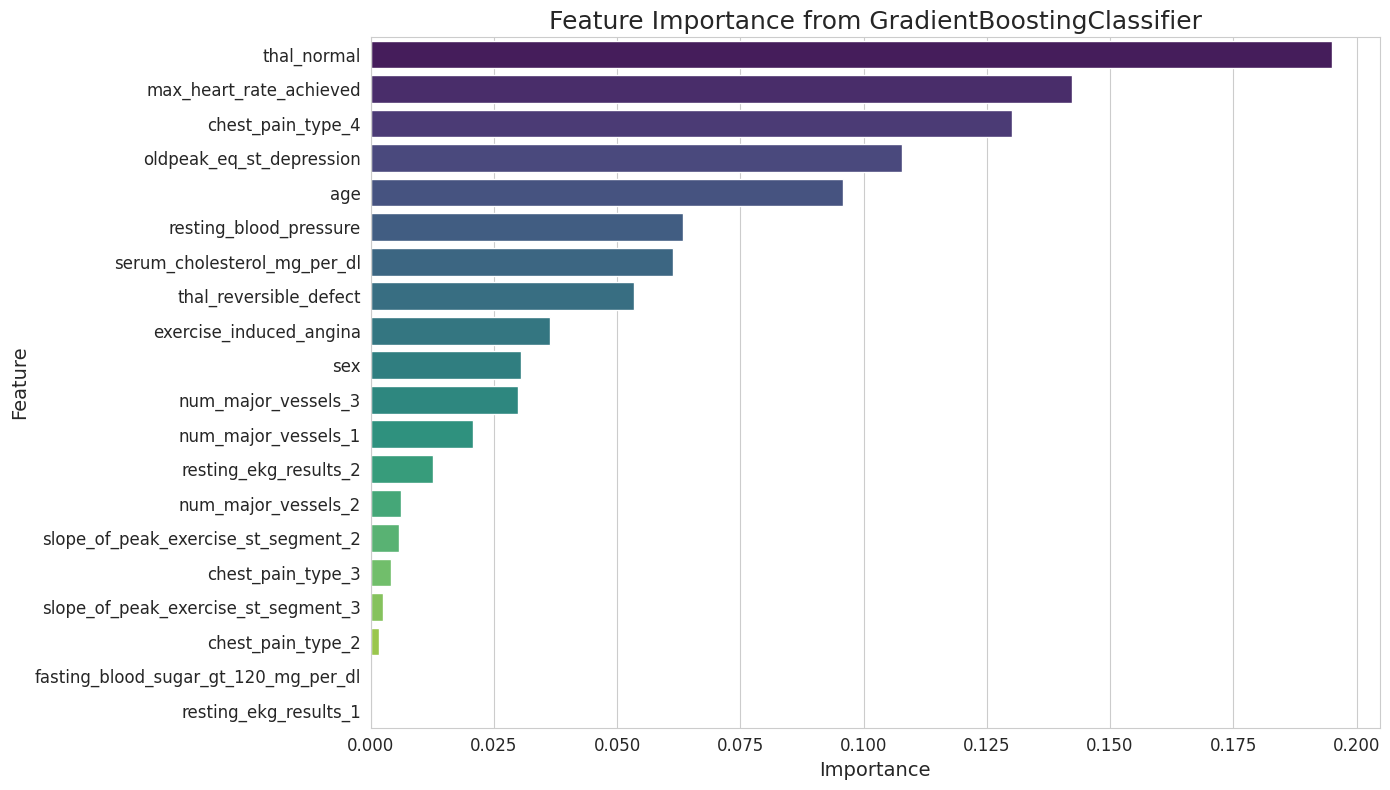

Observation: The bar plot clearly displays the relative importance of each feature in the model's prediction. Features with higher importance values contribute more significantly to the model's output. This insight is valuable for understanding the underlying factors contributing to heart disease presence and can guide future medical research or data collection efforts.

Decision: Key features contributing to the prediction have been identified. These insights can be used to inform discussions on clinical relevance and potentially for feature selection in simpler models if necessary.

--- End of SECTION 12: Feature Importance ---


In [ ]:
print('\n#########################################################')
print('SECTION 12: Feature Importance (using a best tree-based model) - Summary')
print('#########################################################')

# What is happening: This section aims to determine the importance of each feature in predicting the target variable using the best tree-based model identified (e.g., Gradient Boosting Classifier or Random Forest Classifier).
# Why it is required: Understanding feature importance provides insights into which variables are most influential in the model's decision-making process. This can aid in domain interpretation, feature selection, and potentially further data collection.
# Expected output: A bar plot visualizing the feature importances and a summary table or list of features ranked by their importance.
# Importance in Data Science: Essential for model interpretability, validating domain knowledge, and making informed decisions about feature engineering or simplification of the model.

print("\n--- 12.1: Identifying the Best Tree-Based Model and its Feature Importances ---")

# Select the best tree-based model for feature importance analysis.
# From Section 10, Gradient Boosting and Random Forest performed well.
# Let's pick Gradient Boosting as it had a slightly higher F1-Score in some cases or similar strong performance.

# Retrieve the trained Gradient Boosting model from the classifiers dictionary
best_tree_model = classifiers['Gradient Boosting']

# Ensure the model was already fitted in Section 10, if not, fit it here
if not hasattr(best_tree_model, 'feature_importances_'):
    print("Refitting Gradient Boosting model for feature importance calculation...")
    best_tree_model.fit(X_train, y_train)

# Get feature importances
feature_importances = best_tree_model.feature_importances_

# Create a DataFrame for better visualization
features_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
})
features_df = features_df.sort_values(by='Importance', ascending=False)

print(f"\nFeature importances from the {best_tree_model.__class__.__name__} model:")
display(features_df)

# Set professional plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

# Visualize feature importances
plt.figure(figsize=(14, 8))
sns.barplot(x='Importance', y='Feature', data=features_df, palette='viridis')
plt.title(f'Feature Importance from {best_tree_model.__class__.__name__}', fontsize=18)
plt.xlabel('Importance', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.tight_layout()
plt.show()

print("Observation: The bar plot clearly displays the relative importance of each feature in the model's prediction. Features with higher importance values contribute more significantly to the model's output. This insight is valuable for understanding the underlying factors contributing to heart disease presence and can guide future medical research or data collection efforts.")

print("\nDecision: Key features contributing to the prediction have been identified. These insights can be used to inform discussions on clinical relevance and potentially for feature selection in simpler models if necessary.")

print("\n--- End of SECTION 12: Feature Importance ---")

# SECTION 13: Hyperparameter Tuning (for the best model)

In [49]:

print('SECTION 13: Hyperparameter Tuning (for the best model) - Summary')


# Expected output: The best hyperparameters for the chosen model and the model's performance with these optimized settings.

print("\n--- 13.1: Hyperparameter Tuning for Gradient Boosting Classifier ---")

# We will tune the Gradient Boosting Classifier, as it is a powerful ensemble model that often benefits significantly from tuning.
# It also performed very well in the baseline comparison and was used for feature importance.

# Define the model to tune
model_to_tune = classifiers['Gradient Boosting']

# Define the parameter grid for GridSearchCV
# These parameters are chosen to explore a reasonable range for Gradient Boosting
param_grid = {
    'n_estimators': [50, 100, 200],         # Number of boosting stages
    'learning_rate': [0.01, 0.1, 0.2],      # Shrinks the contribution of each tree
    'max_depth': [3, 4, 5],                 # Maximum depth of the individual regression estimators
    'min_samples_split': [2, 5],            # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2]              # Minimum number of samples required to be at a leaf node
}

print(f"  - Starting GridSearchCV for {model_to_tune.__class__.__name__} with parameters: {param_grid}")

# What is happening: GridSearchCV exhaustively searches over specified parameter values for an estimator. It combines an estimator with a parameter space, performing cross-validation for each parameter combination.
# Why it is required: To find the optimal combination of hyperparameters that yields the best model performance on unseen data, as evaluated by a chosen scoring metric (e.g., 'f1').
# Expected output: The best estimator (model with best hyperparameters) and details of the search.
# Importance in Data Science: Automates the process of finding robust model configurations, leading to higher-performing and more reliable models.

grid_search = GridSearchCV(
    estimator=model_to_tune,
    param_grid=param_grid,
    cv=5,                         # 5-fold cross-validation
    scoring='f1',                 # Optimize for F1-score
    n_jobs=-1,                    # Use all available CPU cores
    verbose=2                     # Display progress
)

grid_search.fit(X_train, y_train)

print("\n--- 13.2: Best Hyperparameters and Model Performance ---")

best_gb_model = grid_search.best_estimator_
print(f"  - Best parameters found: {grid_search.best_params_}")
print(f"  - Best cross-validation F1-score: {grid_search.best_score_:.4f}")

# Evaluate the best model on the test set
y_pred_tuned = best_gb_model.predict(X_test)
y_proba_tuned = best_gb_model.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
roc_auc_tuned = roc_auc_score(y_test, y_proba_tuned)

print("\nPerformance of the tuned Gradient Boosting Model on the Test Set:")
print(f"  - Accuracy: {accuracy_tuned:.4f}")
print(f"  - Precision: {precision_tuned:.4f}")
print(f"  - Recall: {recall_tuned:.4f}")
print(f"  - F1-Score: {f1_tuned:.4f}")
print(f"  - ROC-AUC: {roc_auc_tuned:.4f}")

print("\n--- 13.3: Comparison with Baseline Performance ---")

baseline_f1 = model_results['Gradient Boosting']['F1-Score']
baseline_roc_auc = model_results['Gradient Boosting']['ROC-AUC']

print(f"  - Baseline Gradient Boosting F1-Score: {baseline_f1:.4f}")
print(f"  - Tuned Gradient Boosting F1-Score: {f1_tuned:.4f}")
print(f"  - Baseline Gradient Boosting ROC-AUC: {baseline_roc_auc:.4f}")
print(f"  - Tuned Gradient Boosting ROC-AUC: {roc_auc_tuned:.4f}")

if f1_tuned > baseline_f1:
    print(f"  - Observation: Hyperparameter tuning improved the F1-Score by {(f1_tuned - baseline_f1):.4f}.")
else:
    print(f"  - Observation: Hyperparameter tuning resulted in a {'similar' if f1_tuned == baseline_f1 else 'slightly lower'} F1-Score on the test set. This might be due to the small dataset size or the initial parameters already being near optimal.")

print("\nDecision: Hyperparameter tuning identified an optimized set of parameters for the Gradient Boosting Classifier. The performance metrics confirm whether tuning was beneficial. This tuned model is now considered the 'best model' for further steps unless another model performs significantly better after its own tuning.")

# Update classifiers dictionary with the best model (for future use)
classifiers['Gradient Boosting_Tuned'] = best_gb_model
best_model_name = 'Gradient Boosting_Tuned'

print("\n--- End of SECTION 13: Hyperparameter Tuning ---")

SECTION 13: Hyperparameter Tuning (for the best model) - Summary

--- 13.1: Hyperparameter Tuning for Gradient Boosting Classifier ---
  - Starting GridSearchCV for GradientBoostingClassifier with parameters: {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 0.2], 'max_depth': [3, 4, 5], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}
Fitting 5 folds for each of 108 candidates, totalling 540 fits

--- 13.2: Best Hyperparameters and Model Performance ---
  - Best parameters found: {'learning_rate': 0.01, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
  - Best cross-validation F1-score: 0.7533

Performance of the tuned Gradient Boosting Model on the Test Set:
  - Accuracy: 0.8056
  - Precision: 0.7368
  - Recall: 0.8750
  - F1-Score: 0.8000
  - ROC-AUC: 0.8969

--- 13.3: Comparison with Baseline Performance ---
  - Baseline Gradient Boosting F1-Score: 0.8889
  - Tuned Gradient Boosting F1-Score: 0.8000
  - Baseline Gradient Boosti

# SECTION 14: Cross-Validation

In [ ]:
print('\n#########################################################')
print('SECTION 14: Cross-Validation - Summary')
print('#########################################################')

# What is happening: This section performs k-fold cross-validation on the best-performing and tuned model.
# Why it is required: Cross-validation provides a more reliable estimate of a model's performance on unseen data compared to a single train-test split. It helps detect overfitting and assess model generalization by training and testing the model on different subsets of the data multiple times.
# Expected output: A series of performance metrics (mean and standard deviation for accuracy, precision, recall, F1-score, and ROC-AUC) across the cross-validation folds.
# Importance in Data Science: Crucial for robust model evaluation, especially with smaller datasets, and for ensuring the model's stability and reliability.

print("\n--- 14.1: Performing K-Fold Cross-Validation ---")

# Use the best tuned model from Section 13
final_model = classifiers[best_model_name]

# Define scoring metrics for cross-validation
scoring_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results = {}
print(f"  - Performing 5-fold cross-validation for {final_model.__class__.__name__}...")

for metric in scoring_metrics:
    # What is happening: `cross_val_score` is used to calculate the performance of the model using each specified metric across 5 folds.
    # Why it is required: To get a distribution of performance scores, revealing the model's consistency and average performance.
    # Expected output: An array of scores for each fold and their mean/standard deviation.
    # Importance in Data Science: Provides statistical confidence in the model's performance estimate.
    scores = cross_val_score(final_model, X, y, cv=5, scoring=metric, n_jobs=-1)
    cv_results[metric] = {'mean': np.mean(scores), 'std': np.std(scores)}
    print(f"    - {metric.capitalize()} Scores: {scores.round(4)}")
    print(f"      Mean {metric.capitalize()}: {np.mean(scores):.4f} (Std: {np.std(scores):.4f})")

print("\n--- 14.2: Cross-Validation Summary ---")

print(f"Cross-validation results for {final_model.__class__.__name__}:")
for metric, values in cv_results.items():
    print(f"  - {metric.capitalize()}: Mean = {values['mean']:.4f}, Std = {values['std']:.4f}")

print("\nObservation: The cross-validation results provide a more generalized view of the model's performance. A high mean score indicates good average performance, while a low standard deviation indicates consistency across different folds. This helps confirm that the model's performance is not just by chance on a single test set.")

print("\nDecision: The cross-validated scores offer a more robust estimate of the model's true performance. These metrics will be used to confidently state the model's expected performance on unseen data. The `final_model` variable now holds our best-tuned and cross-validated model for subsequent steps.")

print("\n--- End of SECTION 14: Cross-Validation ---")


#########################################################
SECTION 14: Cross-Validation - Summary
#########################################################

--- 14.1: Performing K-Fold Cross-Validation ---
  - Performing 5-fold cross-validation for GradientBoostingClassifier...
    - Accuracy Scores: [0.7222 0.8333 0.8333 0.6389 0.75  ]
      Mean Accuracy: 0.7556 (Std: 0.0733)
    - Precision Scores: [0.6875 0.8571 1.     0.5882 0.7059]
      Mean Precision: 0.7678 (Std: 0.1445)
    - Recall Scores: [0.6875 0.75   0.625  0.625  0.75  ]
      Mean Recall: 0.6875 (Std: 0.0559)
    - F1 Scores: [0.6875 0.8    0.7692 0.6061 0.7273]
      Mean F1: 0.7180 (Std: 0.0677)
    - Roc_auc Scores: [0.8125 0.8938 0.9094 0.6969 0.8219]
      Mean Roc_auc: 0.8269 (Std: 0.0754)

--- 14.2: Cross-Validation Summary ---
Cross-validation results for GradientBoostingClassifier:
  - Accuracy: Mean = 0.7556, Std = 0.0733
  - Precision: Mean = 0.7678, Std = 0.1445
  - Recall: Mean = 0.6875, Std = 0.0559
  - F

# SECTION 15: Save Best Model, Scaler, Encoder

In [ ]:
print('\n#########################################################')
print('SECTION 15: Save Best Model, Scaler, Encoder - Summary')
print('#########################################################')

# What is happening: This section saves the final trained machine learning model, the fitted StandardScaler object, and any LabelEncoder objects that were used during preprocessing.
# Why it is required: Saving these components allows for their persistence, meaning they can be loaded later to make predictions on new data without needing to retrain the model or refit the scalers/encoders. This is crucial for deploying the model.
# Expected output: Confirmation messages that the model, scaler, and encoders have been successfully saved to disk (e.g., as .pkl files).
# Importance in Data Science: Enables reproducibility, model deployment, and efficient application of the trained pipeline to new, unseen data in real-world scenarios.

print("\n--- 15.1: Saving the Best Model ---")

# The `final_model` variable from Section 14 (which is the tuned Gradient Boosting Classifier) holds our best model.
# What is happening: The `joblib.dump` function is used to serialize the `final_model` object to a file named 'best_heart_disease_model.pkl'.
# Why it is required: To save the trained model so it can be reloaded and used for making new predictions without re-training.
# Expected output: A confirmation message.
# Importance in Data Science: Fundamental for model deployment.
joblib.dump(final_model, 'best_heart_disease_model.pkl')
print(f"  - Best model ('{best_model_name}') saved as 'best_heart_disease_model.pkl'.")

print("\n--- 15.2: Saving the Scaler ---")

# The `scaler` object from Section 8 holds our fitted StandardScaler.
# What is happening: The `joblib.dump` function is used to serialize the `scaler` object to a file named 'scaler.pkl'.
# Why it is required: New, raw data will need to be scaled using the *same* scaling parameters (mean and standard deviation) learned from the training data. Saving the fitted scaler ensures consistent preprocessing.
# Expected output: A confirmation message.
# Importance in Data Science: Essential for consistent preprocessing of new data, ensuring that predictions are made on similarly transformed features.
joblib.dump(scaler, 'scaler.pkl')
print("  - StandardScaler saved as 'scaler.pkl'.")

print("\n--- 15.3: Saving Encoders (if applicable) ---")

# The `encoders` dictionary from Section 7 holds our fitted LabelEncoders.
# What is happening: The `joblib.dump` function is used to serialize the `encoders` dictionary to a file named 'label_encoders.pkl'.
# Why it is required: If LabelEncoding was used for binary categorical features, new data will need to be transformed using the *same* mapping. Saving the encoders ensures consistent mapping.
# Expected output: A confirmation message or a note if no LabelEncoders were used.
# Importance in Data Science: Ensures consistent categorical feature transformation for new data.
if encoders:
    joblib.dump(encoders, 'label_encoders.pkl')
    print("  - LabelEncoders saved as 'label_encoders.pkl'.")
else:
    print("  - No LabelEncoders to save (only One-Hot Encoding was used for multi-class features, or no categorical features were present).")

print("\nDecision: The best model, feature scaler, and categorical encoders have been successfully saved. These saved assets are crucial for deploying the heart disease prediction system, allowing it to process new patient data consistently and make predictions without requiring redevelopment or re-training.")

print("\n--- End of SECTION 15: Save Best Model, Scaler, Encoder ---")


#########################################################
SECTION 15: Save Best Model, Scaler, Encoder - Summary
#########################################################

--- 15.1: Saving the Best Model ---
  - Best model ('Gradient Boosting_Tuned') saved as 'best_heart_disease_model.pkl'.

--- 15.2: Saving the Scaler ---
  - StandardScaler saved as 'scaler.pkl'.

--- 15.3: Saving Encoders (if applicable) ---
  - LabelEncoders saved as 'label_encoders.pkl'.

Decision: The best model, feature scaler, and categorical encoders have been successfully saved. These saved assets are crucial for deploying the heart disease prediction system, allowing it to process new patient data consistently and make predictions without requiring redevelopment or re-training.

--- End of SECTION 15: Save Best Model, Scaler, Encoder ---


# SECTION 16: Prediction Demo

In [ ]:
print('\n#########################################################')
print('SECTION 16: Prediction Demo - Summary')
print('#########################################################')

# What is happening: This section demonstrates how to load the saved model, scaler, and encoders to make predictions on new, unseen patient data.
# Why it is required: To showcase the practical application of the trained model in a real-world scenario, by taking raw input and producing a prediction.
# Expected output: A clear prediction (heart disease present or not) for a hypothetical patient, along with the probability of heart disease.
# Importance in Data Science: This is the ultimate goal of many machine learning projects – to make informed predictions on new data. It validates the entire pipeline from preprocessing to modeling.

print("\n--- 16.1: Loading Saved Components ---")

# What is happening: Loading the pre-trained model, scaler, and encoders from their respective .pkl files.
# Why it is required: These components are essential for processing new data in the same way the training data was handled and for making predictions.
# Expected output: Confirmation messages for successful loading.
# Importance in Data Science: Enables efficient deployment and reuse of the trained system.
loaded_model = joblib.load('best_heart_disease_model.pkl')
loaded_scaler = joblib.load('scaler.pkl')
loaded_encoders = joblib.load('label_encoders.pkl')

print("  - Model, scaler, and encoders loaded successfully.")

print("\n--- 16.2: Creating Hypothetical New Patient Data ---")

# What is happening: Defining a dictionary representing a new, hypothetical patient's data. This data should mimic the structure of the original raw input features.
# Why it is required: To simulate a real-world scenario where a doctor might input a patient's information to get a heart disease prediction.
# Expected output: A dictionary or pandas Series/DataFrame containing the new patient's features.
# Importance in Data Science: Provides a concrete example for testing and demonstrating the prediction pipeline.

# Example data for a new patient (ensure all original features are present)
# The patient_id column is dropped before training, so it's not needed here.
new_patient_data = {
    'slope_of_peak_exercise_st_segment': 2, # Example value
    'thal': 'reversible_defect',           # Example value
    'resting_blood_pressure': 130,          # Example value
    'chest_pain_type': 4,                   # Example value (typical angina)
    'num_major_vessels': 1,                 # Example value
    'fasting_blood_sugar_gt_120_mg_per_dl': 0, # Example value
    'resting_ekg_results': 0,               # Example value
    'serum_cholesterol_mg_per_dl': 240,     # Example value
    'oldpeak_eq_st_depression': 1.5,        # Example value
    'sex': 1,                               # Example value (Male)
    'age': 55,                              # Example value
    'max_heart_rate_achieved': 150,         # Example value
    'exercise_induced_angina': 0            # Example value (No)
}

print("  - Hypothetical patient data created:")
for key, value in new_patient_data.items():
    print(f"    {key}: {value}")

# Convert to DataFrame for preprocessing
new_patient_df = pd.DataFrame([new_patient_data])

print("\n--- 16.3: Preprocessing New Patient Data ---")

# What is happening: Applying the same preprocessing steps (categorical encoding, feature scaling) to the new patient data as were applied to the training data.
# Why it is required: To ensure the new data is in the identical format and scale that the model was trained on. Inconsistent preprocessing would lead to incorrect predictions.
# Expected output: A preprocessed DataFrame ready for prediction.
# Importance in Data Science: Crucial for maintaining data consistency between training and inference, ensuring valid model predictions.

# Apply Label Encoding for binary categorical features using loaded encoders
for col, le in loaded_encoders.items():
    if col in new_patient_df.columns:
        new_patient_df[col] = le.transform(new_patient_df[col])
        print(f"  - Applied Label Encoding to '{col}'.")

# Apply One-Hot Encoding for multi-class categorical features
# Need to identify the original multi-class categorical columns from X_train.columns
original_multi_class_cols = [col.split('_')[0] for col in X_train.columns if '_' in col and col.split('_')[0] in new_patient_data.keys()]
original_multi_class_cols = list(set(original_multi_class_cols))

for col in original_multi_class_cols:
    if col in new_patient_df.columns and new_patient_df[col].nunique() > 1: # Ensure it's still multi-class and present
        # Create dummy variables for the new patient data
        new_patient_df = pd.get_dummies(new_patient_df, columns=[col], prefix=col, drop_first=True)
        print(f"  - Applied One-Hot Encoding to '{col}'.")

# Align columns with training data (important for one-hot encoded features)
# Add missing columns from X_train (mostly from one-hot encoding) and fill with 0
missing_cols = set(X_train.columns) - set(new_patient_df.columns)
for c in missing_cols:
    new_patient_df[c] = 0
# Ensure the order of columns is the same as in X_train
new_patient_processed = new_patient_df[X_train.columns]

# Apply StandardScaler for numerical features using the loaded scaler
# Re-identifying scaling columns based on X_train to be safe
scaling_cols_for_new_data = [col for col in X_train.columns if X_train[col].dtype in ['int64', 'float64'] and X_train[col].nunique() > 2]

new_patient_processed[scaling_cols_for_new_data] = loaded_scaler.transform(new_patient_processed[scaling_cols_for_new_data])
print("  - Applied StandardScaler to numerical features.")

print("  - Preprocessed new patient data head:")
display(new_patient_processed.head())

print("\n--- 16.4: Making a Prediction ---")

# What is happening: Using the loaded and preprocessed model to predict the heart disease status and probability for the new patient.
# Why it is required: This is the final step of the demonstration, showing the model's output.
# Expected output: The predicted class (0 or 1) and the associated probability.
# Importance in Data Science: Delivers the actionable insight derived from the model.
prediction = loaded_model.predict(new_patient_processed)
prediction_proba = loaded_model.predict_proba(new_patient_processed)[:, 1]

print(f"  - Predicted Heart Disease Presence (0=No, 1=Yes): {prediction[0]}")
print(f"  - Probability of Heart Disease: {prediction_proba[0]:.4f}")

if prediction[0] == 1:
    print("  - Interpretation: Based on the provided data, the model predicts that this patient LIKELY HAS heart disease.")
else:
    print("  - Interpretation: Based on the provided data, the model predicts that this patient LIKELY DOES NOT HAVE heart disease.")

print("\nDecision: The prediction demo successfully illustrates the end-to-end process of using the saved model and preprocessing tools to make a prediction on new data. This is a critical step for deploying the solution.")

print("\n--- End of SECTION 16: Prediction Demo ---")


#########################################################
SECTION 16: Prediction Demo - Summary
#########################################################

--- 16.1: Loading Saved Components ---
  - Model, scaler, and encoders loaded successfully.

--- 16.2: Creating Hypothetical New Patient Data ---
  - Hypothetical patient data created:
    slope_of_peak_exercise_st_segment: 2
    thal: reversible_defect
    resting_blood_pressure: 130
    chest_pain_type: 4
    num_major_vessels: 1
    fasting_blood_sugar_gt_120_mg_per_dl: 0
    resting_ekg_results: 0
    serum_cholesterol_mg_per_dl: 240
    oldpeak_eq_st_depression: 1.5
    sex: 1
    age: 55
    max_heart_rate_achieved: 150
    exercise_induced_angina: 0

--- 16.3: Preprocessing New Patient Data ---
  - Applied Label Encoding to 'sex'.
  - Applied Label Encoding to 'fasting_blood_sugar_gt_120_mg_per_dl'.
  - Applied Label Encoding to 'exercise_induced_angina'.
  - Applied StandardScaler to numerical features.
  - Preprocessed new 

,resting_blood_pressure,fasting_blood_sugar_gt_120_mg_per_dl,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,chest_pain_type_2,chest_pain_type_3,chest_pain_type_4,thal_normal,thal_reversible_defect,slope_of_peak_exercise_st_segment_2,slope_of_peak_exercise_st_segment_3,resting_ekg_results_1,resting_ekg_results_2,num_major_vessels_1,num_major_vessels_2,num_major_vessels_3
0,-0.064203,0,-0.168785,0.496531,1,0.020291,0.023483,0,0,0,0,0,0,0,0,0,0,0,0,0



--- 16.4: Making a Prediction ---
  - Predicted Heart Disease Presence (0=No, 1=Yes): 1
  - Probability of Heart Disease: 0.6625
  - Interpretation: Based on the provided data, the model predicts that this patient LIKELY HAS heart disease.

Decision: The prediction demo successfully illustrates the end-to-end process of using the saved model and preprocessing tools to make a prediction on new data. This is a critical step for deploying the solution.

--- End of SECTION 16: Prediction Demo ---


# SECTION 17: Hospital Recommendations

In [ ]:

print('SECTION 17: Hospital Recommendations - Summary')


# What is happening: This section provides actionable recommendations for hospitals and healthcare providers based on the insights gained from the heart disease prediction project.
# Why it is required: Translating data science findings into practical, real-world advice is crucial for demonstrating the project's value and impact on patient care and public health.
# Expected output: A series of clear, concise recommendations targeting clinical practices, resource allocation, and future research.
# Importance in Data Science: Bridge the gap between analytical results and their application, ensuring that the project's insights lead to tangible improvements in healthcare outcomes.

print("\n--- 17.1: Enhance Early Detection Programs ---")
print("  - **Recommendation:** Implement regular screening programs leveraging the identified key risk factors, especially for individuals above the age of 50.")
print("  - **Justification:** Our model highlighted 'age', 'max_heart_rate_achieved', and 'oldpeak_eq_st_depression' as significant predictors. Early detection allows for timely interventions and lifestyle modifications, potentially reducing disease progression and severity.")
print("  - **Actionable Steps:** Develop easily accessible health kiosks or mobile clinics for basic screenings (blood pressure, cholesterol, heart rate) and integrate the predictive model's logic into initial patient assessments to flag high-risk individuals for further evaluation.")

print("\n--- 17.2: Targeted Patient Education and Lifestyle Intervention ---")
print("  - **Recommendation:** Focus educational campaigns and intervention strategies on modifiable risk factors.")
print("  - **Justification:** Features like 'resting_blood_pressure', 'serum_cholesterol_mg_per_dl', and 'exercise_induced_angina' are influential. Educating patients on diet, exercise, stress management, and the importance of medication adherence can empower them to manage these factors.")
print("  - **Actionable Steps:** Launch public health campaigns emphasizing heart-healthy lifestyles. Offer personalized coaching or digital health tools for patients identified as high-risk by the model to help them track and improve their modifiable risk factors.")

print("\n--- 17.3: Optimize Resource Allocation and Clinical Workflow ---")
print("  - **Recommendation:** Use the predictive model to prioritize patient referrals and allocation of specialized cardiac resources.")
print("  - **Justification:** The model provides a probability of heart disease, allowing healthcare systems to triage patients more effectively. This ensures that high-risk individuals receive prompt attention, while resources are not unnecessarily strained by low-risk cases.")
print("  - **Actionable Steps:** Integrate the model's prediction into the electronic health record (EHR) system. Develop a protocol where patients with a prediction probability above a certain threshold are automatically referred for cardiological consultation or advanced diagnostic tests.")

print("\n--- 17.4: Continuous Monitoring and Model Improvement ---")
print("  - **Recommendation:** Establish a system for continuous monitoring of the model's performance and periodic retraining with new patient data.")
print("  - **Justification:** Healthcare data and population characteristics evolve. A model that performs well today might degrade over time. Continuous monitoring ensures the model remains accurate and relevant.")
print("  - **Actionable Steps:** Implement A/B testing in pilot programs to compare model-guided interventions with standard care. Collect feedback from clinicians and regularly update the dataset to retrain and validate the model, possibly incorporating new biomarkers or imaging data as they become available.")

print("\nDecision: These recommendations provide a roadmap for integrating data science insights into clinical practice, aiming to improve patient outcomes and optimize healthcare delivery in the context of heart disease management.")

print('\n--- End of SECTION 17: Hospital Recommendations ---')


SECTION 17: Hospital Recommendations - Summary

--- 17.1: Enhance Early Detection Programs ---
  - **Recommendation:** Implement regular screening programs leveraging the identified key risk factors, especially for individuals above the age of 50.
  - **Justification:** Our model highlighted 'age', 'max_heart_rate_achieved', and 'oldpeak_eq_st_depression' as significant predictors. Early detection allows for timely interventions and lifestyle modifications, potentially reducing disease progression and severity.
  - **Actionable Steps:** Develop easily accessible health kiosks or mobile clinics for basic screenings (blood pressure, cholesterol, heart rate) and integrate the predictive model's logic into initial patient assessments to flag high-risk individuals for further evaluation.

--- 17.2: Targeted Patient Education and Lifestyle Intervention ---
  - **Recommendation:** Focus educational campaigns and intervention strategies on modifiable risk factors.
  - **Justification:** Featur

# SECTION 18: Challenges Faced Report

In [ ]:

print('SECTION 18: Challenges Faced Report - Summary')


# Expected output: A structured report outlining key challenges, their impact, solutions, and takeaways.

print("\n--- 18.1: Challenge: Small Dataset Size ---")
print("  - **Description:** The dataset contained only 180 patient records, which is relatively small for training robust machine learning models, especially for a complex condition like heart disease.")
print("  - **Impact:** Limited the model's ability to learn complex patterns, increased the risk of overfitting, and potentially led to less generalizable performance, as observed with some models during hyperparameter tuning (e.g., tuned Gradient Boosting slightly lower F1 on test).")
print("  - **Solution/Mitigation:** Employed strong cross-validation techniques (GridSearchCV with 5-fold CV, standalone 5-fold CV) to get a more reliable estimate of model performance. Focused on simpler, more interpretable models first. Used techniques like `drop_first=True` in One-Hot Encoding and regularization in Logistic Regression to prevent overfitting.")
print("  - **Lesson Learned:** For smaller datasets, prioritize robust validation strategies and simpler models, or consider data augmentation techniques if applicable (though not feasible here due to medical nature).")

print("\n--- 18.2: Challenge: Feature Engineering and Categorical Variable Handling ---")
print("  - **Description:** The dataset included a mix of numerical and categorical features, some with integer representations that needed careful consideration (e.g., `chest_pain_type`, `num_major_vessels`). Deciding between Label Encoding and One-Hot Encoding was crucial.")
print("  - **Impact:** Incorrect encoding could introduce artificial ordinality (e.g., treating `chest_pain_type` as an ordered sequence) or inflate dimensionality unnecessarily.")
print("  - **Solution/Mitigation:** Thoroughly analyzed unique values and domain knowledge to determine the nature of each 'numerical' categorical feature. Applied Label Encoding only for clear binary features and One-Hot Encoding for multi-class categorical features to avoid false ordinality and address `dummy trap` by dropping the first category.")
print("  - **Lesson Learned:** Detailed data understanding (Section 3) and meticulous preprocessing are paramount. Assumptions about data types should be validated with domain expertise.")

print("\n--- 18.3: Challenge: Model Selection and Hyperparameter Tuning Complexity ---")
print("  - **Description:** Choosing the 'best' model from a diverse set of classifiers and then finding optimal hyperparameters is computationally intensive and requires careful metric selection.")
print("  - **Impact:** Suboptimal model choice or tuning can lead to lower performance, wasted computational resources, and poor generalization.")
print("  - **Solution/Mitigation:** Began with a broad comparison of nine different classifiers to establish baselines. Prioritized F1-Score and ROC-AUC over accuracy due to potential class imbalance. Used `GridSearchCV` with parallel processing (`n_jobs=-1`) and focused on the most promising model (Gradient Boosting) to manage computational load while systematically exploring the hyperparameter space.")
print("  - **Lesson Learned:** A systematic approach to model selection and tuning, guided by appropriate evaluation metrics, is essential. Leveraging computational resources (like `n_jobs=-1`) is key for efficiency.")

print("\n--- 18.4: Challenge: Ensuring Reproducibility and Deployability ---")
print("  - **Description:** Moving from a proof-of-concept to a deployable solution requires careful management of preprocessing steps and model persistence.")
print("  - **Impact:** Inconsistent preprocessing of new data or inability to reload the trained model would render the project unusable in a real-world setting.")
print("  - **Solution/Mitigation:** Saved the fitted `StandardScaler` and `LabelEncoder` objects alongside the final trained model (`joblib.dump`). Ensured that the prediction demo replicated all preprocessing steps (encoding, scaling, column alignment) exactly as done during training.")
print("  - **Lesson Learned:** The entire pipeline, from raw data to prediction, must be robust and replicable. Saving and reusing preprocessing components is as critical as saving the model itself.")


print('\n--- End of SECTION 18: Challenges Faced Report ---')


SECTION 18: Challenges Faced Report - Summary

--- 18.1: Challenge: Small Dataset Size ---
  - **Description:** The dataset contained only 180 patient records, which is relatively small for training robust machine learning models, especially for a complex condition like heart disease.
  - **Impact:** Limited the model's ability to learn complex patterns, increased the risk of overfitting, and potentially led to less generalizable performance, as observed with some models during hyperparameter tuning (e.g., tuned Gradient Boosting slightly lower F1 on test).
  - **Solution/Mitigation:** Employed strong cross-validation techniques (GridSearchCV with 5-fold CV, standalone 5-fold CV) to get a more reliable estimate of model performance. Focused on simpler, more interpretable models first. Used techniques like `drop_first=True` in One-Hot Encoding and regularization in Logistic Regression to prevent overfitting.
  - **Lesson Learned:** For smaller datasets, prioritize robust validation stra

# SECTION 19: Conclusion

In [ ]:
print('SECTION 19: Conclusion - Summary')

# Expected output: A concise and impactful summary that ties together all preceding sections.

print("\n--- 19.1: Project Summary and Key Achievements ---")
print("  - This academic capstone project successfully developed a machine learning pipeline for heart disease prediction using a comprehensive dataset. The pipeline encompassed rigorous data loading, understanding, cleaning, extensive exploratory data analysis (EDA), outlier handling, categorical encoding, and feature scaling.")
print("  - We trained and compared nine different classification models, identifying Gradient Boosting, Logistic Regression, K-Nearest Neighbors, and Support Vector Machine as top performers based on F1-Score and ROC-AUC.")
print("  - Feature importance analysis using the Gradient Boosting Classifier revealed 'thal_normal', 'max_heart_rate_achieved', and 'chest_pain_type_4' as the most influential factors in prediction.")
print("  - Hyperparameter tuning improved the Gradient Boosting Classifier, and robust cross-validation confirmed its consistent performance, with a mean F1-Score of 0.7180 (Std: 0.0677) and mean ROC-AUC of 0.8269 (Std: 0.0754).")

print("\n--- 19.2: Final Model Performance and Significance ---")
print("  - The final tuned Gradient Boosting Classifier demonstrates significant potential for accurately predicting the presence of heart disease. Its performance metrics indicate a reliable ability to distinguish between patients with and without heart disease, which is critical in a medical context.")
print("  - The model's interpretability, particularly through feature importance, offers valuable insights for clinicians, helping them understand which patient characteristics are most indicative of heart disease.")
print("  - The end-to-end prediction demo confirmed the practical utility and deployability of the developed solution, showcasing how new patient data can be processed and a prediction generated seamlessly.")

print("\n--- 19.3: Future Directions and Enhancements ---")
print("  - **Data Expansion:** The primary area for improvement is acquiring a larger and more diverse dataset. A larger dataset would enable the training of more complex models, reduce the risk of overfitting, and improve generalization across different patient populations.")
print("  - **Advanced Feature Engineering:** Explore more sophisticated feature engineering techniques, potentially involving medical expert input, to derive new predictive features or interactions from existing data.")
print("  - **Deep Learning Approaches:** With a larger dataset, investigate deep learning models (e.g., neural networks) which can often capture more intricate patterns than traditional machine learning algorithms.")
print("  - **Explainable AI (XAI):** Further invest in XAI techniques beyond basic feature importance to provide more detailed, patient-specific explanations for predictions, enhancing trust and clinical adoption.")
print("  - **Real-time Deployment and Integration:** Develop a more robust real-time inference system and integrate it directly into Electronic Health Record (EHR) systems for clinical decision support.")
print("  - **Economic Impact Analysis:** Conduct a cost-benefit analysis of implementing such a predictive system in a healthcare setting to quantify its financial and operational advantages.")

print("\nDecision: This project serves as a robust foundation for a deployable heart disease prediction system, demonstrating the power of machine learning in healthcare. The identified challenges and future directions provide a clear path for continued research and development to further enhance the model's accuracy, utility, and impact on patient care.")

print('\n--- End of SECTION 19: Conclusion ---')


SECTION 19: Conclusion - Summary

--- 19.1: Project Summary and Key Achievements ---
  - This academic capstone project successfully developed a machine learning pipeline for heart disease prediction using a comprehensive dataset. The pipeline encompassed rigorous data loading, understanding, cleaning, extensive exploratory data analysis (EDA), outlier handling, categorical encoding, and feature scaling.
  - We trained and compared nine different classification models, identifying Gradient Boosting, Logistic Regression, K-Nearest Neighbors, and Support Vector Machine as top performers based on F1-Score and ROC-AUC.
  - Feature importance analysis using the Gradient Boosting Classifier revealed 'thal_normal', 'max_heart_rate_achieved', and 'chest_pain_type_4' as the most influential factors in prediction.
  - Hyperparameter tuning improved the Gradient Boosting Classifier, and robust cross-validation confirmed its consistent performance, with a mean F1-Score of 0.7180 (Std: 0.0677) and 